<h1 style="font-weight:900; color:#0E2841; color:var(--vscode-foreground, #0E2841); margin:0.4em 0 0.2em; overflow:hidden;"><span style="float:right"><span class="modulchip" style="font-size:0.55em; font-weight:bold; letter-spacing:0.02em; border:1.5px solid #B8860B; color:#B8860B; padding:1px 8px; border-radius:10px; margin-left:12px; vertical-align:0.35em; white-space:nowrap;">M2 · Data-Science-Werkzeugkasten</span></span>Lerneinheit 3 · NumPy und „Tensor Thinking“</h1>

<div style="font-size:0.8em; color:#5a6472; color:var(--vscode-descriptionForeground, #5a6472); margin-top:-4px;">Version 1.0</div>

<span style="color:#5a6472; color:var(--vscode-descriptionForeground, #5a6472); font-size:0.9em;">Tensor to GPU – Programmierkonzepte für KI · Prof. Dr. Stephan Kurpjuweit · Hochschule Worms · © 2026</span>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#E8B029; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Lernziele</div>
<div style="background:#FDF6E3; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Nach dieser Lerneinheit können Sie …</p>
<ul style="list-style:none; padding-left:0.2em; margin:6px 0 0;">
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>ein Array nach Form, Datentyp, Speicherbedarf und Speicherlayout beschreiben,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>die semantische Suche aus der letzten Lerneinheit als Array-Rechnung in NumPy berechnen,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>die Ergebnisform einer Broadcasting-Operation vorhersagen und eine stille Broadcasting-Falle erkennen,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>den Operator <code style="color:inherit;">row_l2_normalize</code> nach seinem Vertrag implementieren und an den Randfällen prüfen,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>an einem Ausdruck entscheiden, ob er eine Sicht oder eine Kopie liefert,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>technisch begründen, warum die Array-Fassung schneller ist als die Schleife,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>die wichtigsten Python-Bibliotheken für Daten und KI nach ihrem Zweck einordnen.</li>
</ul>

</div>
</div>

In der letzten Lerneinheit haben Sie die semantische Suche in reinem Python geschrieben, mit Schleifen von Hand, und am Ende gesehen, dass kompakter Speicher allein die Rechnung nicht schneller macht. In dieser Lerneinheit kommt der zweite Teil dazu: Die Schleife läuft nicht mehr im Interpreter, sondern als fertige, in Maschinencode kompilierte Operation auf einem ganzen Zahlenblock. Das ist NumPy. Sie schreiben dieselbe Suche noch zweimal: zuerst mit den Bordmitteln von Python aus Grundkurs Teil 2 (`sum`, `zip`, Comprehensions), dann als Rechnung auf NumPy-Arrays. Dabei entsteht `row_l2_normalize`, der Operator, der uns durch das ganze Semester begleitet: Er normalisiert jede Zeile einer Matrix, und Sie werden ihn später in PyTorch, CUDA und Mojo noch einmal schreiben. Auf der Landkarte rücken wir damit eine Station nach unten, von Python zu NumPy.

Ein Element zieht sich durch das ganze Notebook: die **Formenzeile**. Das ist kein Begriff von NumPy, sondern eine Konvention dieses Kurses: Nach jeder wichtigen Zelle steht als Kommentar, welche Formen die Arrays haben, zum Beispiel `E (400, 384) -> norms (400, 1)`. Rechnungen auf Arrays plant man am besten über ihre Formen, bevor man den Code schreibt. Diese Denkweise hilft uns später in PyTorch fast bei jeder Zeile.

Vorausgesetzt werden Teil 1 und Teil 2 des Python-Grundkurses. Aus Teil 2 brauchen Sie in dieser Lerneinheit List Comprehensions, Slicing und das Auspacken von Tupeln, alle drei frischt das Kapitel <a href="#kap-aufwaermen">3.1</a> auf.

Diese Lerneinheit ist dicht: Sie führt in einem Termin die Denkweise ein, mit der im ganzen Semester gerechnet wird, in NumPy genauso wie später in PyTorch und auf der GPU. Der Aufwand lohnt sich, weil alles Folgende darauf aufbaut.

Zwei Arten von Boxen helfen beim Einordnen. Boxen mit dem Titel „Vertiefung" beantworten Fragen für alle, die es genau wissen wollen; im Termin überspringen wir sie, und ihr Inhalt ist nicht prüfungsrelevant. Boxen mit dem Titel „Genau verstehen" sind das Gegenteil: Kernstoff, bei dem es auf die Einzelheiten ankommt. Das Kapitel „Zum Weiterüben" gehört nicht zum Termin, übt aber genau die Werkzeuge dieser Lerneinheit.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#E8B029; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Inhalt</div>
<div style="background:#FDF6E3; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<ul style="margin:0; padding-left:1.2em;"><li style="margin:5px 0;">3.1&nbsp;&nbsp;<a href="#kap-aufwaermen" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Aufwärmen</a></li><li style="margin:5px 0;">3.2&nbsp;&nbsp;<a href="#kap-drei-fassungen-einer-suche" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Drei Fassungen einer Suche</a></li><li style="margin:5px 0;">3.3&nbsp;&nbsp;<a href="#kap-das-array-ein-block-mit-beschreibung" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Das Array: ein Block mit Beschreibung</a><ul style="margin:2px 0 0; padding-left:1.4em; font-size:0.92em; list-style:none;"><li style="margin:2px 0;">3.3.1&nbsp;&nbsp;<a href="#kap-wie-die-zahlen-im-speicher-liegen" style="color:#1a1a1a; text-decoration:none;">Wie die Zahlen im Speicher liegen</a></li><li style="margin:2px 0;">3.3.2&nbsp;&nbsp;<a href="#kap-vom-einzelwert-zum-tensor" style="color:#1a1a1a; text-decoration:none;">Vom Einzelwert zum Tensor</a></li><li style="margin:2px 0;">3.3.3&nbsp;&nbsp;<a href="#kap-arrays-anlegen-zugriff-und-slicing" style="color:#1a1a1a; text-decoration:none;">Arrays anlegen, Zugriff und Slicing</a></li><li style="margin:2px 0;">3.3.4&nbsp;&nbsp;<a href="#kap-achsen-und-reduktionen" style="color:#1a1a1a; text-decoration:none;">Achsen und Reduktionen</a></li><li style="margin:2px 0;">3.3.5&nbsp;&nbsp;<a href="#kap-formen-aendern-transponieren-und-umformen" style="color:#1a1a1a; text-decoration:none;">Formen ändern: Transponieren und Umformen</a></li><li style="margin:2px 0;">3.3.6&nbsp;&nbsp;<a href="#kap-vektorisierung-und-pruefzellen" style="color:#1a1a1a; text-decoration:none;">Vektorisierung und Prüfzellen</a></li></ul></li><li style="margin:5px 0;">3.4&nbsp;&nbsp;<a href="#kap-der-python-data-science-werkzeugkasten" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Der Python-Data-Science-Werkzeugkasten</a></li><li style="margin:5px 0;">3.5&nbsp;&nbsp;<a href="#kap-broadcasting-und-unser-semester-operator" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Broadcasting und unser Semester-Operator</a><ul style="margin:2px 0 0; padding-left:1.4em; font-size:0.92em; list-style:none;"><li style="margin:2px 0;">3.5.1&nbsp;&nbsp;<a href="#kap-der-semester-operator-row-l2-normalize" style="color:#1a1a1a; text-decoration:none;">Der Semester-Operator row_l2_normalize</a></li><li style="margin:2px 0;">3.5.2&nbsp;&nbsp;<a href="#kap-compare-alle-skalarprodukte-auf-einmal" style="color:#1a1a1a; text-decoration:none;">Compare: alle Skalarprodukte auf einmal</a></li></ul></li><li style="margin:5px 0;">3.6&nbsp;&nbsp;<a href="#kap-die-suche-in-numpy" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Die Suche in NumPy</a><ul style="margin:2px 0 0; padding-left:1.4em; font-size:0.92em; list-style:none;"><li style="margin:2px 0;">3.6.1&nbsp;&nbsp;<a href="#kap-acht-anfragen-auf-einmal" style="color:#1a1a1a; text-decoration:none;">Acht Anfragen auf einmal</a></li><li style="margin:2px 0;">3.6.2&nbsp;&nbsp;<a href="#kap-die-ganze-suche-am-stueck" style="color:#1a1a1a; text-decoration:none;">Die ganze Suche am Stück</a></li></ul></li><li style="margin:5px 0;">3.7&nbsp;&nbsp;<a href="#kap-sicht-oder-kopie" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Sicht oder Kopie</a></li><li style="margin:5px 0;">3.8&nbsp;&nbsp;<a href="#kap-zum-weiterueben" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Zum Weiterüben</a></li></ul>

</div>
</div>

## <a id="kap-aufwaermen"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">3.1&nbsp;&nbsp;Aufwärmen</span>

Drei kurze Schnipsel aus dem Stoff von Grundkurs Teil 2. Sagen Sie jeweils die Ausgabe vorher und führen Sie die Zelle erst danach aus.

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>Was gibt die folgende Zelle aus?</p>

</div>

In [ ]:
xs = [3, 4, 5]
print([x * x for x in xs if x > 3])

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>Was gibt die folgende Zelle aus?</p>

</div>

In [ ]:
xs = [10, 20, 30, 40]
print(xs[1:-1])

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>Was gibt die folgende Zelle aus?</p>

</div>

In [ ]:
hits = [("Gehirn", 0.89), ("Zeit", 0.72)]
for title, score in hits:
    print(title, score)

## <a id="kap-drei-fassungen-einer-suche"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">3.2&nbsp;&nbsp;Drei Fassungen einer Suche</span>

Die nächsten beiden Zellen stellen die Kursdaten und die Funktionen aus der letzten Lerneinheit bereit: dieselben 400 Wikipedia-Absätze mit ihren Vektoren und dieselben acht Beispielanfragen. Führen Sie beide Zellen einfach aus, danach stehen die Daten und die Funktionen im Notebook bereit. Die Vektoren liegen diesmal in zwei Formen vor, als Python-Listen für die Fassungen in reinem Python und als NumPy-Arrays `E` und `Q` für die Fassung in NumPy. Ein Array ist der Zahlenblock, den `np.load` schon in den ersten beiden Lerneinheiten geliefert hat. Was genau darin steckt, ist das Thema des Kapitels <a href="#kap-das-array-ein-block-mit-beschreibung">3.3</a>. Die Funktionen tragen diesmal einen Docstring: den Text in dreifachen Anführungszeichen direkt unter der `def`-Zeile, der sagt, was die Funktion tut (eingeführt in Grundkurs Teil 2 beim Nachschlagen mit `help`). `norm?` zeigt ihn im Notebook an, und auch `help(norm)` liest ihn aus.

In [ ]:
# Kursdaten bereitstellen — nutzt data/, lädt Fehlendes aus dem Kursrepo nach
from pathlib import Path
from urllib.request import urlretrieve
for _name in ["appetizer_passages.json", "appetizer_embeddings.npy", "appetizer_queries.json", "appetizer_query_embeddings.npy"]:
    _ziel = Path("data") / _name
    if not _ziel.exists():
        _ziel.parent.mkdir(parents=True, exist_ok=True)
        try:
            urlretrieve("https://raw.githubusercontent.com/skuhswo/tensor-to-gpu-material/main/data/" + _name, _ziel)
        except Exception as _fehler:
            _ziel.unlink(missing_ok=True)          # keine halbe Datei zurücklassen
            _tipp = ""
            if "CERTIFICATE" in str(_fehler):      # Python von python.org auf dem Mac
                _tipp = (" Auf dem Mac zuerst 'Install Certificates.command' im Ordner "
                         "Programme/Python ausführen.")
            raise RuntimeError(f"{_ziel} fehlt und ließ sich nicht nachladen ({type(_fehler).__name__}). "
                               "Legen Sie den Ordner data/ aus dem ZIP der Lerneinheit neben dieses Notebook."
                               + _tipp) from None
    print(_ziel, "\u2713")

In [ ]:
# Vorgabe: Daten laden — einfach ausführen
import json, math, time
import numpy as np

with open("data/appetizer_passages.json", encoding="utf-8") as f:
    passages = json.load(f)["passages"]                      # 400 Absätze
with open("data/appetizer_queries.json", encoding="utf-8") as f:
    queries = json.load(f)["queries"]                        # 8 Beispielanfragen
E = np.load("data/appetizer_embeddings.npy")                 # die Absatzvektoren als Array
Q = np.load("data/appetizer_query_embeddings.npy")           # die Anfragevektoren als Array
vectors = E.tolist()                                         # dieselben Zahlen als Listen
query_vectors = Q.tolist()
# Formen: E (400, 384), Q (8, 384); vectors ist eine Liste aus 400 Listen mit je 384 Zahlen

print(len(passages), "Absätze,", len(queries), "Beispielanfragen")

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Vorgabe: Daten laden — einfach ausführen</span>
<span style="color: #008000; font-weight: bold">import</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">json</span><span style="color: #666">,</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">math</span><span style="color: #666">,</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">time</span>
<span style="color: #008000; font-weight: bold">import</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">numpy</span><span style="color: #BBB"> </span><span style="color: #008000; font-weight: bold">as</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">np</span>

<span style="color: #008000; font-weight: bold">with</span> <span style="color: #008000">open</span>(<span style="color: #BA2121">"data/appetizer_passages.json"</span>, encoding<span style="color: #666">=</span><span style="color: #BA2121">"utf-8"</span>) <span style="color: #008000; font-weight: bold">as</span> f:
    passages <span style="color: #666">=</span> json<span style="color: #666">.</span>load(f)[<span style="color: #BA2121">"passages"</span>]                      <span style="color: #3D7B7B; font-style: italic"># 400 Absätze</span>
<span style="color: #008000; font-weight: bold">with</span> <span style="color: #008000">open</span>(<span style="color: #BA2121">"data/appetizer_queries.json"</span>, encoding<span style="color: #666">=</span><span style="color: #BA2121">"utf-8"</span>) <span style="color: #008000; font-weight: bold">as</span> f:
    queries <span style="color: #666">=</span> json<span style="color: #666">.</span>load(f)[<span style="color: #BA2121">"queries"</span>]                        <span style="color: #3D7B7B; font-style: italic"># 8 Beispielanfragen</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">np.load</code> liest eine <code style="color:inherit;">.npy</code>-Datei als NumPy-Array; ohne <code style="color:inherit;">.tolist()</code> bleibt es ein Array</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">E <span style="color: #666">=</span> np<span style="color: #666">.</span>load(<span style="color: #BA2121">"data/appetizer_embeddings.npy"</span>)                 <span style="color: #3D7B7B; font-style: italic"># die Absatzvektoren als Array</span>
Q <span style="color: #666">=</span> np<span style="color: #666">.</span>load(<span style="color: #BA2121">"data/appetizer_query_embeddings.npy"</span>)           <span style="color: #3D7B7B; font-style: italic"># die Anfragevektoren als Array</span>
vectors <span style="color: #666">=</span> E<span style="color: #666">.</span>tolist()                                         <span style="color: #3D7B7B; font-style: italic"># dieselben Zahlen als Listen</span>
query_vectors <span style="color: #666">=</span> Q<span style="color: #666">.</span>tolist()
<span style="color: #3D7B7B; font-style: italic"># Formen: E (400, 384), Q (8, 384); vectors ist eine Liste aus 400 Listen mit je 384 Zahlen</span>

<span style="color: #008000">print</span>(<span style="color: #008000">len</span>(passages), <span style="color: #BA2121">"Absätze,"</span>, <span style="color: #008000">len</span>(queries), <span style="color: #BA2121">"Beispielanfragen"</span>)</code></pre></details>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right"><span style="border:1px solid rgba(255,255,255,0.85); color:#fff; font-size:0.72em; font-weight:bold; padding:1px 9px; border-radius:10px; margin-left:8px; vertical-align:1px;">NICHT PRÜFUNGSRELEVANT</span></span>Vertiefung: Das Dateiformat .npy</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p><code style="color:inherit;">.npy</code> ist das eigene Dateiformat von NumPy für ein einzelnes Array: ein kurzer Kopf mit Form und Datentyp, dahinter die Zahlen genau so, wie sie im Speicher liegen. <code style="color:inherit;">np.load</code> liest die Datei ohne Umwandlung ein, <code style="color:inherit;">np.save</code> schreibt sie.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#107C72; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #107C7255"><p>Weil keine Textdarstellung dazwischenliegt, ist das Format schnell und verlustfrei: <code style="color:inherit;">float32</code> bleibt <code style="color:inherit;">float32</code>, und die 614.400 Bytes der Absatzvektoren ergeben eine Datei von 614.528 Bytes, der Rest ist der Kopf. JSON oder CSV müssten jede Zahl als Text schreiben und beim Lesen wieder in eine Zahl umwandeln. Mehrere Arrays in einer Datei speichert <code style="color:inherit;">np.savez</code> als <code style="color:inherit;">.npz</code>; das ist ein gewöhnliches ZIP-Archiv mit einer <code style="color:inherit;">.npy</code>-Datei je Array, das sich auch mit einem Packprogramm öffnen lässt. In der Projektaufgabe schreiben Sie selbst eine <code style="color:inherit;">.npy</code>-Datei.</p></div></details>
</div>
</div>

In [ ]:
# Vorgabe: Funktionen aus der letzten Lerneinheit — einfach ausführen
def norm(v):
    """Länge (Norm) des Vektors v: Wurzel aus der Summe der Quadrate."""
    total = 0.0
    for x in v:
        total += x * x
    return math.sqrt(total)

def normalize(v):
    """Neuer Vektor der Länge 1 mit derselben Richtung wie v."""
    length = norm(v)
    result = []
    for x in v:
        result.append(x / length)
    return result

def dot(a, b):
    """Skalarprodukt der Vektoren a und b (gleich viele Einträge)."""
    total = 0.0
    for i in range(len(a)):
        total += a[i] * b[i]
    return total

def measure(f, *args, repeats=3):
    """Führt f(*args) mehrfach aus und gibt die kürzeste gestoppte Zeit in Sekunden zurück."""
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        f(*args)
        times.append(time.perf_counter() - start)
    return min(times)

def scores_python(query_no):
    """Die Suche von Hand: Anfrage und alle Absätze normalisieren, 400 Skalarprodukte als Liste."""
    q = normalize(query_vectors[query_no])
    result = []
    for v in vectors:
        result.append(dot(q, normalize(v)))
    return result

`scores_python` ist die Suche aus der letzten Lerneinheit ohne die Auswahl der Treffer: Sie normalisiert die Anfrage und alle 400 Absatzvektoren und liefert die 400 Ähnlichkeitswerte. Alle drei Fassungen dieses Kapitels leisten genau diese Arbeit, damit die Messung fair und vergleichbar bleibt.

Grundkurs Teil 2 hat gezeigt, dass sich Schleifen oft kürzer schreiben lassen: `sum` summiert eine Liste, `zip` läuft über zwei Listen gleichzeitig, und eine List Comprehension baut eine neue Liste in einer Zeile. Die nächste Zelle zeigt die drei Werkzeuge an einem kleinen Beispiel.

In [ ]:
a = [1.0, 2.0, 3.0]
b = [4.0, 5.0, 6.0]
pairs = [(x, y) for x, y in zip(a, b)]
print(pairs)
products = [x * y for x, y in zip(a, b)]
print(products, "summiert:", sum(products))

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">a <span style="color: #666">=</span> [<span style="color: #666">1.0</span>, <span style="color: #666">2.0</span>, <span style="color: #666">3.0</span>]
b <span style="color: #666">=</span> [<span style="color: #666">4.0</span>, <span style="color: #666">5.0</span>, <span style="color: #666">6.0</span>]</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">zip(a, b)</code> liefert Paare <code style="color:inherit;">(a[0], b[0])</code>, <code style="color:inherit;">(a[1], b[1])</code>, …, die Schleife packt jedes Paar in <code style="color:inherit;">x</code> und <code style="color:inherit;">y</code> aus</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">pairs <span style="color: #666">=</span> [(x, y) <span style="color: #008000; font-weight: bold">for</span> x, y <span style="color: #A2F; font-weight: bold">in</span> <span style="color: #008000">zip</span>(a, b)]
<span style="color: #008000">print</span>(pairs)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; die Comprehension baut aus jedem Paar ein Produkt, <code style="color:inherit;">sum</code> addiert die Liste</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">products <span style="color: #666">=</span> [x <span style="color: #666">*</span> y <span style="color: #008000; font-weight: bold">for</span> x, y <span style="color: #A2F; font-weight: bold">in</span> <span style="color: #008000">zip</span>(a, b)]
<span style="color: #008000">print</span>(products, <span style="color: #BA2121">"summiert:"</span>, <span style="color: #008000">sum</span>(products))</code></pre></details>

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>Mit <code style="color:inherit;">sum</code>, <code style="color:inherit;">zip</code> und Comprehensions lassen sich <code style="color:inherit;">dot</code> und <code style="color:inherit;">normalize</code> in je einer Zeile schreiben. Nach der Aufgabe messen wir die ganze Suche in dieser Fassung gegen die Suche von Hand aus der letzten Lerneinheit. Ist die Fassung mit Bordmitteln schneller, langsamer, oder gleich schnell? Legen Sie sich fest, bevor Sie messen.</p>

</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">5 min</span>✏️ Aufgabe 3.2 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Schreiben Sie die Funktion <code style="color:inherit;">dot_builtin(a, b)</code>. Sie berechnet das Skalarprodukt der beiden Vektoren wie <code style="color:inherit;">dot</code>, aber mit <code style="color:inherit;">sum</code>, <code style="color:inherit;">zip</code> und einer List Comprehension in einer Zeile. Die Prüfzelle vergleicht beide Fassungen.</p>
<p>Wer früher fertig ist: Schreiben Sie in einer neuen Zelle auch <code style="color:inherit;">norm_builtin(v)</code> mit derselben Technik und prüfen Sie mit <code style="color:inherit;">abs(norm_builtin([3.0, 4.0]) - 5.0) &lt; 1e-9</code>.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> Die Zelle oben zeigt das Muster schon fast vollständig. Es fehlt nur noch das <code style="color:inherit;">return</code>.</p></div></details>
</div>
</div>

In [ ]:
def dot_builtin(a, b):
    # TODO: Ihre Lösung hier
    ...

In [ ]:
# Prüfzelle — einfach ausführen
assert dot_builtin([1.0, 2.0, 3.0], [4.0, 5.0, 6.0]) is not None, "dot_builtin gibt noch nichts zurück (return vergessen?)"
assert abs(dot_builtin([1.0, 2.0, 3.0], [4.0, 5.0, 6.0]) - 32.0) < 1e-9, "1*4 + 2*5 + 3*6 = 32"
assert abs(dot_builtin(vectors[0], vectors[1]) - dot(vectors[0], vectors[1])) < 1e-9, "gleiches Ergebnis wie dot"
assert dot_builtin([], []) == 0, "zwei leere Vektoren ergeben 0"
print("Alle Prüfungen bestanden ✓")

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Anschlusslösung zu dot_builtin</summary><div style="color:#475569; margin:6px 0 4px;">Wenn Ihre eigene Lösung nach der Besprechung noch nicht läuft: Kopieren Sie diese Fassung in Ihre Aufgabenzelle und führen Sie die Zelle aus.</div><pre style="background:#F6F8FA; color:#1F2937; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; font-size:0.9em; line-height:1.4; overflow-x:auto;">def dot_builtin(a, b):&#10;    return sum([x * y for x, y in zip(a, b)])</pre></details>

Die zweite Fassung der Suche verwendet `dot_builtin` und eine ebenfalls mit Bordmitteln geschriebene Normalisierung. Die dritte Fassung rechnet in NumPy. Ihre beiden Zeilen müssen Sie noch nicht verstehen, am Ende dieser Lerneinheit haben Sie sie selbst geschrieben. Ein Unterschied bleibt und gehört dazugesagt: Die beiden Python-Fassungen rechnen mit Python-Zahlen (64 Bit), NumPy mit den gespeicherten 32-Bit-Zahlen.

In [ ]:
# Vorgabe: die zweite und die dritte Fassung — einfach ausführen
def normalize_builtin(v):
    length = math.sqrt(sum([x * x for x in v]))
    return [x / length for x in v]

def scores_builtin(query_no):
    q = normalize_builtin(query_vectors[query_no])
    return [dot_builtin(q, normalize_builtin(v)) for v in vectors]

def scores_numpy(query_no):
    q = Q[query_no] / np.linalg.norm(Q[query_no])                 # die Anfrage normalisieren
    # alle Absätze normalisieren, dann 400 Skalarprodukte auf einmal
    return (E / np.linalg.norm(E, axis=1, keepdims=True)) @ q

In [ ]:
t_python = measure(scores_python, 0)
t_builtin = measure(scores_builtin, 0)
t_numpy = measure(scores_numpy, 0, repeats=20)
print(f"von Hand:        {t_python * 1000:7.2f} ms")
print(f"mit Bordmitteln: {t_builtin * 1000:7.2f} ms")
print(f"mit NumPy:       {t_numpy * 1000:7.2f} ms   Faktor {t_python / t_numpy:.0f} gegenüber der Fassung von Hand")

Die Zahlen im Skript sind auf einem Referenzrechner gemessen, Ihre Werte weichen ab, die Größenordnung bleibt. In dieser Messung ist die Fassung mit Bordmitteln nicht schneller als die Schleife, und mehr als diese Beobachtung lässt sich aus einer Messung nicht ableiten. Die tragfähige Aussage ist eine andere: Die kürzere Schreibweise macht aus der Rechnung keine Array-Operation: Gerechnet wird weiter mit Python-Listen und einzelnen Zahlenobjekten, wie es das Laufzeitmikroskop in LE 2, Abschnitt 2.5.2 gezeigt hat. Den Unterschied macht erst NumPy, und wie es das tut, ist das Thema des nächsten Kapitels.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right"><span style="border:1px solid rgba(255,255,255,0.85); color:#fff; font-size:0.72em; font-weight:bold; padding:1px 9px; border-radius:10px; margin-left:8px; vertical-align:1px;">NICHT PRÜFUNGSRELEVANT</span></span>Vertiefung: Warum weichen die Ergebnisse von sum und der Schleife ab?</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Seit Python 3.12 summiert <code style="color:inherit;">sum</code> Fließkommazahlen mit einem Fehlerausgleich (dem Verfahren von Neumaier). Das Ergebnis ist genauer als das der einfachen Schleife und weicht von ihr in der letzten Stelle ab. Für die Suche spielt das keine Rolle, für Tests mit <code style="color:inherit;">==</code> schon.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#107C72; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #107C7255"><p>Die Schleife addiert 384 Produkte nacheinander und rundet nach jeder Addition. <code style="color:inherit;">sum</code> führt dabei einen Korrekturterm mit, der die verlorenen Stellen sammelt. Die nächste Zelle zeigt die Abweichung an den Kursdaten. Mit einer Toleranz wie in den Prüfzellen ist sie unerheblich. Ein Test, der <code style="color:inherit;">dot</code> und <code style="color:inherit;">dot_builtin</code> mit <code style="color:inherit;">==</code> vergleicht, könnte dagegen scheitern.</p></div></details>
</div>
</div>

In [ ]:
difference = abs(dot(vectors[0], vectors[1]) - dot_builtin(vectors[0], vectors[1]))
print(f"Abweichung zwischen Schleife und sum: {difference:.1e}")

**Die Tabelle aus Listen.** `vectors` ist eine Liste aus 400 Listen, also eine Tabelle mit 400 Zeilen und 384 Spalten. Eine Zeile liefert ein einzelner Zugriff, `vectors[0]`. Für eine Spalte gibt es keinen solchen Zugriff: Eine Comprehension muss alle 400 Zeilen durchlaufen und aus jeder den Eintrag an Position 5 herausholen, und jede weitere Spalte verlangt denselben Durchlauf noch einmal. Die Liste aus Listen speichert Zeilen; Spalten existieren in ihr nicht als eigene Objekte.

In [ ]:
first_row = vectors[0]                            # Zeile 0: der Vektor des ersten Absatzes
column_5 = [row[5] for row in vectors]            # Spalte 5: Position 5 aus jedem der 400 Vektoren
print(len(first_row), "Einträge in der Zeile,", len(column_5), "Einträge in der Spalte")
print(f"Spalte 5 beginnt mit {column_5[0]:.4f}, {column_5[1]:.4f}, {column_5[2]:.4f}")

Für eine Rechnung über alle Spalten, etwa die Summe je Spalte, braucht die Tabelle aus Listen zwei verschachtelte Schleifen. NumPy behandelt Zeilen und Spalten dagegen gleichwertig: Beide sind Achsen eines zweidimensionalen Arrays, und jede Operation kann über jede Achse laufen.

## <a id="kap-das-array-ein-block-mit-beschreibung"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">3.3&nbsp;&nbsp;Das Array: ein Block mit Beschreibung</span>

Das Laufzeitmikroskop der letzten Lerneinheit endete mit einer Feststellung: Kompakter Speicher allein genügt nicht, erst zusammen mit einer Schleife in Maschinencode wird die Rechnung schnell. Genau diese Kombination ist ein NumPy-Array. Es besteht aus zwei Teilen: einem zusammenhängenden Block im Speicher, in dem die Zahlen dicht hintereinander liegen, und einer Beschreibung, wie dieser Block zu lesen ist. Die Beschreibung nennt die Form, den Datentyp und die Abstände zwischen den Einträgen. Elementweise Rechnungen und Zusammenfassungen wie Summen (sie heißen gleich Reduktionen) laufen als fertige, kompilierte Schleifen über diesen Speicherblock. Der Zugriff auf die Beschreibung (zum Beispiel `shape`) oder eine zweite Beschreibung desselben Blocks, etwa mit vertauschten Zeilen und Spalten, brauchen dagegen keinen Durchlauf durch die Werte. Dieses Kapitel sieht sich beide Teile an: zuerst den Block im Speicher, dann die Operationen, die die Beschreibung lesen oder ändern.

<div style="break-inside:avoid; page-break-inside:avoid;">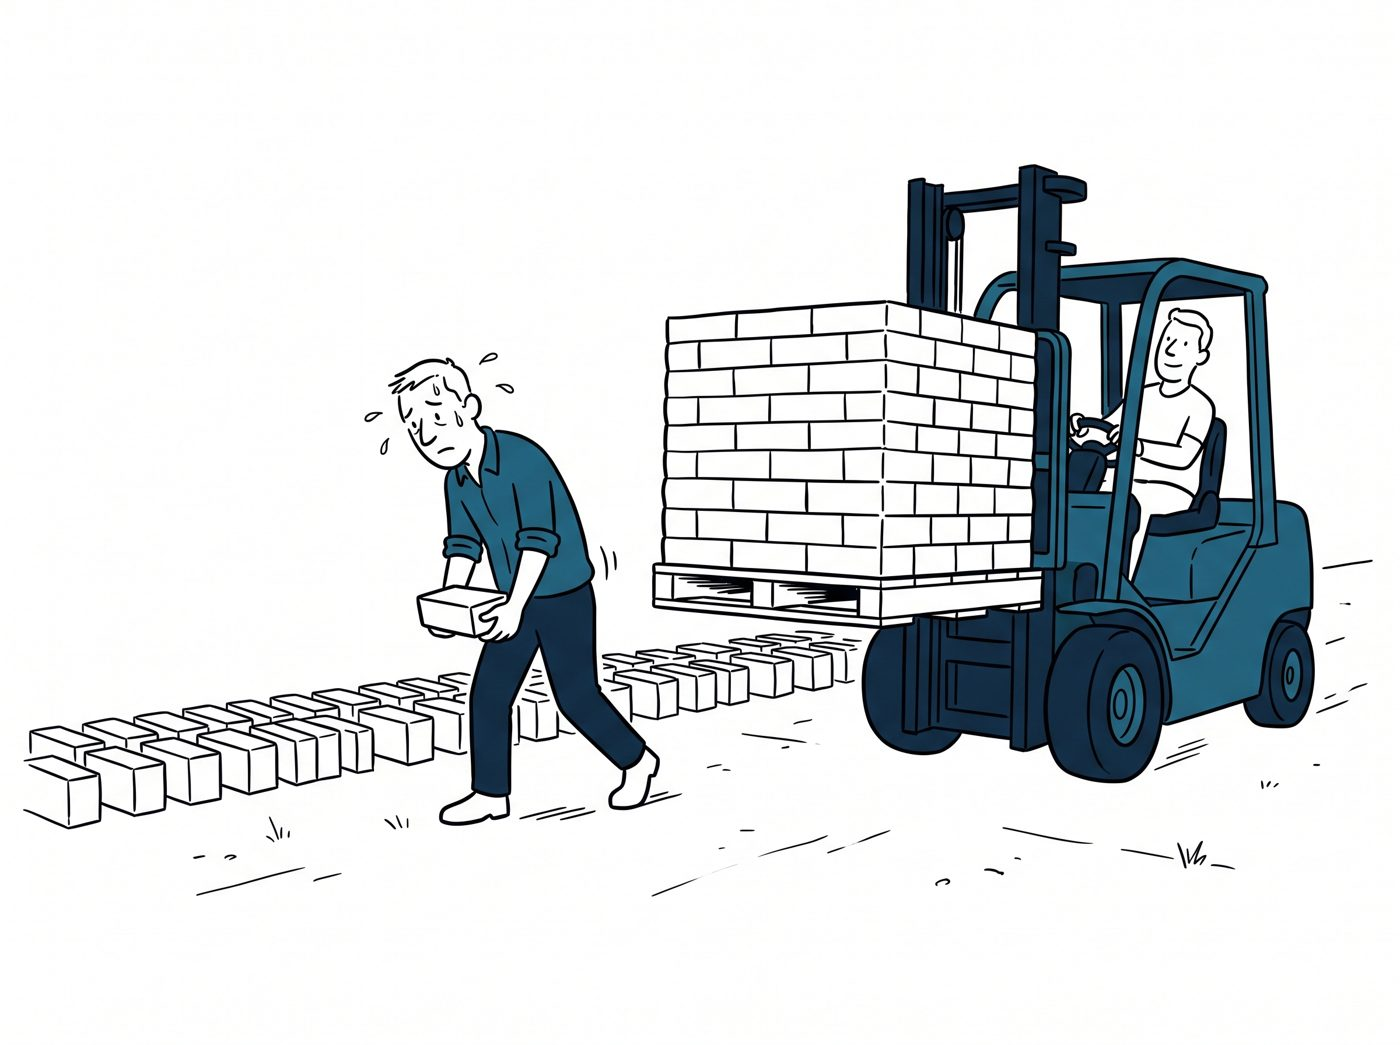<div style="text-align:center; color:#475569; font-size:0.92em; line-height:1.4; margin:-4px auto 14px; max-width:70%;">Die Python-Schleife trägt jede Zahl einzeln: Objekt holen, Typ prüfen, rechnen, Ergebnis ablegen. NumPy hebt den ganzen Block auf einmal, die Schleife läuft in kompiliertem Code über zusammenhängenden Speicher.</div></div>

### <a id="kap-wie-die-zahlen-im-speicher-liegen"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:1px solid rgba(21,96,130,0.45); padding-bottom:2px;  padding-top:16px;">3.3.1&nbsp;&nbsp;Wie die Zahlen im Speicher liegen</span>

`E` ist die Matrix, die die Embedding-Vektoren unserer Kursdaten speichert, also der 400 Wikipedia-Absätze: 400 Zeilen, eine je Absatz, mit je 384 Zahlen für den Embedding-Vektor. Die Grafik zeigt, wie dieses Array im Speicher liegt, die Zelle darunter liest die Beschreibung aus, und die Tabelle danach fasst alle Attribute zusammen.

In [ ]:
print(type(E))
print("Form:", E.shape)
print("Datentyp:", E.dtype, "mit", E.itemsize, "Bytes je Eintrag")
print("Achsen:", E.ndim, "  Einträge:", E.size, "  Bytes:", E.nbytes)
print("Abstände:", E.strides)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #008000">type</span>(E))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">shape</code> ist die Form als Tupel: Anzahl der Zeilen, Anzahl der Spalten</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"Form:"</span>, E<span style="color: #666">.</span>shape)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">dtype</code> ist der Datentyp aller Einträge, <code style="color:inherit;">itemsize</code> sein Speicherbedarf je Eintrag in Bytes</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"Datentyp:"</span>, E<span style="color: #666">.</span>dtype, <span style="color: #BA2121">"mit"</span>, E<span style="color: #666">.</span>itemsize, <span style="color: #BA2121">"Bytes je Eintrag"</span>)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; <code style="color:inherit;">ndim</code> ist die Anzahl der Achsen, <code style="color:inherit;">size</code> die Anzahl der Einträge, <code style="color:inherit;">nbytes</code> der Speicher für alle Einträge</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"Achsen:"</span>, E<span style="color: #666">.</span>ndim, <span style="color: #BA2121">"  Einträge:"</span>, E<span style="color: #666">.</span>size, <span style="color: #BA2121">"  Bytes:"</span>, E<span style="color: #666">.</span>nbytes)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>④</b>&nbsp; <code style="color:inherit;">strides</code> sind die Abstände in Bytes zum nächsten Eintrag, je Achse einer</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"Abstände:"</span>, E<span style="color: #666">.</span>strides)</code></pre></details>

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Die Beschreibung eines Arrays</span></div>
<p>Alle Angaben der Beschreibung lassen sich als Attribute abfragen. Die rechte Spalte zeigt die Werte für <code style="color:inherit;">E</code>.</p>
<table style="table-layout:fixed; width:100%;"><colgroup><col style="width:15%"><col><col style="width:22%"></colgroup>
<thead>
<tr>
<th>Attribut</th>
<th>Bedeutung</th>
<th>Bei <code style="color:inherit;">E</code></th>
</tr>
</thead>
<tbody>
<tr>
<td><code style="color:inherit;">shape</code></td>
<td>Form: ein Tupel mit einer Länge je Achse</td>
<td><code style="color:inherit;">(400, 384)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">ndim</code></td>
<td>Anzahl der Achsen, also die Länge von <code style="color:inherit;">shape</code></td>
<td><code style="color:inherit;">2</code></td>
</tr>
<tr>
<td><code style="color:inherit;">dtype</code></td>
<td>der gemeinsame Datentyp des Arrays; bei unseren numerischen Arrays der Typ jedes einzelnen Zahlenwerts. <code style="color:inherit;">np.array([1, 2.5])</code> wird deshalb ganz zu <code style="color:inherit;">float64</code></td>
<td><code style="color:inherit;">float32</code></td>
</tr>
<tr>
<td><code style="color:inherit;">itemsize</code></td>
<td>Bytes je Eintrag</td>
<td><code style="color:inherit;">4</code></td>
</tr>
<tr>
<td><code style="color:inherit;">size</code></td>
<td>Anzahl der Einträge, das Produkt der Längen in <code style="color:inherit;">shape</code></td>
<td><code style="color:inherit;">153600</code></td>
</tr>
<tr>
<td><code style="color:inherit;">nbytes</code></td>
<td>Bytes für alle Einträge, <code style="color:inherit;">size</code> mal <code style="color:inherit;">itemsize</code></td>
<td><code style="color:inherit;">614400</code></td>
</tr>
<tr>
<td><code style="color:inherit;">strides</code></td>
<td>Abstand in Bytes zum nächsten Eintrag, je Achse einer</td>
<td><code style="color:inherit;">(1536, 4)</code></td>
</tr>
</tbody>
</table>
<p>Die Form ist ein Tupel, deshalb steht sie mit Klammern und Kommas: <code style="color:inherit;">(400, 384)</code> für zwei Achsen, <code style="color:inherit;">(384,)</code> für eine Achse mit 384 Einträgen (das Komma unterscheidet das Tupel von der eingeklammerten Zahl <code style="color:inherit;">(384)</code>) und <code style="color:inherit;">()</code> für eine einzelne Zahl ohne Achse. Beim Vergleichen von Formen, etwa in Prüfzellen, steht deshalb immer ein Tupel: <code style="color:inherit;">result.shape == (2,)</code>.</p>

</div>

**Die Abstände.** Die Zahlen von `E` liegen zeilenweise hintereinander: erst die 384 Zahlen der Zeile 0, direkt dahinter die 384 Zahlen der Zeile 1 und so weiter. Um von `E[0, 0]` zu `E[0, 1]` zu kommen, geht NumPy 4 Bytes weiter, eine Zahl. Um von `E[0, 0]` zu `E[1, 0]` zu kommen, überspringt es eine ganze Zeile, 384 mal 4 = 1536 Bytes. Diese beiden Abstände sind die `strides` `(1536, 4)`. Mit ihnen berechnet NumPy aus jedem Indexpaar `(i, j)` die Speicheradresse des Eintrags: Adresse des Blocks plus `i * 1536 + j * 4`. Deshalb ist der Zugriff auf eine Spalte genauso einfach wie der auf eine Zeile, ein Ausdruck ohne Schleife und ohne Kopie, es ändert sich nur der Abstand. Ob das Lesen einer Spalte auch gleich schnell ist, hängt davon ab, wie die Zahlen im Speicher verteilt liegen (Kapitel <a href="#kap-sicht-oder-kopie">3.7</a>). Und deshalb kann eine zweite Beschreibung denselben Block anders lesen, ohne eine Zahl zu kopieren: `E.T`, das transponierte `E` mit vertauschten Zeilen und Spalten (Kapitel <a href="#kap-formen-aendern-transponieren-und-umformen">3.3.5</a>), ist nichts anderes als `E` mit vertauschten Abständen `(4, 1536)`. Was daraus folgt, behandelt das Kapitel <a href="#kap-sicht-oder-kopie">3.7</a>.

Die 614.400 Bytes sind die Zahl aus der Schätzaufgabe der letzten Lerneinheit: 400 mal 384 Zahlen zu je 4 Bytes. Als Python-Listen belegten dieselben Zahlen das Achtfache an Speicherplatz, weil dort jede Zahl ein eigenes Objekt ist und die Liste nur Verweise darauf enthält.

**Zwei Bedeutungen von „Dimension".** Ein Embedding-Vektor hat 384 Komponenten, man sagt auch, er ist 384-dimensional. Als Array liegt er trotzdem mit einer einzigen Achse vor, `ndim` ist 1: Bei „384-dimensional" meint Dimension die Anzahl der Komponenten, bei `ndim` die Anzahl der Achsen. Erst 400 Embedding-Vektoren untereinander ergeben zwei Achsen, die Form `(400, 384)`. Was eine Achse bedeutet, steht nirgends im Array. Es ergibt sich daraus, wie wir die Daten abgelegt haben: Beim Erzeugen der Datei wurde je Absatz eine Zeile geschrieben, deshalb zählt Achse 0 die Absätze und Achse 1 die Komponenten. NumPy kennt diese Bedeutung nicht, es kennt nur zwei Achsen mit den Längen 400 und 384 und führt jede Operation auf der Achse aus, die der Code nennt. Die Verantwortung, die richtige Achse zu nennen, liegt beim Programm. Genau dafür steht in diesem Notebook nach jeder wichtigen Zelle die Formenzeile.

**Ein Datentyp für alle Einträge.** Anders als eine Python-Liste hat ein Array genau einen Datentyp, und zwar für alle Einträge zusammen; nur so kann NumPy jeden Eintrag über den Abstand finden, ohne nachzusehen, was dort liegt. Aus einer gemischten Liste wie `[1, "Text"]` macht `np.array` deshalb stillschweigend ein Array aus Zeichenketten, die 1 wird zu `"1"`. Verschiedene Typen nebeneinander gibt es auf zwei Wegen, die beide bei einem Typ je Array bleiben: Ein strukturiertes Array hat einen zusammengesetzten Datentyp mit benannten Feldern, etwa `dtype=[("nr", "i4"), ("titel", "U10"), ("score", "f4")]`; jeder Eintrag ist dann ein kleiner Datensatz mit festem Aufbau wie ein `struct` in C, und `a["titel"]` liefert die Spalte. Und ein Array vom Typ `object` enthält Verweise auf beliebige Python-Objekte, wie eine Liste, ohne den Geschwindigkeitsvorteil (Vertiefung zu den Datentypen in Kapitel <a href="#kap-arrays-anlegen-zugriff-und-slicing">3.3.3</a>). Für Tabellen mit Spalten verschiedenen Typs, etwa Titel und Zahlen nebeneinander, ist in der Praxis pandas die übliche Wahl (Kapitel <a href="#kap-der-python-data-science-werkzeugkasten">3.4</a>).

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Wie NumPy aufgebaut ist</span></div>
<p>NumPy wird als <code style="color:inherit;">np</code> importiert und besteht aus wenigen Bausteinen, die in diesem Notebook immer wieder vorkommen. Die Beispiele in der Tabelle sind eine Vorschau; jedes wird in den folgenden Abschnitten eingeführt.</p>
<table>
<thead>
<tr>
<th>Baustein</th>
<th>Beispiele</th>
<th>Anmerkung</th>
</tr>
</thead>
<tbody>
<tr>
<td>die Klasse <code style="color:inherit;">ndarray</code></td>
<td><code style="color:inherit;">E</code>, <code style="color:inherit;">Q</code>, mit <code style="color:inherit;">np.array</code> erzeugte Arrays, mit <code style="color:inherit;">np.load</code> aus <code style="color:inherit;">.npy</code>-Dateien geladene Arrays</td>
<td>das Array. Attribute wie <code style="color:inherit;">E.shape</code> beschreiben es, Methoden wie <code style="color:inherit;">E.sum()</code> rechnen auf ihm (bei <code style="color:inherit;">.npz</code> liefert <code style="color:inherit;">np.load</code> ein Archivobjekt, aus dem die Arrays einzeln entnommen werden)</td>
</tr>
<tr>
<td>Funktionen in <code style="color:inherit;">np</code></td>
<td><code style="color:inherit;">np.array(...)</code>, <code style="color:inherit;">np.zeros(...)</code>, <code style="color:inherit;">np.sqrt(x)</code>, <code style="color:inherit;">np.allclose(a, b)</code></td>
<td>Arrays erzeugen, elementweise rechnen, vergleichen</td>
</tr>
<tr>
<td>Methode und Funktion mit derselben Aufgabe</td>
<td><code style="color:inherit;">E.sum(axis=1)</code> und <code style="color:inherit;">np.sum(E, axis=1)</code></td>
<td>viele Operationen gibt es in beiden Schreibweisen mit demselben Ergebnis. Für Reduktionen wie <code style="color:inherit;">sum</code> und <code style="color:inherit;">max</code> verwenden wir die Methode, für Werkzeuge wie <code style="color:inherit;">np.any</code>, <code style="color:inherit;">np.argsort</code> und <code style="color:inherit;">np.allclose</code> die Funktion</td>
</tr>
<tr>
<td>Unterpakete</td>
<td><code style="color:inherit;">np.linalg.norm(E, axis=1)</code>, <code style="color:inherit;">np.random.default_rng(42)</code></td>
<td>Funktionsgruppen mit eigenem Namensraum: lineare Algebra (<code style="color:inherit;">linalg</code>) und Zufallszahlen (<code style="color:inherit;">random</code>) kommen im Kurs vor, die übrigen zählt die Vertiefung unten auf</td>
</tr>
<tr>
<td>Datentypen</td>
<td><code style="color:inherit;">np.float32</code>, <code style="color:inherit;">np.int64</code></td>
<td>die Werte für <code style="color:inherit;">dtype=</code> und <code style="color:inherit;">astype</code></td>
</tr>
</tbody>
</table>
<p>Im Notebook zeigt <code style="color:inherit;">np.sum?</code> die Beschreibung einer Funktion an, wie in Grundkurs Teil 2 eingeführt. Die vollständige Dokumentation steht auf numpy.org.</p>

</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right"><span style="border:1px solid rgba(255,255,255,0.85); color:#fff; font-size:0.72em; font-weight:bold; padding:1px 9px; border-radius:10px; margin-left:8px; vertical-align:1px;">NICHT PRÜFUNGSRELEVANT</span></span>Vertiefung: Die Unterpakete von NumPy</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>NumPy gliedert Funktionen für ein Fachgebiet in Unterpakete, die über <code style="color:inherit;">np.&lt;name&gt;.</code> erreichbar sind. Im Kurs brauchen Sie <code style="color:inherit;">np.linalg</code> und <code style="color:inherit;">np.random</code>; die anderen sollen Sie einordnen können, wenn sie Ihnen in fremdem Code begegnen.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#107C72; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #107C7255"><table>
<thead>
<tr>
<th>Unterpaket</th>
<th>Inhalt</th>
<th>Beispiel</th>
</tr>
</thead>
<tbody>
<tr>
<td><code style="color:inherit;">np.linalg</code></td>
<td>lineare Algebra: Normen, Determinanten, Gleichungssysteme lösen, Matrixzerlegungen</td>
<td><code style="color:inherit;">np.linalg.norm(E, axis=1)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">np.random</code></td>
<td>Zufallszahlen aus verschiedenen Verteilungen mit festem Startwert (Seed)</td>
<td><code style="color:inherit;">np.random.default_rng(42).standard_normal((N, D))</code></td>
</tr>
<tr>
<td><code style="color:inherit;">np.fft</code></td>
<td>schnelle Fourier-Transformation: ein Signal in seine Frequenzanteile zerlegen (Audio, Bilder)</td>
<td><code style="color:inherit;">np.fft.fft(signal)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">np.polynomial</code></td>
<td>Polynome anlegen, auswerten, an Daten anpassen</td>
<td><code style="color:inherit;">np.polynomial.Polynomial.fit(x, y, 2)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">np.ma</code></td>
<td>maskierte Arrays: Rechnen mit fehlenden Werten</td>
<td><code style="color:inherit;">np.ma.masked_invalid(x).mean()</code></td>
</tr>
<tr>
<td><code style="color:inherit;">np.testing</code></td>
<td>Vergleichsfunktionen für Tests, mit lesbaren Fehlermeldungen</td>
<td><code style="color:inherit;">np.testing.assert_allclose(a, b)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">np.lib.stride_tricks</code></td>
<td>Sichten mit frei gewählten Abständen, etwa gleitende Fenster</td>
<td><code style="color:inherit;">sliding_window_view(x, 3)</code></td>
</tr>
</tbody>
</table>
<p>Was nicht in NumPy steckt, liefert SciPy auf derselben Array-Basis: Optimierung, Statistik, Signalverarbeitung, dünn besetzte Matrizen (Kapitel <a href="#kap-der-python-data-science-werkzeugkasten">3.4</a>).</p></div></details>
</div>
</div>

### <a id="kap-vom-einzelwert-zum-tensor"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:1px solid rgba(21,96,130,0.45); padding-bottom:2px;  padding-top:16px;">3.3.2&nbsp;&nbsp;Vom Einzelwert zum Tensor</span>

Das Wort „Tensor" steht im Namen dieses Kurses und im Namen der wichtigsten Klasse von PyTorch. Bevor es um das Rechnen mit Arrays geht, gehört deshalb geklärt, was ein Tensor ist und warum NumPy-Arrays schon welche sind.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#C62828; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Definition: Tensor</div>
<div style="background:#FDECEA; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Ein Tensor ist eine Anordnung von Zahlen gleichen Typs, in der jeder Eintrag durch ein festes Tupel von Indizes bestimmt ist. Die Anzahl der Indizes heißt Stufe (auch Ordnung; in manchen Texten „Rang", gemeint ist dann die Anzahl der Achsen, nicht der Matrixrang aus der linearen Algebra) des Tensors: Ein Skalar (eine einzelne Zahl) hat die Stufe 0, ein Vektor die Stufe 1, eine Matrix die Stufe 2. In NumPy ist ein Tensor der Stufe k ein Array mit <code style="color:inherit;">ndim == k</code>; seine Form gibt für jeden Index an, wie viele Werte er annehmen kann.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#C62828; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #C6282855"><p>In der Schreibweise der Mathematik: Ein Tensor der Stufe k mit der Form (n₁, …, nₖ) ist eine Abbildung, die jedem Indextupel eine reelle Zahl zuordnet,</p>


$$T \in \mathbb{R}^{n_1 \times n_2 \times \dots \times n_k}, \qquad T_{i_1 i_2 \dots i_k} \in \mathbb{R}$$


<p>mit 0 ≤ iₘ &lt; nₘ für jeden Index m. Die Mathematik schreibt die Indizes tiefgestellt, NumPy in eckigen Klammern: <code style="color:inherit;">T[i_1, i_2, ..., i_k]</code>. Die Stufen im Einzelnen:</p>
<ul>
<li><strong>Skalar, Stufe 0:</strong> eine einzelne Zahl, Form <code style="color:inherit;">()</code>. Beispiel: die Länge eines Vektors.</li>
<li><strong>Vektor, Stufe 1:</strong> Zahlen entlang einer Achse, der Eintrag <code style="color:inherit;">v[j]</code> ist durch einen Index bestimmt. Beispiel: ein Embedding-Vektor, Form <code style="color:inherit;">(384,)</code>.</li>
<li><strong>Matrix, Stufe 2:</strong> Zahlen in Zeilen und Spalten, der Eintrag <code style="color:inherit;">E[i, j]</code> braucht zwei Indizes. Beispiel: die Absatzmatrix, Form <code style="color:inherit;">(400, 384)</code>.</li>
<li><strong>Tensor der Stufe 3:</strong> ein Stapel aus Matrizen, der Eintrag <code style="color:inherit;">T[b, i, j]</code> braucht drei Indizes. Beispiel: je eine Matrix pro Anfrage, Form <code style="color:inherit;">(8, 400, 384)</code>.</li>
<li><strong>Höhere Stufen:</strong> so geht es weiter. Ein Stapel aus Farbbildern hat beispielsweise die Form <code style="color:inherit;">(Anzahl, Höhe, Breite, Farbkanäle)</code>, vier Indizes.</li>
</ul>
<p>In der Physik und der Differentialgeometrie gehört zur Definition zusätzlich, wie sich die Einträge bei einem Wechsel des Koordinatensystems verhalten. Davon brauchen die KI-Bibliotheken nichts: Dort heißt jedes mehrdimensionale Array Tensor, in NumPy <code style="color:inherit;">ndarray</code>, in PyTorch <code style="color:inherit;">Tensor</code>, und gemeint ist dasselbe Objekt aus Block und Beschreibung. Das Denken in Formen und Achsen, das Sie in dieser Lerneinheit lernen, lässt sich unverändert auf PyTorch übertragen; bei einzelnen Funktionen prüfen wir dort Parameter und Voreinstellungen erneut, denn <code style="color:inherit;">std</code> etwa rechnet in NumPy und PyTorch mit verschiedenen Voreinstellungen.</p></div></details>
</div>
</div>

In NumPy ist diese Stufenleiter kein Unterschied in der Art des Objekts. Vektor, Matrix und höherer Tensor sind dasselbe `ndarray`, sie unterscheiden sich nur in `ndim` und `shape`; selbst eine einzelne Zahl lässt sich mit `np.array(5.0)` als Array mit null Achsen anlegen. Attribute wie `shape` und `dtype` und die elementweisen Rechenregeln gelten auf allen Stufen gleich. Operationen mit Achsenangabe oder das Matrixprodukt brauchen dagegen passende Formen, ein Vektor hat zum Beispiel keine Achse 1. Die nächste Zelle baut die vier Stufen aus den Kursdaten. Ein Einzelzugriff wie `E[0, 0]` liefert übrigens kein Array, sondern einen NumPy-Skalar vom Typ `np.float32`; er trägt dieselben Attribute, deshalb zeigt die Zelle den Unterschied mit `type`.

In [ ]:
scalar = np.array(E[0, 0])       # eine einzelne Zahl aus E, als Array der Stufe 0
vector = E[0]                    # Zeile 0: der Embedding-Vektor des ersten Absatzes
matrix = E                       # alle 400 Vektoren
stack = np.stack([E, E])         # zwei Kopien von E übereinander: Stufe 3
for name, arr in [("Skalar", scalar), ("Vektor", vector), ("Matrix", matrix), ("Tensor Stufe 3", stack)]:
    print(f"{name:15s} ndim = {arr.ndim}   shape = {str(arr.shape):15s} {type(arr).__name__}")
print(type(E[0, 0]).__name__, "<- der Einzelzugriff liefert einen NumPy-Skalar, kein Array")
# Formen: np.array(E[0, 0]) ();  E[0] (384,);  E (400, 384);  np.stack([E, E]) (2, 400, 384)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">np.array(zahl)</code> legt ein Array mit null Achsen an; <code style="color:inherit;">E[0, 0]</code> allein wäre ein NumPy-Skalar (<code style="color:inherit;">np.float32</code>)</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">scalar <span style="color: #666">=</span> np<span style="color: #666">.</span>array(E[<span style="color: #666">0</span>, <span style="color: #666">0</span>])       <span style="color: #3D7B7B; font-style: italic"># eine einzelne Zahl aus E, als Array der Stufe 0</span>
vector <span style="color: #666">=</span> E[<span style="color: #666">0</span>]                    <span style="color: #3D7B7B; font-style: italic"># Zeile 0: der Embedding-Vektor des ersten Absatzes</span>
matrix <span style="color: #666">=</span> E                       <span style="color: #3D7B7B; font-style: italic"># alle 400 Vektoren</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">np.stack</code> legt gleich geformte Arrays entlang einer neuen ersten Achse übereinander</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">stack <span style="color: #666">=</span> np<span style="color: #666">.</span>stack([E, E])         <span style="color: #3D7B7B; font-style: italic"># zwei Kopien von E übereinander: Stufe 3</span>
<span style="color: #008000; font-weight: bold">for</span> name, arr <span style="color: #A2F; font-weight: bold">in</span> [(<span style="color: #BA2121">"Skalar"</span>, scalar), (<span style="color: #BA2121">"Vektor"</span>, vector), (<span style="color: #BA2121">"Matrix"</span>, matrix), (<span style="color: #BA2121">"Tensor Stufe 3"</span>, stack)]:
    <span style="color: #008000">print</span>(<span style="color: #BA2121">f"</span><span style="color: #A45A77; font-weight: bold">{</span>name<span style="color: #A45A77; font-weight: bold">:</span><span style="color: #BA2121">15s</span><span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> ndim = </span><span style="color: #A45A77; font-weight: bold">{</span>arr<span style="color: #666">.</span>ndim<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">   shape = </span><span style="color: #A45A77; font-weight: bold">{</span><span style="color: #008000">str</span>(arr<span style="color: #666">.</span>shape)<span style="color: #A45A77; font-weight: bold">:</span><span style="color: #BA2121">15s</span><span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> </span><span style="color: #A45A77; font-weight: bold">{</span><span style="color: #008000">type</span>(arr)<span style="color: #666">.</span><span style="color: #19177C">__name__</span><span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">"</span>)
<span style="color: #008000">print</span>(<span style="color: #008000">type</span>(E[<span style="color: #666">0</span>, <span style="color: #666">0</span>])<span style="color: #666">.</span><span style="color: #19177C">__name__</span>, <span style="color: #BA2121">"&lt;- der Einzelzugriff liefert einen NumPy-Skalar, kein Array"</span>)
<span style="color: #3D7B7B; font-style: italic"># Formen: np.array(E[0, 0]) ();  E[0] (384,);  E (400, 384);  np.stack([E, E]) (2, 400, 384)</span></code></pre></details>

<div style="border-left:5px solid #1F5FB0; background:#EAF1FB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<p><strong>„Tensor Thinking": Rechnungen über Formen planen, bevor Code entsteht.</strong> Statt zu fragen „Welche Schleife läuft über welchen Index?", fragen Sie „Welche Form hat die Eingabe, welche Form soll das Ergebnis haben, und welche Operation führt von der einen zur anderen?". Die Schleifen stecken dann in den Achsen.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#1F5FB0; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #1F5FB055"><p>Dieser Denkschritt zieht sich durch die ganze Lerneinheit, und die Formenzeile hält ihn in jeder Zelle fest. Aus „für jeden Absatz die Länge seines Vektors" wird <code style="color:inherit;">E (400, 384) -&gt; (400,)</code>: eine Operation, die die zweite Achse zusammenfasst (sie heißt gleich Reduktion). Aus „die Ähnlichkeit jeder Anfrage zu jedem Absatz" wird <code style="color:inherit;">(8, 384) @ (384, 400) -&gt; (8, 400)</code>: eine einzige Operation statt zweier Schleifen, der Operator <code style="color:inherit;">@</code> kommt im Kapitel <a href="#kap-broadcasting-und-unser-semester-operator">3.5</a>. In PyTorch planen Sie später jede Schicht eines neuronalen Netzes genau so, über die Formen der Tensoren, die hinein- und herausgehen.</p></div></details>
</div>

### <a id="kap-arrays-anlegen-zugriff-und-slicing"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:1px solid rgba(21,96,130,0.45); padding-bottom:2px;  padding-top:16px;">3.3.3&nbsp;&nbsp;Arrays anlegen, Zugriff und Slicing</span>

**Arrays anlegen.** Die Kursdaten kommen fertig aus `np.load`. Eigene Arrays brauchen Sie trotzdem laufend: für die kleinen Testfälle der Prüfzellen, für Zufallsdaten beim Messen und für Ergebnisse, die Stück für Stück gefüllt werden. `np.array` baut aus einer Liste ein Array und wählt den Datentyp nach den Werten: Ganzzahlen ergeben `int64`, Fließkommazahlen `float64`. Mit `dtype=` legen Sie den Typ selbst fest. Die Kursdaten sind ausdrücklich als `float32` gespeichert, das halbiert den Speicher gegenüber `float64` und ist in KI-Bibliotheken der übliche Typ. `astype` wandelt ein vorhandenes Array in einen anderen Typ um, zum Beispiel Zufallszahlen, die als `float64` entstehen, in das `float32`, das der Operator verlangt. `np.zeros` legt ein Array mit Nullen in einer gewünschten Form an, `np.arange` zählt wie `range`.

In [ ]:
print(np.array([1, 2]).dtype, np.array([1.0, 2.0]).dtype)
x = np.array([[3.0, 4.0], [0.0, 2.0]], dtype=np.float32)       # zwei Zeilen, zwei Spalten
print(x.shape, x.dtype)
print(np.array([1, 2]).astype(np.float32).dtype)
print(np.zeros((2, 3), dtype=np.float32))
print(np.arange(6))

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(np<span style="color: #666">.</span>array([<span style="color: #666">1</span>, <span style="color: #666">2</span>])<span style="color: #666">.</span>dtype, np<span style="color: #666">.</span>array([<span style="color: #666">1.0</span>, <span style="color: #666">2.0</span>])<span style="color: #666">.</span>dtype)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">dtype=np.float32</code> legt den Typ beim Anlegen fest</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">x <span style="color: #666">=</span> np<span style="color: #666">.</span>array([[<span style="color: #666">3.0</span>, <span style="color: #666">4.0</span>], [<span style="color: #666">0.0</span>, <span style="color: #666">2.0</span>]], dtype<span style="color: #666">=</span>np<span style="color: #666">.</span>float32)       <span style="color: #3D7B7B; font-style: italic"># zwei Zeilen, zwei Spalten</span>
<span style="color: #008000">print</span>(x<span style="color: #666">.</span>shape, x<span style="color: #666">.</span>dtype)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">astype</code> liefert ein neues Array im gewünschten Typ</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(np<span style="color: #666">.</span>array([<span style="color: #666">1</span>, <span style="color: #666">2</span>])<span style="color: #666">.</span>astype(np<span style="color: #666">.</span>float32)<span style="color: #666">.</span>dtype)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; <code style="color:inherit;">np.zeros((2, 3), dtype=...)</code> legt ein Array der Form (2, 3) mit Nullen an, die Form ist ein Tupel</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(np<span style="color: #666">.</span>zeros((<span style="color: #666">2</span>, <span style="color: #666">3</span>), dtype<span style="color: #666">=</span>np<span style="color: #666">.</span>float32))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>④</b>&nbsp; <code style="color:inherit;">np.arange(6)</code> zählt von 0 bis 5 wie <code style="color:inherit;">range(6)</code>, liefert aber ein Array</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(np<span style="color: #666">.</span>arange(<span style="color: #666">6</span>))</code></pre></details>

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Arrays anlegen</span></div>
<table style="table-layout:fixed; width:100%;"><colgroup><col style="width:35%"><col style="width:27%"><col style="width:38%"></colgroup>
<thead>
<tr>
<th>Aufruf</th>
<th>Was entsteht</th>
<th>Beispielergebnis</th>
</tr>
</thead>
<tbody>
<tr>
<td><code style="color:inherit;">np.array([[3., 4.], [0., 2.]], dtype=np.float32)</code></td>
<td>Array aus einer Liste von Listen, Typ ausdrücklich</td>
<td><code style="color:inherit;">[[3., 4.], [0., 2.]]</code>, Form <code style="color:inherit;">(2, 2)</code>, <code style="color:inherit;">float32</code></td>
</tr>
<tr>
<td><code style="color:inherit;">np.zeros((2, 3), dtype=np.float32)</code></td>
<td>Nullen in der angegebenen Form; <code style="color:inherit;">np.ones</code> entsprechend mit Einsen</td>
<td><code style="color:inherit;">[[0., 0., 0.], [0., 0., 0.]]</code></td>
</tr>
<tr>
<td><code style="color:inherit;">np.arange(6)</code></td>
<td>Ganzzahlen von 0 bis 5 wie <code style="color:inherit;">range</code></td>
<td><code style="color:inherit;">[0, 1, 2, 3, 4, 5]</code></td>
</tr>
<tr>
<td><code style="color:inherit;">np.linspace(0, 1, 5)</code></td>
<td>fünf gleichmäßig verteilte Werte von 0 bis 1 einschließlich</td>
<td><code style="color:inherit;">[0., 0.25, 0.5, 0.75, 1.]</code></td>
</tr>
<tr>
<td><code style="color:inherit;">np.load("data/x.npy")</code></td>
<td>Array aus einer <code style="color:inherit;">.npy</code>-Datei, Form und Typ aus der Datei</td>
<td><code style="color:inherit;">E</code> mit <code style="color:inherit;">(400, 384)</code>, <code style="color:inherit;">float32</code></td>
</tr>
<tr>
<td><code style="color:inherit;">rng = np.random.default_rng(42)</code>, <code style="color:inherit;">rng.standard_normal((2, 3))</code></td>
<td>Zufallszahlen mit festem Startwert, Typ <code style="color:inherit;">float64</code></td>
<td><code style="color:inherit;">[[0.30, -1.04, 0.75], [0.94, -1.95, -1.30]]</code></td>
</tr>
<tr>
<td><code style="color:inherit;">x.astype(np.float32)</code></td>
<td>dieselben Werte in einem anderen Typ, standardmäßig als neues Array</td>
<td>aus <code style="color:inherit;">[1, 2]</code> (<code style="color:inherit;">int64</code>) wird <code style="color:inherit;">[1., 2.]</code> (<code style="color:inherit;">float32</code>)</td>
</tr>
</tbody>
</table>

</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Vertiefung: Die Datentypen von NumPy</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Im Kurs genügen <code style="color:inherit;">float32</code> für Daten und Rechnungen, <code style="color:inherit;">float64</code> als Python-Standard, <code style="color:inherit;">int64</code> für Positionen und <code style="color:inherit;">bool</code> für Masken. NumPy kennt darüber hinaus eine ganze Familie von Typen mit fester Bitbreite, wie Sie sie aus C kennen.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#107C72; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #107C7255"><table>
<thead>
<tr>
<th>Typ</th>
<th>Speicher je Eintrag</th>
<th>Wertebereich bzw. Genauigkeit</th>
<th>Typischer Einsatz</th>
</tr>
</thead>
<tbody>
<tr>
<td><code style="color:inherit;">bool</code></td>
<td>1 Byte</td>
<td><code style="color:inherit;">True</code>, <code style="color:inherit;">False</code></td>
<td>Masken</td>
</tr>
<tr>
<td><code style="color:inherit;">int8</code>, <code style="color:inherit;">int16</code>, <code style="color:inherit;">int32</code>, <code style="color:inherit;">int64</code></td>
<td>1, 2, 4, 8 Bytes</td>
<td>ganze Zahlen mit Vorzeichen, <code style="color:inherit;">int8</code> von −128 bis 127</td>
<td>Positionen (Indexarrays verwenden <code style="color:inherit;">np.intp</code>, auf unseren 64-Bit-Systemen <code style="color:inherit;">int64</code>), Zähler, Pixelwerte</td>
</tr>
<tr>
<td><code style="color:inherit;">uint8</code> … <code style="color:inherit;">uint64</code></td>
<td>1 bis 8 Bytes</td>
<td>ganze Zahlen ohne Vorzeichen, <code style="color:inherit;">uint8</code> von 0 bis 255</td>
<td>Bilddaten (ein Farbkanal je Byte)</td>
</tr>
<tr>
<td><code style="color:inherit;">float16</code></td>
<td>2 Bytes</td>
<td>10 Mantissenbits, rund 3 signifikante Dezimalstellen, kleiner Exponentenbereich</td>
<td>Inferenz auf GPUs, Speicher sparen</td>
</tr>
<tr>
<td><code style="color:inherit;">bfloat16</code></td>
<td>2 Bytes</td>
<td>7 Mantissenbits, rund 2 signifikante Dezimalstellen, dafür der Exponentenbereich von <code style="color:inherit;">float32</code></td>
<td>Training mit gemischter Genauigkeit; in PyTorch eingebaut, in NumPy nur über Erweiterungen wie <code style="color:inherit;">ml_dtypes</code></td>
</tr>
<tr>
<td><code style="color:inherit;">float32</code></td>
<td>4 Bytes</td>
<td>rund 7 signifikante Dezimalstellen</td>
<td>Standard in KI-Bibliotheken, unsere Kursdaten</td>
</tr>
<tr>
<td><code style="color:inherit;">float64</code></td>
<td>8 Bytes</td>
<td>rund 16 signifikante Dezimalstellen</td>
<td>Python-<code style="color:inherit;">float</code>, wissenschaftliches Rechnen, Standard von <code style="color:inherit;">np.array([1.0])</code></td>
</tr>
<tr>
<td><code style="color:inherit;">complex64</code>, <code style="color:inherit;">complex128</code></td>
<td>8, 16 Bytes</td>
<td>komplexe Zahlen</td>
<td>Signalverarbeitung (<code style="color:inherit;">np.fft</code>)</td>
</tr>
<tr>
<td><code style="color:inherit;">str_</code></td>
<td>fest je Array, z. B. 12 Bytes je Eintrag bei <code style="color:inherit;">dtype="U3"</code> (3 Zeichen zu 4 Bytes)</td>
<td>Zeichenketten bis zu einer festen Länge</td>
<td>selten, Text gehört zu pandas</td>
</tr>
<tr>
<td><code style="color:inherit;">object</code></td>
<td>8 Bytes je Verweis, die Objekte selbst liegen außerhalb und zählen in <code style="color:inherit;">nbytes</code> nicht mit</td>
<td>beliebige Python-Objekte, auch gemischte Typen: <code style="color:inherit;">np.array([1, "Text"], dtype=object)</code></td>
<td>ein Feld von Verweisen wie eine Liste, ohne den Geschwindigkeitsvorteil</td>
</tr>
</tbody>
</table>
<p>Ganzzahltypen laufen bei Überschreitung des Wertebereichs stillschweigend über: <code style="color:inherit;">np.array([127], dtype=np.int8) + 1</code> ergibt <code style="color:inherit;">-128</code>. Bei Rechnungen zwischen zwei NumPy-Typen bestimmt NumPy den Ergebnistyp nach festen Regeln (Promotion): <code style="color:inherit;">int64</code> plus <code style="color:inherit;">float32</code> ergibt <code style="color:inherit;">float64</code>, wobei sehr große Ganzzahlen dabei ihre exakte Darstellung verlieren können. Für Python-Zahlen gilt: Ein Python-<code style="color:inherit;">float</code> lässt ein <code style="color:inherit;">float32</code>-Array bei <code style="color:inherit;">float32</code>, hebt ein Ganzzahlarray aber auf <code style="color:inherit;">float64</code> an; ein Python-<code style="color:inherit;">int</code> passt sich einem Ganzzahlarray an (Kapitel <a href="#kap-broadcasting-und-unser-semester-operator">3.5</a>). Die Grenzen eines Typs zeigen <code style="color:inherit;">np.finfo</code> für Fließkommatypen und <code style="color:inherit;">np.iinfo</code> für Ganzzahltypen an, zum Beispiel <code style="color:inherit;">np.finfo(np.float32)</code> und <code style="color:inherit;">np.iinfo(np.int8)</code>.</p></div></details>
</div>
</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E75B6; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Genau verstehen: astype kopiert standardmäßig</div>
<div style="background:#EAF2FA; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p><code style="color:inherit;">astype</code> legt in der Voreinstellung ein neues Array an, auch wenn der Zieltyp dem alten gleicht. Der Aufruf kostet also Speicher und Zeit in der Größe des Arrays, bei 100.000 Zeilen mit 384 Spalten rund 150 MB und spürbar Zeit. In Rechnungen, die oft laufen, legt man den Typ deshalb einmal beim Laden fest und wandelt danach nicht mehr um. Die Kursdaten sind aus diesem Grund als <code style="color:inherit;">float32</code> gespeichert, und der Operator verlangt <code style="color:inherit;">float32</code> statt stillschweigend umzuwandeln. Mit <code style="color:inherit;">astype(np.float32, copy=False)</code> gibt NumPy das vorhandene Array zurück, wenn der Typ schon passt, und kopiert nur im anderen Fall.</p>

</div>
</div>

**Zugriff und Slicing.** Bei einer Liste steht in den eckigen Klammern ein Index oder ein Slice. Bei einem Array steht dort ein Eintrag je Achse, durch Kommas getrennt: vor dem Komma die Zeilen, dahinter die Spalten. Für die Absatzmatrix `E` heißt das: `E[108]` ist der Vektor des Absatzes 108, eine Zeile. `E[108, 5]` ist seine Komponente 5, ein einzelner Eintrag. `E[:, 5]` ist die Komponente 5 aller 400 Absätze, eine Spalte; `:` allein heißt „alle Einträge dieser Achse". Der Zugriff auf eine Spalte ist damit genauso kurz geschrieben wie der auf eine Zeile, NumPy berechnet beide aus den Abständen. Für die Form des Ergebnisses gilt eine Regel, die Sie oft brauchen werden: Ein einzelner Index wählt einen Eintrag der Achse aus, und die Achse fällt aus der Form weg. Ein Slice wählt einen Bereich aus, und die Achse bleibt mit der Länge des Bereichs erhalten. `E[0]` hat deshalb die Form `(384,)` und `E[0:1]` die Form `(1, 384)`, obwohl beide dieselben 384 Zahlen enthalten. Der Unterschied spielt eine Rolle, sobald zwei Arrays verschiedener Form miteinander verrechnet werden (Kapitel <a href="#kap-broadcasting-und-unser-semester-operator">3.5</a>).

Zum Nachvollziehen mit Werten verwenden die nächsten Abschnitte neben `E` eine kleine Matrix `M` mit den Zahlen 1 bis 12 in drei Zeilen und vier Spalten. An ihr lässt sich jedes Ergebnis im Kopf prüfen.

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>Welche Form haben <code style="color:inherit;">E[5]</code>, <code style="color:inherit;">E[5:6]</code>, <code style="color:inherit;">E[:, :10]</code> und <code style="color:inherit;">E[::2]</code>? Begründen Sie jede Form mit der Regel „Index entfernt die Achse, Slice behält sie“, bevor Sie die nächste Zelle ausführen.</p>

</div>

In [ ]:
M = np.array([[1, 2, 3, 4],
              [5, 6, 7, 8],
              [9, 10, 11, 12]])          # Form (3, 4), zum Nachvollziehen
print(M[0], M[0].shape)                  # Zeile 0: der Index entfernt die Achse
print(M[0:1], M[0:1].shape)              # Zeile 0 als Slice: die Achse bleibt
print(M[:, 1])                           # Spalte 1: ein Eintrag je Zeile
print(M[1:, :2])                         # ab Zeile 1, die ersten zwei Spalten
print(E[0].shape, E[0:1].shape, E[:, 5].shape, E[:3, :2].shape)   # dasselbe an den Kursdaten
# Formen: M[0] (4,);  M[0:1] (1, 4);  M[:, 1] (3,);  M[1:, :2] (2, 2)
#         E[0] (384,);  E[0:1] (1, 384)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">M <span style="color: #666">=</span> np<span style="color: #666">.</span>array([[<span style="color: #666">1</span>, <span style="color: #666">2</span>, <span style="color: #666">3</span>, <span style="color: #666">4</span>],
              [<span style="color: #666">5</span>, <span style="color: #666">6</span>, <span style="color: #666">7</span>, <span style="color: #666">8</span>],
              [<span style="color: #666">9</span>, <span style="color: #666">10</span>, <span style="color: #666">11</span>, <span style="color: #666">12</span>]])          <span style="color: #3D7B7B; font-style: italic"># Form (3, 4), zum Nachvollziehen</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; vor dem Komma die Zeilen, dahinter die Spalten; <code style="color:inherit;">:</code> allein heißt „alle&quot;</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(M[<span style="color: #666">0</span>], M[<span style="color: #666">0</span>]<span style="color: #666">.</span>shape)                  <span style="color: #3D7B7B; font-style: italic"># Zeile 0: der Index entfernt die Achse</span>
<span style="color: #008000">print</span>(M[<span style="color: #666">0</span>:<span style="color: #666">1</span>], M[<span style="color: #666">0</span>:<span style="color: #666">1</span>]<span style="color: #666">.</span>shape)              <span style="color: #3D7B7B; font-style: italic"># Zeile 0 als Slice: die Achse bleibt</span>
<span style="color: #008000">print</span>(M[:, <span style="color: #666">1</span>])                           <span style="color: #3D7B7B; font-style: italic"># Spalte 1: ein Eintrag je Zeile</span>
<span style="color: #008000">print</span>(M[<span style="color: #666">1</span>:, :<span style="color: #666">2</span>])                         <span style="color: #3D7B7B; font-style: italic"># ab Zeile 1, die ersten zwei Spalten</span>
<span style="color: #008000">print</span>(E[<span style="color: #666">0</span>]<span style="color: #666">.</span>shape, E[<span style="color: #666">0</span>:<span style="color: #666">1</span>]<span style="color: #666">.</span>shape, E[:, <span style="color: #666">5</span>]<span style="color: #666">.</span>shape, E[:<span style="color: #666">3</span>, :<span style="color: #666">2</span>]<span style="color: #666">.</span>shape)   <span style="color: #3D7B7B; font-style: italic"># dasselbe an den Kursdaten</span>
<span style="color: #3D7B7B; font-style: italic"># Formen: M[0] (4,);  M[0:1] (1, 4);  M[:, 1] (3,);  M[1:, :2] (2, 2)</span>
<span style="color: #3D7B7B; font-style: italic">#         E[0] (384,);  E[0:1] (1, 384)</span></code></pre></details>

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Zugriff und Slicing</span></div>
<p>An <code style="color:inherit;">M</code> mit den Werten 1 bis 12 in der Form <code style="color:inherit;">(3, 4)</code>; für <code style="color:inherit;">E</code> mit <code style="color:inherit;">(400, 384)</code> gelten dieselben Regeln. Negative Indizes zählen wie bei Listen vom Ende her.</p>
<table>
<thead>
<tr>
<th>Ausdruck</th>
<th>Bedeutung</th>
<th>Ergebnis an <code style="color:inherit;">M</code></th>
<th>Form</th>
</tr>
</thead>
<tbody>
<tr>
<td><code style="color:inherit;">M[0]</code></td>
<td>Zeile 0, der Index entfernt die Achse</td>
<td><code style="color:inherit;">[1 2 3 4]</code></td>
<td><code style="color:inherit;">(4,)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">M[0:1]</code></td>
<td>Zeile 0 als Slice, die Achse bleibt</td>
<td><code style="color:inherit;">[[1 2 3 4]]</code></td>
<td><code style="color:inherit;">(1, 4)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">M[0, 2]</code></td>
<td>ein Eintrag: Zeile 0, Spalte 2</td>
<td><code style="color:inherit;">3</code></td>
<td><code style="color:inherit;">()</code></td>
</tr>
<tr>
<td><code style="color:inherit;">M[:, 1]</code></td>
<td>Spalte 1, ein Eintrag je Zeile</td>
<td><code style="color:inherit;">[2 6 10]</code></td>
<td><code style="color:inherit;">(3,)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">M[1:, :2]</code></td>
<td>ab Zeile 1, Spalten 0 und 1</td>
<td><code style="color:inherit;">[[5 6] [9 10]]</code></td>
<td><code style="color:inherit;">(2, 2)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">M[-1]</code></td>
<td>die letzte Zeile</td>
<td><code style="color:inherit;">[9 10 11 12]</code></td>
<td><code style="color:inherit;">(4,)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">M[::2]</code></td>
<td>jede zweite Zeile</td>
<td><code style="color:inherit;">[[1 2 3 4] [9 10 11 12]]</code></td>
<td><code style="color:inherit;">(2, 4)</code></td>
</tr>
</tbody>
</table>
<p>Ein Slice liefert bei Arrays keine neue Liste wie in Grundkurs Teil 2, sondern eine Sicht (View) auf denselben Datenblock. Was das bedeutet, zeigt das Kapitel <a href="#kap-sicht-oder-kopie">3.7</a>.</p>

</div>

### <a id="kap-achsen-und-reduktionen"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:1px solid rgba(21,96,130,0.45); padding-bottom:2px;  padding-top:16px;">3.3.4&nbsp;&nbsp;Achsen und Reduktionen</span>

Eine Reduktion fasst viele Werte zu einem zusammen: `sum` addiert, `max` nimmt den größten, `argmax` die Position des größten, `mean` bildet den Mittelwert. Für die Suche brauchen Sie Reduktionen an zwei Stellen: Die Länge eines Vektors ist die Wurzel aus der Summe seiner Quadrate, also eine Summe über die Komponenten, und das Skalarprodukt ist die Summe über die Produkte zweier Vektoren. Bei einer Matrix kommt die Frage dazu, in welche Richtung summiert wird: alle Einträge zu einer Zahl, die Zeilen aufeinander oder die Spalten nebeneinander. Das legt `axis=` fest. An `M` lässt sich jedes Ergebnis nachrechnen.

In [ ]:
print(M.sum(), M.sum().shape)            # alle Einträge: eine Zahl, Form ()
print(M.sum(axis=0))                     # Zeilen aufeinander: [1+5+9, 2+6+10, 3+7+11, 4+8+12]
print(M.sum(axis=1))                     # Spalten nebeneinander: [1+2+3+4, 5+6+7+8, 9+10+11+12]
print(M.sum(axis=1, keepdims=True))      # dieselben drei Werte als Spalte, Form (3, 1)
print(M.max(axis=1), M.argmax(axis=1))   # je Zeile: der größte Wert und seine Spalte
# Formen: M (3, 4) -> sum() ();  M (3, 4) -> sum(axis=0) (4,)
#         M (3, 4) -> sum(axis=1) (3,);  M (3, 4) -> sum(axis=1, keepdims=True) (3, 1)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(M<span style="color: #666">.</span>sum(), M<span style="color: #666">.</span>sum()<span style="color: #666">.</span>shape)            <span style="color: #3D7B7B; font-style: italic"># alle Einträge: eine Zahl, Form ()</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">axis=0</code> summiert entlang der Achse 0, <code style="color:inherit;">axis=1</code> entlang der Achse 1</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(M<span style="color: #666">.</span>sum(axis<span style="color: #666">=0</span>))                     <span style="color: #3D7B7B; font-style: italic"># Zeilen aufeinander: [1+5+9, 2+6+10, 3+7+11, 4+8+12]</span>
<span style="color: #008000">print</span>(M<span style="color: #666">.</span>sum(axis<span style="color: #666">=1</span>))                     <span style="color: #3D7B7B; font-style: italic"># Spalten nebeneinander: [1+2+3+4, 5+6+7+8, 9+10+11+12]</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">keepdims=True</code> behält die summierte Achse mit der Länge 1</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(M<span style="color: #666">.</span>sum(axis<span style="color: #666">=1</span>, keepdims<span style="color: #666">=</span><span style="color: #008000; font-weight: bold">True</span>))      <span style="color: #3D7B7B; font-style: italic"># dieselben drei Werte als Spalte, Form (3, 1)</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; <code style="color:inherit;">argmax</code> liefert die Position des größten Werts, <code style="color:inherit;">max</code> den Wert selbst</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(M<span style="color: #666">.</span>max(axis<span style="color: #666">=1</span>), M<span style="color: #666">.</span>argmax(axis<span style="color: #666">=1</span>))   <span style="color: #3D7B7B; font-style: italic"># je Zeile: der größte Wert und seine Spalte</span>
<span style="color: #3D7B7B; font-style: italic"># Formen: M (3, 4) -&gt; sum() ();  M (3, 4) -&gt; sum(axis=0) (4,)</span>
<span style="color: #3D7B7B; font-style: italic">#         M (3, 4) -&gt; sum(axis=1) (3,);  M (3, 4) -&gt; sum(axis=1, keepdims=True) (3, 1)</span></code></pre></details>

**Warum es darauf ankommt, ob die Achse bleibt.** `M.sum(axis=1)` und `M.sum(axis=1, keepdims=True)` enthalten dieselben drei Zahlen. Der Unterschied ist die Form, `(3,)` gegen `(3, 1)`, und die entscheidet darüber, wie das Ergebnis weiterverwendet werden kann. Ohne `keepdims` ist das Ergebnis ein gewöhnlicher Vektor mit einem Wert je Zeile: die richtige Form, um die Werte auszugeben, zu sortieren oder als Trefferliste zu verwenden. Mit `keepdims=True` behält das Ergebnis die Gestalt einer Spalte neben der Matrix: die richtige Form, wenn jede Zeile der Matrix mit „ihrem" Wert weiterverrechnet werden soll, etwa jede Zeile durch ihre eigene Länge geteilt. Warum dafür die Spaltenform nötig ist und was ohne sie geschieht, zeigt das Kapitel <a href="#kap-broadcasting-und-unser-semester-operator">3.5</a> mit den Regeln für das Verrechnen verschiedener Formen. Bis dahin genügt die Faustregel: Ergebnis zum Ausgeben ohne `keepdims`, Ergebnis zum Weiterrechnen mit der Matrix mit `keepdims=True`.

Auf den Kursdaten sehen dieselben Aufrufe genauso aus, nur die Formen sind größer. `axis=-1` bezeichnet die letzte Achse, bei zwei Achsen also dieselbe wie `axis=1`. Die Schreibweise ist in PyTorch-Code üblich, weil sie bei unseren Daten unabhängig von der Anzahl der Achsen „über die Komponenten" meint: Bei `E` mit `(400, 384)` und bei einem Stapel mit `(8, 400, 384)` liegen die Komponenten jeweils auf der letzten Achse. Das gilt nur, weil die Daten so angeordnet sind. Bei `E.T` mit der Form `(384, 400)` liegen auf der letzten Achse die Absätze, dort würde `axis=-1` über die Absätze summieren.

In [ ]:
print(E.sum(axis=0).shape, E.sum(axis=1).shape, E.sum(axis=1, keepdims=True).shape)
print(E.sum(axis=-1).shape)
print(E.max(axis=1)[:3], E.argmax(axis=1)[:3])
# Formen: E (400, 384) -> sum(axis=0) (384,);  E (400, 384) -> sum(axis=1) (400,)
#         E (400, 384) -> sum(axis=1, keepdims=True) (400, 1)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(E<span style="color: #666">.</span>sum(axis<span style="color: #666">=0</span>)<span style="color: #666">.</span>shape, E<span style="color: #666">.</span>sum(axis<span style="color: #666">=1</span>)<span style="color: #666">.</span>shape, E<span style="color: #666">.</span>sum(axis<span style="color: #666">=1</span>, keepdims<span style="color: #666">=</span><span style="color: #008000; font-weight: bold">True</span>)<span style="color: #666">.</span>shape)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">axis=-1</code> ist die letzte Achse, hier dieselbe wie <code style="color:inherit;">axis=1</code></div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(E<span style="color: #666">.</span>sum(axis<span style="color: #666">=-1</span>)<span style="color: #666">.</span>shape)
<span style="color: #008000">print</span>(E<span style="color: #666">.</span>max(axis<span style="color: #666">=1</span>)[:<span style="color: #666">3</span>], E<span style="color: #666">.</span>argmax(axis<span style="color: #666">=1</span>)[:<span style="color: #666">3</span>])
<span style="color: #3D7B7B; font-style: italic"># Formen: E (400, 384) -&gt; sum(axis=0) (384,);  E (400, 384) -&gt; sum(axis=1) (400,)</span>
<span style="color: #3D7B7B; font-style: italic">#         E (400, 384) -&gt; sum(axis=1, keepdims=True) (400, 1)</span></code></pre></details>

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Reduktionen und Achsen</span></div>
<p>Für <code style="color:inherit;">E</code> mit der Form <code style="color:inherit;">(400, 384)</code>.</p>
<table>
<thead>
<tr>
<th>Aufruf</th>
<th>Ergebnis</th>
<th>Form</th>
</tr>
</thead>
<tbody>
<tr>
<td><code style="color:inherit;">E.sum()</code></td>
<td>Summe aller Einträge, eine Zahl</td>
<td><code style="color:inherit;">()</code></td>
</tr>
<tr>
<td><code style="color:inherit;">E.sum(axis=0)</code></td>
<td>ein Wert je Spalte, die Zeilen aufeinander addiert</td>
<td><code style="color:inherit;">(384,)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">E.sum(axis=1)</code></td>
<td>ein Wert je Zeile, die Spalten nebeneinander addiert</td>
<td><code style="color:inherit;">(400,)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">E.sum(axis=-1)</code></td>
<td>dasselbe, <code style="color:inherit;">-1</code> bezeichnet die letzte Achse</td>
<td><code style="color:inherit;">(400,)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">E.sum(axis=1, keepdims=True)</code></td>
<td>ein Wert je Zeile, die Achse bleibt mit Länge 1</td>
<td><code style="color:inherit;">(400, 1)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">E.max(axis=1)</code>, <code style="color:inherit;">E.argmax(axis=1)</code></td>
<td>größter Wert je Zeile, seine Position je Zeile</td>
<td><code style="color:inherit;">(400,)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">E.mean()</code>, <code style="color:inherit;">E.std()</code>, <code style="color:inherit;">E.min()</code></td>
<td>weitere Reduktionen, mit und ohne <code style="color:inherit;">axis=</code></td>
<td>wie <code style="color:inherit;">sum</code></td>
</tr>
</tbody>
</table>
<p><strong>Merkregel:</strong> Die bei <code style="color:inherit;">axis=</code> genannte Achse wird zusammengefasst. Ohne <code style="color:inherit;">keepdims</code> verschwindet sie aus der Form, mit <code style="color:inherit;">keepdims=True</code> bleibt sie mit der Länge 1 erhalten.</p>

</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Vertiefung: Welche Reduktionen gibt es noch?</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Alle Reduktionen von NumPy nehmen <code style="color:inherit;">axis=</code> und <code style="color:inherit;">keepdims=</code> auf dieselbe Weise an. Neben <code style="color:inherit;">sum</code>, <code style="color:inherit;">max</code> und <code style="color:inherit;">argmax</code> brauchen Sie im Kurs vor allem <code style="color:inherit;">mean</code> und <code style="color:inherit;">std</code>, die in der nächsten Lerneinheit bei der Datenanalyse vorkommen.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#107C72; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #107C7255"><table style="table-layout:fixed; width:100%;"><colgroup><col style="width:34%"><col><col style="width:30%"></colgroup>
<thead>
<tr>
<th>Reduktion</th>
<th>Ergebnis</th>
<th>An <code style="color:inherit;">M</code> mit <code style="color:inherit;">axis=1</code></th>
</tr>
</thead>
<tbody>
<tr>
<td><code style="color:inherit;">M.mean(axis=1)</code></td>
<td>arithmetischer Mittelwert, Summe geteilt durch die Anzahl</td>
<td><code style="color:inherit;">[2.5, 6.5, 10.5]</code></td>
</tr>
<tr>
<td><code style="color:inherit;">M.std(axis=1)</code></td>
<td>Standardabweichung: die Wurzel aus dem Mittelwert der quadrierten Abstände zum Mittelwert, ein Maß für die Streuung</td>
<td><code style="color:inherit;">[1.118, 1.118, 1.118]</code></td>
</tr>
<tr>
<td><code style="color:inherit;">M.min(axis=1)</code>, <code style="color:inherit;">M.argmin(axis=1)</code></td>
<td>kleinster Wert und seine Position</td>
<td><code style="color:inherit;">[1, 5, 9]</code>, <code style="color:inherit;">[0, 0, 0]</code></td>
</tr>
<tr>
<td><code style="color:inherit;">M.prod(axis=1)</code></td>
<td>Produkt aller Einträge</td>
<td><code style="color:inherit;">[24, 1680, 11880]</code></td>
</tr>
<tr>
<td><code style="color:inherit;">(M &gt; 6).any(axis=1)</code></td>
<td>mindestens ein Eintrag der Zeile ist wahr</td>
<td><code style="color:inherit;">[False, True, True]</code></td>
</tr>
<tr>
<td><code style="color:inherit;">(M &gt; 6).all(axis=1)</code></td>
<td>alle Einträge der Zeile sind wahr</td>
<td><code style="color:inherit;">[False, False, True]</code></td>
</tr>
<tr>
<td><code style="color:inherit;">M.cumsum(axis=1)</code></td>
<td>laufende Summe; keine Reduktion im engen Sinn, die Achse bleibt</td>
<td><code style="color:inherit;">[[1, 3, 6, 10], [5, 11, 18, 26], [9, 19, 30, 42]]</code></td>
</tr>
</tbody>
</table>
<p><code style="color:inherit;">np.linalg.norm(M, axis=1)</code> ist ebenfalls eine Reduktion über eine Achse: die Wurzel aus der Summe der Quadrate, genau das, was die Funktion <code style="color:inherit;">row_norms</code> im Kapitel <a href="#kap-vektorisierung-und-pruefzellen">3.3.6</a> berechnet.</p></div></details>
</div>
</div>

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>Welche Form haben <code style="color:inherit;">Q.sum(axis=0)</code>, <code style="color:inherit;">Q.max(axis=1)</code> und <code style="color:inherit;">Q.sum(axis=1, keepdims=True)</code>? <code style="color:inherit;">Q</code> hat die Form <code style="color:inherit;">(8, 384)</code>. Schreiben Sie die drei Formen auf, bevor Sie die nächste Zelle ausführen.</p>

</div>

In [ ]:
print(Q.sum(axis=0).shape, Q.max(axis=1).shape, Q.sum(axis=1, keepdims=True).shape)

### <a id="kap-formen-aendern-transponieren-und-umformen"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:1px solid rgba(21,96,130,0.45); padding-bottom:2px;  padding-top:16px;">3.3.5&nbsp;&nbsp;Formen ändern: Transponieren und Umformen</span>

**Transponieren.** Die Transponierte einer Matrix vertauscht Zeilen und Spalten: Aus `A` mit der Form `(m, n)` wird `A.T` mit der Form `(n, m)`, und für jeden Eintrag gilt `A.T[j, i] == A[i, j]`. Gebraucht wird das vor allem, um Formen für das Matrixprodukt passend zu machen: Die Ähnlichkeit aller Anfragen zu allen Absätzen ist später `Qn @ En.T`, mit `Qn` und `En` als zeilenweise normalisierten Fassungen von `Q` und `E`, weil dort die 384 Komponenten der Anfragen auf die 384 Komponenten der Absätze treffen müssen. Außerdem macht `.T` aus den Spalten einer Matrix Zeilen, wenn eine Operation zeilenweise arbeitet und man sie auf die Spalten anwenden möchte. Bei einem Array mit einer Achse ändert `.T` nichts, es gibt keine zweite Achse zum Tauschen.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#0E2841; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Transponieren in mathematischer Schreibweise</div>
<div style="background:#E9EDF4; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Für eine Matrix A mit m Zeilen und n Spalten ist die Transponierte Aᵀ die Matrix mit n Zeilen und m Spalten, deren Einträge</p>


$$(A^{\top})_{ji} = A_{ij}$$


<p>sind, für alle Zeilen i von 0 bis m−1 und alle Spalten j von 0 bis n−1. Aus der Form <code style="color:inherit;">(m, n)</code> wird <code style="color:inherit;">(n, m)</code>. Ein Sonderfall ist der Zeilenvektor, eine Matrix mit nur einer Zeile: Aus <code style="color:inherit;">(1, n)</code> wird der Spaltenvektor <code style="color:inherit;">(n, 1)</code> und umgekehrt.</p>

</div>
</div>

**Umformen.** `reshape` gibt denselben Einträgen eine andere Form. Standardmäßig liest es die Einträge in logischer Zeilenreihenfolge, also Zeile für Zeile von links nach rechts, und ordnet sie in dieser Reihenfolge in die neue Form ein. Zwei Regeln: Die Anzahl der Einträge muss gleich bleiben, aus 6 Einträgen werden `(2, 3)`, `(3, 2)` oder `(6,)`, aber nicht `(4, 2)`; dann bricht NumPy mit `ValueError: cannot reshape array of size 6 into shape (4,2)` ab. Und eine `-1` steht für „diese Länge ausrechnen", höchstens eine Länge darf so offen bleiben. Typische Anwendungen: ein Bild aus `(28, 28)` Pixeln als Vektor der Form `(784,)` an ein neuronales Netz übergeben, einen Stapel `(8, 400, 384)` als `(3200, 384)` zeilenweise verarbeiten, eine Achse der Länge 1 einfügen. Dieselbe Form heißt nicht dieselbe Anordnung: `a.reshape(3, 2)` und `a.T` eines `(2, 3)`-Arrays haben beide die Form `(3, 2)`, enthalten die Werte aber in anderer Reihenfolge. `reshape` liest die Einträge der Reihe nach und bricht sie neu um, `.T` spiegelt an der Diagonalen. Ob `reshape` dafür Daten kopieren muss, hängt davon ab, wie das Array im Speicher liegt: Sicht, wenn möglich, sonst Kopie. Für das zusammenhängende `a` unten ist `a.reshape(-1)` eine Sicht: Die Werte `0, 1, 2, 3, 4, 5` liegen im Block schon in dieser Reihenfolge, die neue Form braucht nur neue Abstände. `a.T.reshape(-1)` liefert dagegen `[0, 3, 1, 4, 2, 5]`, und diese Reihenfolge gibt es im Block nicht: Die Werte 0 und 3 liegen drei Plätze auseinander, 3 und 1 zwei Plätze rückwärts. Kein fester Abstand beschreibt das, also legt NumPy einen neuen Block an. Am Ergebnis ändert das nichts, die Werte sind dieselben; der Unterschied zeigt sich im Speicherbedarf und darin, ob Schreibzugriffe das Original treffen (Kapitel <a href="#kap-sicht-oder-kopie">3.7</a>). Muss man als Entwickler also ständig darauf achten? Beim Lesen nicht, die Werte sind in beiden Fällen dieselben. Es zählt in zwei Situationen: wenn Sie in das Ergebnis schreiben, denn eine Sicht ändert das Original mit, und wenn das Array groß ist, denn eine Kopie kostet Speicher und Zeit. Wer sicher sein will, verlangt mit `.copy()` ausdrücklich eine Kopie. Die Regeln dazu stellt das Kapitel <a href="#kap-sicht-oder-kopie">3.7</a> zusammen.

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p><code style="color:inherit;">a = np.arange(6).reshape(2, 3)</code> enthält die Werte 0 bis 5 in zwei Zeilen. Welcher Wert steht in <code style="color:inherit;">a.T[1, 0]</code>, welcher in <code style="color:inherit;">a.reshape(3, 2)[1, 0]</code>? Rechnen Sie beide aus, bevor Sie die nächste Zelle ausführen.</p>

</div>

In [ ]:
a = np.arange(6).reshape(2, 3)
print(a)
print(a.reshape(3, -1))                  # die Werte zeilenweise neu umgebrochen
print(a.T)                               # vertauscht: gleiche Form, andere Anordnung
print(a.reshape(-1), a.reshape(-1).shape)   # flach: eine Achse mit allen Einträgen
print(E.T.shape)
# Formen: a (2, 3) -> reshape(3, -1) (3, 2);  a (2, 3) -> a.T (3, 2);  a (2, 3) -> reshape(-1) (6,)
#         E (400, 384) -> E.T (384, 400)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">reshape(2, 3)</code> ordnet die sechs Werte von <code style="color:inherit;">np.arange(6)</code> in zwei Zeilen zu drei Spalten</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">a <span style="color: #666">=</span> np<span style="color: #666">.</span>arange(<span style="color: #666">6</span>)<span style="color: #666">.</span>reshape(<span style="color: #666">2</span>, <span style="color: #666">3</span>)
<span style="color: #008000">print</span>(a)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">-1</code> lässt NumPy die fehlende Länge ausrechnen: 6 Einträge in 3 Zeilen ergeben 2 Spalten</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(a<span style="color: #666">.</span>reshape(<span style="color: #666">3</span>, <span style="color: #666">-1</span>))                  <span style="color: #3D7B7B; font-style: italic"># die Werte zeilenweise neu umgebrochen</span>
<span style="color: #008000">print</span>(a<span style="color: #666">.</span>T)                               <span style="color: #3D7B7B; font-style: italic"># vertauscht: gleiche Form, andere Anordnung</span>
<span style="color: #008000">print</span>(a<span style="color: #666">.</span>reshape(<span style="color: #666">-1</span>), a<span style="color: #666">.</span>reshape(<span style="color: #666">-1</span>)<span style="color: #666">.</span>shape)   <span style="color: #3D7B7B; font-style: italic"># flach: eine Achse mit allen Einträgen</span>
<span style="color: #008000">print</span>(E<span style="color: #666">.</span>T<span style="color: #666">.</span>shape)
<span style="color: #3D7B7B; font-style: italic"># Formen: a (2, 3) -&gt; reshape(3, -1) (3, 2);  a (2, 3) -&gt; a.T (3, 2);  a (2, 3) -&gt; reshape(-1) (6,)</span>
<span style="color: #3D7B7B; font-style: italic">#         E (400, 384) -&gt; E.T (384, 400)</span></code></pre></details>

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Formen ändern</span></div>
<table style="table-layout:fixed; width:100%;"><colgroup><col style="width:25%"><col><col style="width:29%"></colgroup>
<thead>
<tr>
<th>Ausdruck</th>
<th>Wirkung</th>
<th>Form</th>
</tr>
</thead>
<tbody>
<tr>
<td><code style="color:inherit;">E.T</code></td>
<td>Zeilen und Spalten vertauscht</td>
<td><code style="color:inherit;">(400, 384)</code> → <code style="color:inherit;">(384, 400)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">q.T</code></td>
<td>bei einer Achse ohne Wirkung</td>
<td><code style="color:inherit;">(384,)</code> → <code style="color:inherit;">(384,)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">a.reshape(3, 2)</code></td>
<td>gleiche Einträge, neue Form, gleiche Anzahl</td>
<td><code style="color:inherit;">(2, 3)</code> → <code style="color:inherit;">(3, 2)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">a.reshape(-1)</code></td>
<td>flach, <code style="color:inherit;">-1</code> rechnet die Länge aus</td>
<td><code style="color:inherit;">(2, 3)</code> → <code style="color:inherit;">(6,)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">q[None, :]</code>, <code style="color:inherit;">q[:, None]</code></td>
<td>Achse der Länge 1 vorn bzw. hinten einfügen; <code style="color:inherit;">None</code> an einer Indexstelle steht für „hier eine neue Achse" (Kapitel <a href="#kap-broadcasting-und-unser-semester-operator">3.5</a>)</td>
<td><code style="color:inherit;">(384,)</code> → <code style="color:inherit;">(1, 384)</code> bzw. <code style="color:inherit;">(384, 1)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">np.stack([E, E])</code></td>
<td>gleich geformte Arrays entlang einer neuen ersten Achse stapeln</td>
<td><code style="color:inherit;">(400, 384)</code> → <code style="color:inherit;">(2, 400, 384)</code></td>
</tr>
</tbody>
</table>
<p><code style="color:inherit;">.T</code> und das Einfügen einer Achse ändern nur die Beschreibung des Arrays, nicht den Datenblock. <code style="color:inherit;">reshape</code> liefert eine Sicht, wenn sich die neue Form mit Abständen auf dem vorhandenen Block beschreiben lässt, sonst eine Kopie; <code style="color:inherit;">np.stack</code> legt immer ein neues Array an. Was das für den Speicher bedeutet, zeigt das Kapitel <a href="#kap-sicht-oder-kopie">3.7</a>.</p>

</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Vertiefung: Arrays zusammenfügen und aufteilen</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Transponieren und Umformen verändern ein einzelnes Array. Oft müssen aber mehrere Arrays zu einem werden (die Embeddings aus zwei Dateien zu einer Matrix) oder eines in Teile zerfallen (Trainings- und Testdaten). Dafür gibt es <code style="color:inherit;">np.concatenate</code>, <code style="color:inherit;">np.stack</code> und <code style="color:inherit;">np.split</code>.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#107C72; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #107C7255"><p>An <code style="color:inherit;">M</code> mit der Form <code style="color:inherit;">(3, 4)</code> und <code style="color:inherit;">a = np.arange(6).reshape(2, 3)</code>:</p>
<table>
<thead>
<tr>
<th>Aufruf</th>
<th>Wirkung</th>
<th>Ergebnisform</th>
</tr>
</thead>
<tbody>
<tr>
<td><code style="color:inherit;">np.concatenate([M, M], axis=0)</code></td>
<td>Zeilen aneinanderhängen: die Achse 0 wird länger</td>
<td><code style="color:inherit;">(6, 4)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">np.concatenate([M, M], axis=1)</code></td>
<td>Spalten aneinanderhängen: die Achse 1 wird länger</td>
<td><code style="color:inherit;">(3, 8)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">np.vstack([M, M])</code>, <code style="color:inherit;">np.hstack([M, M])</code></td>
<td>Kurzformen für <code style="color:inherit;">axis=0</code> bzw. <code style="color:inherit;">axis=1</code></td>
<td><code style="color:inherit;">(6, 4)</code>, <code style="color:inherit;">(3, 8)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">np.stack([M, M])</code></td>
<td>eine neue Achse vorn, die Arrays liegen übereinander; alle müssen dieselbe Form haben</td>
<td><code style="color:inherit;">(2, 3, 4)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">np.split(M, 3, axis=0)</code></td>
<td>in drei gleich große Teile entlang der Achse 0</td>
<td>drei Arrays <code style="color:inherit;">(1, 4)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">np.split(M, [1], axis=0)</code></td>
<td>an den angegebenen Positionen trennen: eine Zeile und der Rest</td>
<td><code style="color:inherit;">(1, 4)</code> und <code style="color:inherit;">(2, 4)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">np.array_split(E, 3)</code></td>
<td>wie <code style="color:inherit;">split</code>, erlaubt aber ungleiche Teile (400 ist nicht durch 3 teilbar)</td>
<td><code style="color:inherit;">(134, 384)</code>, <code style="color:inherit;">(133, 384)</code>, <code style="color:inherit;">(133, 384)</code></td>
</tr>
</tbody>
</table>
<p><code style="color:inherit;">concatenate</code> verlangt gleiche Längen auf allen Achsen außer der genannten; <code style="color:inherit;">a</code> mit <code style="color:inherit;">(2, 3)</code> lässt sich nicht an <code style="color:inherit;">M</code> mit <code style="color:inherit;">(3, 4)</code> hängen. Alle Funktionen zum Zusammenfügen legen ein neues Array an. <code style="color:inherit;">split</code> liefert dagegen Sichten auf das Original.</p></div></details>
</div>
</div>

### <a id="kap-vektorisierung-und-pruefzellen"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:1px solid rgba(21,96,130,0.45); padding-bottom:2px;  padding-top:16px;">3.3.6&nbsp;&nbsp;Vektorisierung und Prüfzellen</span>

**Vektorisierung.** Rechenzeichen und mathematische Funktionen wirken auf ein Array elementweise, ohne dass Sie eine Schleife schreiben: `E * E` quadriert alle 153.600 Einträge, `np.sqrt` zieht aus jedem die Wurzel, `E + 1.0` addiert zu jedem Eintrag 1. Diese Schreibweise heißt vektorisiert. Auch NumPy durchläuft dabei alle Einträge nacheinander in einer Schleife. Diese Schleife steht aber nicht in Ihrem Python-Code, sondern in der Bibliothek selbst, in kompiliertem C-Code, der über den zusammenhängenden Block läuft: ohne Interpreter, ohne Typprüfung je Eintrag und ohne Zahlenobjekte. Genau das ist der Unterschied, den die Messung am Anfang gezeigt hat. Funktionen aus der Standardbibliothek von Python wie `math.sqrt` erwarten dagegen eine einzelne Zahl; auf ein Array angewendet brechen sie mit `TypeError` ab, deshalb `np.sqrt`. Dieselbe Eigenschaft, eine Operation unabhängig auf jeden Eintrag anzuwenden, nutzt später die GPU: Dort verarbeiten tausende Rechenkerne die Einträge gleichzeitig statt nacheinander.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right"><span style="border:1px solid rgba(255,255,255,0.85); color:#fff; font-size:0.72em; font-weight:bold; padding:1px 9px; border-radius:10px; margin-left:8px; vertical-align:1px;">NICHT PRÜFUNGSRELEVANT</span></span>Vertiefung: Universelle Funktionen (ufuncs)</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Viele elementweise Operationen von NumPy sind als universelle Funktionen implementiert, kurz ufuncs. Auch die Rechenzeichen gehören dazu: <code style="color:inherit;">E * E</code> ruft <code style="color:inherit;">np.multiply(E, E)</code> auf, <code style="color:inherit;">E + 1.0</code> ruft <code style="color:inherit;">np.add</code> auf. Eine ufunc bringt für die unterstützten numerischen Datentypen vorkompilierte Rechenroutinen mit und bringt Arrays verschiedener Form nach festen Regeln zusammen (Broadcasting, Kapitel <a href="#kap-broadcasting-und-unser-semester-operator">3.5</a>).</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#107C72; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #107C7255"><table>
<thead>
<tr>
<th>Gruppe</th>
<th>Beispiele</th>
</tr>
</thead>
<tbody>
<tr>
<td>Arithmetik</td>
<td><code style="color:inherit;">np.add</code>, <code style="color:inherit;">np.subtract</code>, <code style="color:inherit;">np.multiply</code>, <code style="color:inherit;">np.divide</code>, <code style="color:inherit;">np.power</code>, <code style="color:inherit;">np.negative</code> (die Rechenzeichen <code style="color:inherit;">+ - * / ** -</code>)</td>
</tr>
<tr>
<td>Mathematische Funktionen</td>
<td><code style="color:inherit;">np.sqrt</code>, <code style="color:inherit;">np.exp</code>, <code style="color:inherit;">np.log</code>, <code style="color:inherit;">np.abs</code>, <code style="color:inherit;">np.sin</code>, <code style="color:inherit;">np.cos</code>, <code style="color:inherit;">np.rint</code> (runden auf ganze Zahlen)</td>
</tr>
<tr>
<td>Vergleiche</td>
<td><code style="color:inherit;">np.greater_equal</code> (<code style="color:inherit;">&gt;=</code>), <code style="color:inherit;">np.equal</code> (<code style="color:inherit;">==</code>), <code style="color:inherit;">np.isfinite</code>, <code style="color:inherit;">np.isnan</code></td>
</tr>
<tr>
<td>Zwei Arrays elementweise vergleichen</td>
<td><code style="color:inherit;">np.maximum(a, b)</code>, <code style="color:inherit;">np.minimum(a, b)</code>: je Position der größere bzw. kleinere Wert, nicht zu verwechseln mit der Reduktion <code style="color:inherit;">a.max()</code></td>
</tr>
<tr>
<td>Logik auf Masken</td>
<td><code style="color:inherit;">np.logical_and</code> (<code style="color:inherit;">&amp;</code>), <code style="color:inherit;">np.logical_or</code> (der senkrechte Strich), <code style="color:inherit;">np.logical_not</code> (<code style="color:inherit;">~</code>)</td>
</tr>
</tbody>
</table>
<p>Nicht jede elementweise Funktion ist eine ufunc: <code style="color:inherit;">np.round</code> und <code style="color:inherit;">np.isclose</code> sind gewöhnliche Funktionen, die intern ufuncs aufrufen; <code style="color:inherit;">isinstance(np.isclose, np.ufunc)</code> ergibt <code style="color:inherit;">False</code>. Zwei Eigenschaften der ufuncs sind für große Daten interessant. Mit <code style="color:inherit;">out=</code> schreiben sie das Ergebnis in ein vorhandenes Array statt ein neues anzulegen: <code style="color:inherit;">np.multiply(x, x, out=squares)</code> spart die erneute Speicheranforderung, die Werte stehen aber weiterhin in <code style="color:inherit;">squares</code> und müssen von der nächsten Operation wieder gelesen werden. Und geeignete zweistellige ufuncs wie <code style="color:inherit;">np.add</code> und <code style="color:inherit;">np.maximum</code> lassen sich mit <code style="color:inherit;">reduce</code> und <code style="color:inherit;">accumulate</code> verwenden: <code style="color:inherit;">np.add.reduce(M, axis=1)</code> ist <code style="color:inherit;">M.sum(axis=1)</code>, <code style="color:inherit;">np.maximum.accumulate(s)</code> das laufende Maximum. Viele dieser Funktionen heißen in PyTorch gleich (<code style="color:inherit;">torch.sqrt</code>, <code style="color:inherit;">torch.maximum</code>), einzelne anders (<code style="color:inherit;">torch.round</code> statt <code style="color:inherit;">np.rint</code>, <code style="color:inherit;">torch.pow</code> statt <code style="color:inherit;">np.power</code>); das Wort ufunc gibt es dort nicht.</p></div></details>
</div>
</div>

In [ ]:
squares = E * E
print(squares.shape, squares.dtype)
print(np.sqrt(np.array([9.0, 16.0, 25.0])))
print((E + 1.0).dtype)                   # ein Python-float lässt ein float32-Array bei float32
# Formen: E (400, 384) -> E * E (400, 384);  E (400, 384) -> E + 1.0 (400, 384)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">*</code> zwischen zwei Arrays rechnet elementweise; die Schleife über alle Einträge läuft in NumPy, nicht in Python</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">squares <span style="color: #666">=</span> E <span style="color: #666">*</span> E
<span style="color: #008000">print</span>(squares<span style="color: #666">.</span>shape, squares<span style="color: #666">.</span>dtype)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">np.sqrt</code> wirkt ebenfalls auf jeden Eintrag; <code style="color:inherit;">math.sqrt</code> würde mit TypeError abbrechen</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(np<span style="color: #666">.</span>sqrt(np<span style="color: #666">.</span>array([<span style="color: #666">9.0</span>, <span style="color: #666">16.0</span>, <span style="color: #666">25.0</span>])))
<span style="color: #008000">print</span>((E <span style="color: #666">+</span> <span style="color: #666">1.0</span>)<span style="color: #666">.</span>dtype)                   <span style="color: #3D7B7B; font-style: italic"># ein Python-float lässt ein float32-Array bei float32</span>
<span style="color: #3D7B7B; font-style: italic"># Formen: E (400, 384) -&gt; E * E (400, 384);  E (400, 384) -&gt; E + 1.0 (400, 384)</span></code></pre></details>

<div style="border-left:5px solid #1F5FB0; background:#EAF1FB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<p><strong>Vektorisierung verlagert die Schleife aus Python heraus, aber jedes Zwischenergebnis ist ein eigenes Array im Speicher.</strong> Eine Formel wie <code style="color:inherit;">np.sqrt((x * x).sum(axis=1, keepdims=True) + eps)</code> ist nicht eine Schleife, sondern eine Kette von Operationen, und jede legt ein neues Array an, das die nächste wieder einliest.</p>
<p>An der Formel des Operators lässt sich das abzählen. Für <code style="color:inherit;">x</code> mit der Form <code style="color:inherit;">(N, D)</code> entstehen nacheinander: <code style="color:inherit;">x * x</code> mit <code style="color:inherit;">(N, D)</code>, so groß wie die Eingabe; die Summe mit <code style="color:inherit;">(N, 1)</code>; die Summe plus <code style="color:inherit;">eps</code> mit <code style="color:inherit;">(N, 1)</code>; die Wurzel mit <code style="color:inherit;">(N, 1)</code>; und schließlich <code style="color:inherit;">x / norms</code> mit <code style="color:inherit;">(N, D)</code>, wieder so groß wie die Eingabe. Fünf neue Arrays, zwei davon in voller Größe. Für die Kursdaten mit 614.400 Bytes ist das unerheblich. Bei Arrays, die einen großen Teil des Speichers belegen, wird das Schreiben und Wiederlesen dieser Zwischenergebnisse zum Engpass, weil der Weg zum Speicher langsamer ist als die Rechnung selbst.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#1F5FB0; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #1F5FB055"><p>Später im Semester sehen Sie, wie eigene GPU-Programme (Kernel) mehrere Schritte zu einem Durchlauf zusammenfassen und diese Zwischenergebnisse gar nicht erst anlegen; in PyTorch übernimmt das der Compiler <code style="color:inherit;">torch.compile</code>. Davon zu unterscheiden sind In-place-Operationen wie <code style="color:inherit;">x *= x</code> statt <code style="color:inherit;">y = x * x</code>: Sie sparen den Speicher für ein weiteres Array, weil sie das vorhandene überschreiben, lesen und schreiben die Werte aber weiterhin. Auf der Eingabe des Operators sind sie ausgeschlossen, weil der Vertrag die Eingabe unverändert lässt; auf eigenen Zwischenergebnissen wie <code style="color:inherit;">norms</code> oder auf einer Kopie der Eingabe wären sie erlaubt.</p></div></details>
</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">5 min</span>✏️ Aufgabe 3.3.6 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Schreiben Sie die Funktion <code style="color:inherit;">row_norms(x)</code>. Sie bekommt ein zweidimensionales Array und gibt für jede Zeile die geometrische Länge des Vektors zurück, der in ihr steht (also die Wurzel aus der Summe der Quadrate seiner Einträge, nicht die Anzahl der Einträge). Das Ergebnis hat eine Achse mit einem Eintrag je Zeile. Verwenden Sie <code style="color:inherit;">*</code>, <code style="color:inherit;">sum</code> mit <code style="color:inherit;">axis=</code> und <code style="color:inherit;">np.sqrt</code>. Die Prüfzelle vergleicht mit <code style="color:inherit;">np.linalg.norm</code>, der Längenfunktion aus dem Unterpaket für lineare Algebra (Vertiefung in Kapitel <a href="#kap-wie-die-zahlen-im-speicher-liegen">3.3.1</a>), die der Appetizer der ersten Lerneinheit verwendet hat. Die Prüfzelle vergleicht mit einer Toleranz; was sie im Einzelnen prüft, steht nach der Aufgabe.</p>
<p>Wer früher fertig ist: Berechnen Sie in einer neuen Zelle <code style="color:inherit;">row_norms(E).min()</code> und <code style="color:inherit;">row_norms(E).max()</code>. Die letzte Lerneinheit hat dieselben Werte mit einer Schleife bestimmt (kürzester und längster Absatzvektor). Stimmen sie überein?</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> Die Summe soll über die Spalten laufen, also über die zweite Achse.</p></div></details>
</div>
</div>

In [ ]:
def row_norms(x):
    # TODO: Ihre Lösung hier
    ...

In [ ]:
# Prüfzelle — einfach ausführen
x = np.array([[3.0, 4.0], [0.0, 2.0]], dtype=np.float32)     # zwei Zeilen verschiedener Länge
result = row_norms(x)
assert result is not None, "row_norms gibt noch nichts zurück (return vergessen?)"
assert result.shape == (2,), f"ein Wert je Zeile, Form (2,) statt {result.shape}"
assert result.dtype == np.float32, "der Datentyp der Eingabe bleibt erhalten"
assert np.allclose(result, [5.0, 2.0]), "Zeile [3, 4] hat die Länge 5, Zeile [0, 2] die Länge 2"
assert np.allclose(row_norms(E), np.linalg.norm(E, axis=1)), "gleiche Werte wie np.linalg.norm über die Zeilen"
assert row_norms(np.zeros((0, 3), dtype=np.float32)).shape == (0,), "ein Array ohne Zeilen ergibt ein leeres Ergebnis"
print("Alle Prüfungen bestanden ✓")

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Prüfzelle — einfach ausführen</span>
x <span style="color: #666">=</span> np<span style="color: #666">.</span>array([[<span style="color: #666">3.0</span>, <span style="color: #666">4.0</span>], [<span style="color: #666">0.0</span>, <span style="color: #666">2.0</span>]], dtype<span style="color: #666">=</span>np<span style="color: #666">.</span>float32)     <span style="color: #3D7B7B; font-style: italic"># zwei Zeilen verschiedener Länge</span>
result <span style="color: #666">=</span> row_norms(x)
<span style="color: #008000; font-weight: bold">assert</span> result <span style="color: #A2F; font-weight: bold">is</span> <span style="color: #A2F; font-weight: bold">not</span> <span style="color: #008000; font-weight: bold">None</span>, <span style="color: #BA2121">"row_norms gibt noch nichts zurück (return vergessen?)"</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; zuerst die Form prüfen: <code style="color:inherit;">(2,)</code> ist ein Tupel mit einem Eintrag, die Form eines Arrays mit einer Achse und zwei Einträgen</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000; font-weight: bold">assert</span> result<span style="color: #666">.</span>shape <span style="color: #666">==</span> (<span style="color: #666">2</span>,), <span style="color: #BA2121">f"ein Wert je Zeile, Form (2,) statt </span><span style="color: #A45A77; font-weight: bold">{</span>result<span style="color: #666">.</span>shape<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">"</span>
<span style="color: #008000; font-weight: bold">assert</span> result<span style="color: #666">.</span>dtype <span style="color: #666">==</span> np<span style="color: #666">.</span>float32, <span style="color: #BA2121">"der Datentyp der Eingabe bleibt erhalten"</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">np.allclose</code> vergleicht alle Werte mit einer Toleranz</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>allclose(result, [<span style="color: #666">5.0</span>, <span style="color: #666">2.0</span>]), <span style="color: #BA2121">"Zeile [3, 4] hat die Länge 5, Zeile [0, 2] die Länge 2"</span>
<span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>allclose(row_norms(E), np<span style="color: #666">.</span>linalg<span style="color: #666">.</span>norm(E, axis<span style="color: #666">=1</span>)), <span style="color: #BA2121">"gleiche Werte wie np.linalg.norm über die Zeilen"</span>
<span style="color: #008000; font-weight: bold">assert</span> row_norms(np<span style="color: #666">.</span>zeros((<span style="color: #666">0</span>, <span style="color: #666">3</span>), dtype<span style="color: #666">=</span>np<span style="color: #666">.</span>float32))<span style="color: #666">.</span>shape <span style="color: #666">==</span> (<span style="color: #666">0</span>,), <span style="color: #BA2121">"ein Array ohne Zeilen ergibt ein leeres Ergebnis"</span>
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Alle Prüfungen bestanden ✓"</span>)</code></pre></details>

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Anschlusslösung zu row_norms</summary><div style="color:#475569; margin:6px 0 4px;">Wenn Ihre eigene Lösung nach der Besprechung noch nicht läuft: Kopieren Sie diese Fassung in Ihre Aufgabenzelle und führen Sie die Zelle aus.</div><pre style="background:#F6F8FA; color:#1F2937; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; font-size:0.9em; line-height:1.4; overflow-x:auto;">def row_norms(x):&#10;    return np.sqrt((x * x).sum(axis=1))</pre></details>

**Was die Prüfzelle geprüft hat.** Die Prüfzellen dieses Notebooks prüfen bei Arrays drei Dinge nacheinander: die Form, den Datentyp und erst dann die Werte. Bei den Werten prüfen sie, ob jeder Eintrag des Ergebnisses bis auf eine kleine Toleranz mit dem erwarteten Wert übereinstimmt. Dafür gibt es `np.allclose(a, b)`: Es vergleicht zwei Arrays Eintrag für Eintrag und liefert `True`, wenn alle Paare innerhalb der Toleranz liegen, so wie `abs(a - b) < 1e-9` bei einzelnen Zahlen. Form und Datentyp werden vorher getrennt geprüft, aus zwei Gründen. Erstens vergleicht `np.allclose` ein Array der Form `(1, 2)` ohne Fehlermeldung mit einem der Form `(2,)`, indem es die Werte wiederholt (die Regeln dafür heißen Broadcasting und kommen im Kapitel <a href="#kap-broadcasting-und-unser-semester-operator">3.5</a>); ein Ergebnis mit falscher Form könnte so als richtig gelten. Zweitens stimmen die Werte eines `float64`-Ergebnisses mit denen eines `float32`-Ergebnisses überein, der Speicherbedarf aber nicht.

**Warum `if arr:` nicht funktioniert.** `if arr:` verwendet ein Array direkt als Bedingung, so wie `if liste:` in Grundkurs Teil 1 eine leere Liste von einer gefüllten unterschieden hat. Bei einem Array mit mehreren Einträgen geht das nicht: NumPy bricht mit `ValueError: The truth value of an array with more than one element is ambiguous` ab. Der Grund steckt im Wort „ambiguous": Hinter einem solchen `if` können drei verschiedene Fragen stehen, und NumPy rät nicht, welche gemeint ist. Jede Frage hat ihre eigene Schreibweise:

| Frage | Schreibweise |
|---|---|
| Ist mindestens ein Eintrag wahr? | `np.any(arr)` |
| Sind alle Einträge wahr? | `np.all(arr)` |
| Hat das Array überhaupt Einträge? | `arr.size > 0` |

Nur ein Array mit genau einem Eintrag lässt sich direkt als Wahrheitswert verwenden. Dieselbe Regel gilt für `and` und `or` zwischen zwei Arrays; dort stehen `&` und `|`, wie das Kapitel <a href="#kap-die-suche-in-numpy">3.6</a> zeigt.

In [ ]:
flags = np.array([False, True, False])
print(np.any(flags), np.all(flags), flags.size > 0)
# if flags: ...   würde mit ValueError abbrechen, weil flags drei Einträge hat

## <a id="kap-der-python-data-science-werkzeugkasten"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">3.4&nbsp;&nbsp;Der Python-Data-Science-Werkzeugkasten</span>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#E8B029; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Welche Bibliothek wofür?</div>
<div style="background:#FDF6E3; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Das Array von NumPy ist die gemeinsame Sprache der Python-Bibliotheken für Daten und KI: Alle können NumPy-Arrays verarbeiten und ineinander überführen. pandas ergänzt eigene beschriftete Tabellenstrukturen (<code style="color:inherit;">DataFrame</code>, <code style="color:inherit;">Series</code>), die sich aus Arrays bauen und als Arrays auslesen lassen; scikit-learn nimmt Arrays als Trainingsdaten entgegen; Matplotlib zeichnet sie; PyTorch hat eigene Tensorobjekte, die sich ohne Umweg aus NumPy-Arrays erzeugen und dorthin zurückholen lassen. Mit NumPy im Rücken finden Sie sich in allen diesen Bibliotheken zurecht. Deshalb steht NumPy in diesem Kurs am Anfang, und deshalb spricht man vom Python-Data-Science-Werkzeugkasten: ein Satz Bibliotheken, die zusammenpassen, weil ihre Schnittstellen auf dem Array aufbauen.</p>
<table>
<thead>
<tr>
<th>Bibliothek</th>
<th>Wofür sie gut ist</th>
<th>Im Kurs</th>
</tr>
</thead>
<tbody>
<tr>
<td><strong>NumPy</strong></td>
<td>Arrays und Rechnen auf ihnen, Grundlage der anderen</td>
<td>in dieser Lerneinheit</td>
</tr>
<tr>
<td><strong>pandas</strong></td>
<td>Tabellen mit benannten Spalten: Daten laden, bereinigen, zusammenfassen</td>
<td>nächste Lerneinheit</td>
</tr>
<tr>
<td><strong>Matplotlib</strong></td>
<td>Diagramme und Darstellungen aus Arrays</td>
<td>nächste Lerneinheit, in dieser einmal kurz</td>
</tr>
<tr>
<td><strong>scikit-learn</strong></td>
<td>klassisches maschinelles Lernen mit einer einheitlichen Schnittstelle für alle Verfahren</td>
<td>im Lauf des Semesters</td>
</tr>
<tr>
<td><strong>PyTorch</strong></td>
<td>Tensoren mit GPU-Unterstützung und automatischer Ableitung, Training neuronaler Netze</td>
<td>der Hauptteil des Semesters</td>
</tr>
</tbody>
</table>
<p>Daneben werden Ihnen in Dokumentationen, Blogbeiträgen und Stellenanzeigen weitere Namen begegnen. Für jede Aufgabe des Kurses genügt eine der fünf Bibliotheken oben, deshalb behandeln wir diese nicht; einordnen können sollten Sie sie trotzdem:</p>
<table>
<thead>
<tr>
<th>Bibliothek</th>
<th>Einordnung</th>
</tr>
</thead>
<tbody>
<tr>
<td><strong>SciPy</strong></td>
<td>numerische Verfahren auf NumPy-Arrays: Optimierung, Statistik, Signalverarbeitung</td>
</tr>
<tr>
<td><strong>JAX</strong>, <strong>TensorFlow</strong></td>
<td>Alternativen zu PyTorch für Tensoren und neuronale Netze</td>
</tr>
<tr>
<td><strong>CuPy</strong></td>
<td>die NumPy-Schnittstelle auf der GPU</td>
</tr>
<tr>
<td><strong>Numba</strong></td>
<td>übersetzt Python-Schleifen in Maschinencode</td>
</tr>
<tr>
<td><strong>Keras</strong></td>
<td>vereinfachte Schnittstelle zum Bau neuronaler Netze, setzt auf TensorFlow, JAX oder PyTorch auf</td>
</tr>
<tr>
<td><strong>Polars</strong></td>
<td>eine schnellere Alternative zu pandas für große Tabellen</td>
</tr>
</tbody>
</table>
<p>Die Liste ist nicht vollständig; für Bilder (Pillow, OpenCV), Text (spaCy, Hugging Face Transformers) und große Datenmengen (Dask) gibt es weitere Bibliotheken, die alle NumPy-Arrays annehmen oder liefern.</p>

</div>
</div>

## <a id="kap-broadcasting-und-unser-semester-operator"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">3.5&nbsp;&nbsp;Broadcasting und unser Semester-Operator</span>

Mit `row_norms` kennen Sie die Länge des Vektors in jeder Zeile. Um jede Zeile zu normalisieren, muss jede Zeile durch ihre eigene Länge geteilt werden: eine Rechnung zwischen einem Array der Form `(400, 384)` und einem der Form `(400,)`. Der naheliegende Ausdruck `E / row_norms(E)` scheitert, NumPy meldet `ValueError: operands could not be broadcast together with shapes (400,384) (400,)`. Rechnungen zwischen Arrays verschiedener Form kommen beim Rechnen mit Arrays ständig vor, zum Beispiel eine Konstante zu jedem Eintrag addieren, von jeder Zeile den Mittelwert ihrer Spalte abziehen, jede Zeile durch ihren eigenen Wert teilen. NumPy regelt sie alle nach denselben wenigen Regeln. Sie heißen Broadcasting, und mit ihnen versteht man sowohl die Fehlermeldung als auch den Ausdruck, der stattdessen funktioniert.

**Broadcasting: Formen werden von rechts verglichen.** NumPy legt die beiden Formen rechtsbündig untereinander und vergleicht Achse für Achse. Zwei Achsen passen zusammen, wenn sie gleich viele Einträge haben oder eine von ihnen die Länge 1 hat; die 1 wird dann gedehnt. Gedehnt heißt: Der eine Eintrag dieser Achse wird für jeden Eintrag der längeren Achse wiederverwendet, so als stünde er dort mehrfach, ohne dass NumPy die Daten kopiert. Fehlt einer Form links eine Achse, wird sie als 1 ergänzt.

<details style="margin-top:10px"><summary style="cursor:pointer; color:#1F5FB0; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #1F5FB055"><p><code style="color:inherit;">(400, 384)</code> gegen <code style="color:inherit;">(400,)</code>: Rechts stehen 384 und 400, weder gleich noch eine 1, also ein Fehler. <code style="color:inherit;">(400, 384)</code> gegen <code style="color:inherit;">(400, 1)</code>: Rechts stehen 384 und 1, die 1 wird gedehnt, links stehen 400 und 400. Das passt, und jede Zeile bekommt ihren eigenen Teiler. Die Form <code style="color:inherit;">(400, 1)</code> entsteht aus <code style="color:inherit;">(400,)</code> mit <code style="color:inherit;">[:, None]</code> oder gleich bei der Reduktion mit <code style="color:inherit;">keepdims=True</code>.</p></div></details>

<img src="" alt="Drei Fälle mit rechtsbündig untereinandergeschriebenen Formen: (400, 384) durch (400, 1) ergibt (400, 384), (400, 384) plus (384,) ergibt (400, 384), (400, 384) durch (400,) ergibt einen Fehler. Darunter das Zahlenbeispiel x = [[3, 4], [0, 2]]: geteilt durch die Spalte [[5], [2]] wird die Spalte nach rechts gedehnt und das Ergebnis ist [[0.6, 0.8], [0, 1]]; geteilt durch das flache [5, 2] wird nach unten gedehnt und das Ergebnis ist das falsche [[0.6, 2.0], [0, 1]], die stille Falle" style="background:#fff; display:block; margin:14px auto; max-width:100%;">

<div style="break-inside:avoid; page-break-inside:avoid;">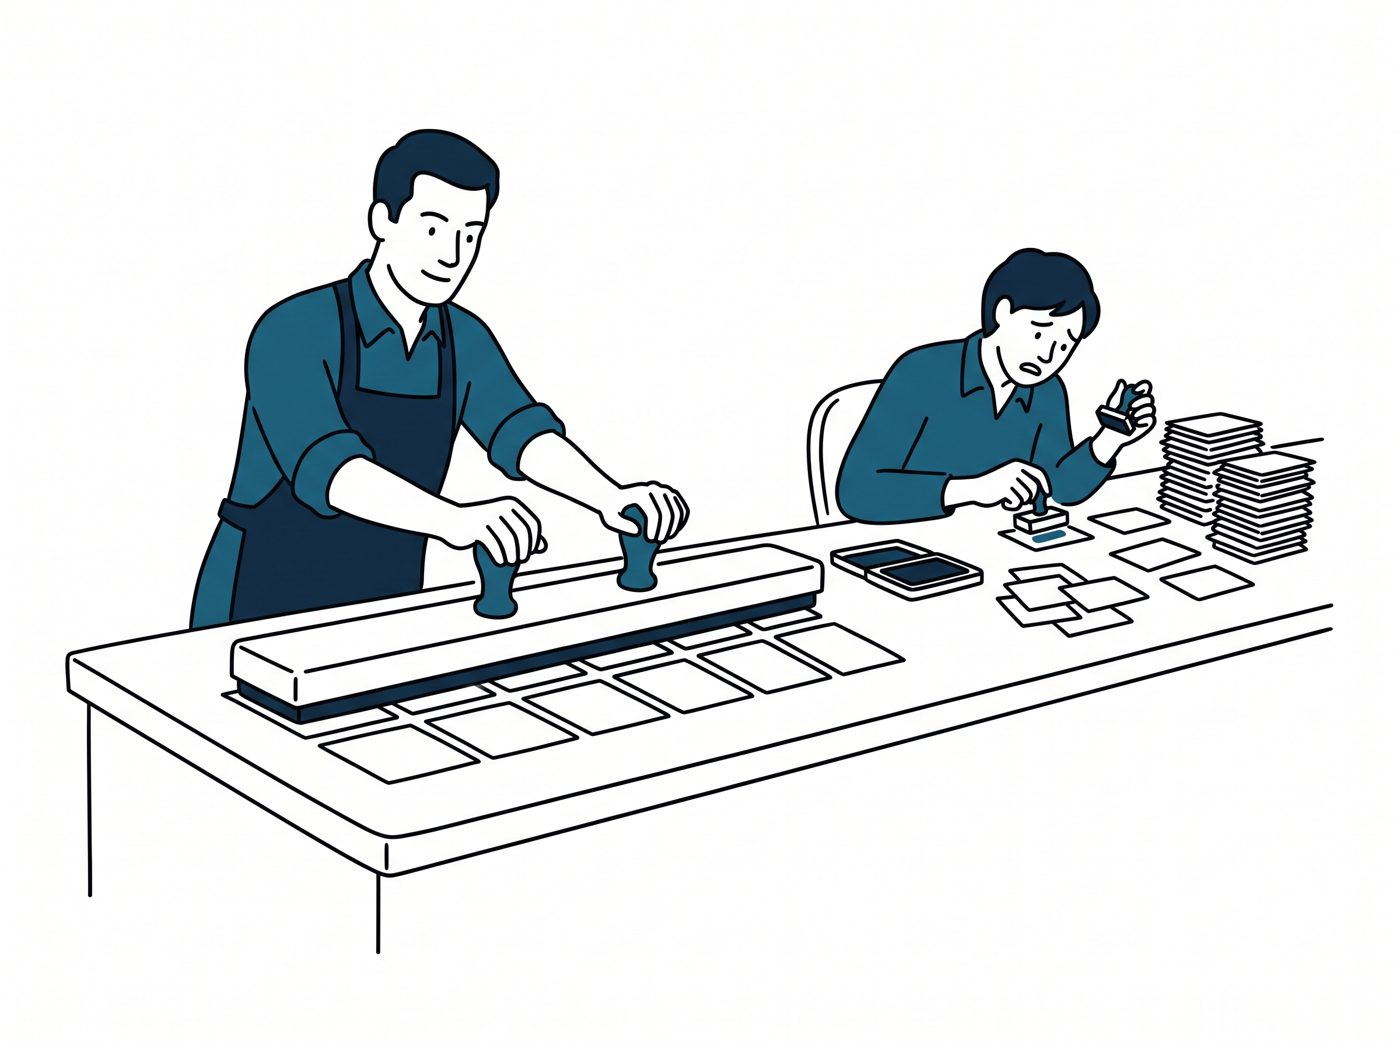<div style="text-align:center; color:#475569; font-size:0.92em; line-height:1.4; margin:-4px auto 14px; max-width:70%;">Broadcasting legt ein kleineres Array in einem Zug auf jede Zeile des größeren, so wie der breite Stempel alle Karten gleichzeitig trifft. Ob der Stempel passt, entscheiden die Formen.</div></div>

In [ ]:
norms = row_norms(E)
print(norms.shape, "<- passt nicht gegen (400, 384)")
print(norms[:, None].shape, "<- passt: die 1 wird auf 384 gedehnt")
En = E / norms[:, None]
print(En.shape, En.dtype)
print("Länge der ersten drei Zeilen nach dem Teilen:", np.round(row_norms(En)[:3], 4))
# Formen: E (400, 384) -> norms (400,) -> norms[:, None] (400, 1) -> E / norms[:, None] (400, 384)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">norms <span style="color: #666">=</span> row_norms(E)
<span style="color: #008000">print</span>(norms<span style="color: #666">.</span>shape, <span style="color: #BA2121">"&lt;- passt nicht gegen (400, 384)"</span>)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">None</code> an einer Indexposition fügt dort eine neue Achse der Länge 1 ein (NumPy nennt das auch <code style="color:inherit;">np.newaxis</code>): aus <code style="color:inherit;">(400,)</code> wird mit <code style="color:inherit;">[:, None]</code> die Form <code style="color:inherit;">(400, 1)</code></div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(norms[:, <span style="color: #008000; font-weight: bold">None</span>]<span style="color: #666">.</span>shape, <span style="color: #BA2121">"&lt;- passt: die 1 wird auf 384 gedehnt"</span>)
En <span style="color: #666">=</span> E <span style="color: #666">/</span> norms[:, <span style="color: #008000; font-weight: bold">None</span>]
<span style="color: #008000">print</span>(En<span style="color: #666">.</span>shape, En<span style="color: #666">.</span>dtype)
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Länge der ersten drei Zeilen nach dem Teilen:"</span>, np<span style="color: #666">.</span>round(row_norms(En)[:<span style="color: #666">3</span>], <span style="color: #666">4</span>))
<span style="color: #3D7B7B; font-style: italic"># Formen: E (400, 384) -&gt; norms (400,) -&gt; norms[:, None] (400, 1) -&gt; E / norms[:, None] (400, 384)</span></code></pre></details>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">2 min</span>✏️ Aufgabe 3.5 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p><strong>Die stille Falle.</strong> Die Zelle darunter soll die zwei Zeilen von <code style="color:inherit;">x</code> normalisieren. Sie läuft ohne Fehler und liefert trotzdem ein falsches Ergebnis. Führen Sie die Zelle aus, erklären Sie in einem Kommentar, durch welche Werte NumPy hier tatsächlich geteilt hat, und korrigieren Sie die Zeile. Die Prüfzelle kennt das richtige Ergebnis.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> <code style="color:inherit;">x</code> hat die Form <code style="color:inherit;">(2, 2)</code>, <code style="color:inherit;">norms</code> die Form <code style="color:inherit;">(2,)</code>. Legen Sie beide Formen rechtsbündig untereinander. Sie passen, und genau das ist das Problem: <code style="color:inherit;">norms</code> wird auf jede Zeile gelegt, nicht neben jede Zeile.</p></div></details>
</div>
</div>

In [ ]:
x = np.array([[3.0, 4.0], [0.0, 2.0]], dtype=np.float32)
norms = row_norms(x)                      # [5, 2]
y = x / norms
print(y)

In [ ]:
# Prüfzelle — einfach ausführen
assert y.shape == (2, 2)
assert np.allclose(y, [[0.6, 0.8], [0.0, 1.0]]), "jede Zeile durch ihre eigene Länge: [3, 4] / 5 und [0, 2] / 2"
print("Alle Prüfungen bestanden ✓")

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Broadcasting</span></div>
<p>Formen werden rechtsbündig untereinandergelegt und von rechts verglichen. Zwei Achsen passen, wenn sie gleich viele Einträge haben oder eine die Länge 1 hat; die 1 wird gedehnt. Fehlende Achsen werden links als 1 ergänzt.</p>
<table>
<thead>
<tr>
<th>Ausdruck</th>
<th>Formen</th>
<th>Ergebnis</th>
</tr>
</thead>
<tbody>
<tr>
<td><code style="color:inherit;">E + 1.0</code></td>
<td><code style="color:inherit;">(400, 384)</code> gegen <code style="color:inherit;">()</code></td>
<td><code style="color:inherit;">(400, 384)</code>: die Zahl wird zu jedem Eintrag addiert</td>
</tr>
<tr>
<td><code style="color:inherit;">E + q</code></td>
<td><code style="color:inherit;">(400, 384)</code> gegen <code style="color:inherit;">(384,)</code></td>
<td><code style="color:inherit;">(400, 384)</code>: <code style="color:inherit;">q</code> wird zu jeder Zeile addiert, Eintrag für Eintrag</td>
</tr>
<tr>
<td><code style="color:inherit;">E / norms[:, None]</code></td>
<td><code style="color:inherit;">(400, 384)</code> gegen <code style="color:inherit;">(400, 1)</code></td>
<td><code style="color:inherit;">(400, 384)</code>: jede Zeile wird durch ihren eigenen Wert geteilt</td>
</tr>
<tr>
<td><code style="color:inherit;">E / norms</code></td>
<td><code style="color:inherit;">(400, 384)</code> gegen <code style="color:inherit;">(400,)</code></td>
<td><code style="color:inherit;">ValueError</code>: 384 gegen 400 passt nicht</td>
</tr>
<tr>
<td><code style="color:inherit;">Q[:, None, :] - E[None, :, :]</code></td>
<td><code style="color:inherit;">(8, 1, 384)</code> gegen <code style="color:inherit;">(1, 400, 384)</code></td>
<td><code style="color:inherit;">(8, 400, 384)</code>: für jede der 8 Anfragen und jeden der 400 Absätze die 384 Differenzen der Komponenten, also jede Anfrage minus jeder Absatz</td>
</tr>
</tbody>
</table>
<p><strong>Die stille Falle:</strong> <code style="color:inherit;">x / norms</code> mit <code style="color:inherit;">x (2, 2)</code> und <code style="color:inherit;">norms (2,)</code> läuft ohne Fehler und teilt spaltenweise statt zeilenweise. Deshalb die Achse ausdrücklich behalten: <code style="color:inherit;">keepdims=True</code> oder <code style="color:inherit;">[:, None]</code>.</p>
<p>Broadcasting vervielfacht die Eingabedaten nicht im Speicher, das Ergebnis braucht aber Speicher in seiner Ergebnisform: Das Paarbeispiel <code style="color:inherit;">(8, 400, 384)</code> sind in <code style="color:inherit;">float32</code> rund 4,9 MB.</p>

</div>

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>Welche Form hat das Ergebnis der drei Ausdrücke <code style="color:inherit;">E + Q[0]</code>, <code style="color:inherit;">Q[:, None, :] - E[None, :, :]</code> und <code style="color:inherit;">E * E.sum(axis=1, keepdims=True)</code>? Schreiben Sie die Formen auf, oder stellen Sie fest, dass ein Ausdruck scheitert.</p>

</div>

### <a id="kap-der-semester-operator-row-l2-normalize"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:1px solid rgba(21,96,130,0.45); padding-bottom:2px;  padding-top:16px;">3.5.1&nbsp;&nbsp;Der Semester-Operator row_l2_normalize</span>

<div style="border:2px solid #156082; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#156082; font-weight:bold; font-size:1.08em;">🔄 Wiederholung: normalize_eps</span></div>
<p>In LE 2, Abschnitt 2.6 bekam die Normalisierung einen kleinen positiven Wert <code style="color:inherit;">eps</code> unter der Wurzel, damit der Nullvektor keine Division durch null auslöst. Der Nullvektor bleibt dabei ein Nullvektor, weil der Zähler null ist. Der Preis: Die Länge des Ergebnisses ist <code style="color:inherit;">‖x‖ / sqrt(‖x‖² + eps)</code> und nicht genau 1. Für die Absatzvektoren mit Längen zwischen 1,8 und 4,1 ist die Abweichung winzig, für sehr kurze Vektoren kann sie groß werden. <code style="color:inherit;">[0.0001, 0]</code> hat nach der Rechnung nur die Länge 0,0995. Das ist eine stabilisierte Normalisierung, keine exakte.</p>

</div>

Jetzt bekommt diese Rechnung ihre endgültige Form als Operator auf einer ganzen Matrix. `row_l2_normalize` normalisiert jede Zeile eines Arrays. Es ist der Operator des Semesters: Sie schreiben ihn in dieser Lerneinheit in NumPy, später in PyTorch, als CUDA-Kernel und in Mojo. Damit alle Fassungen gegen dieselben Tests laufen können, bekommt er einen Vertrag.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#C62828; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Definition: Operator-Vertrag</div>
<div style="background:#FDECEA; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Ein Operator-Vertrag legt für eine Funktion schriftlich fest, welche Eingaben sie annimmt, was sie zurückgibt, wie sie sich an den Randfällen verhält und wie sie ungültige Eingaben abweist. Alle Fassungen eines Operators, in welcher Sprache oder Bibliothek auch immer, werden gegen denselben Vertrag getestet; ohne ihn ließe sich nicht entscheiden, ob verschiedene Fassungen „dasselbe" tun.</p>

</div>
</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E75B6; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Genau verstehen: Der Vertrag von row_l2_normalize</div>
<div style="background:#EAF2FA; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p><code style="color:inherit;">row_l2_normalize(x, eps=1e-6)</code> normalisiert jede Zeile eines zweidimensionalen Arrays mit der stabilisierten Formel</p>


$$\hat{x}_i = \frac{x_i}{\sqrt{\sum_{j} x_{ij}^2 + \varepsilon}}$$


<p>für jede Zeile xᵢ mit D Einträgen. Das <code style="color:inherit;">eps</code> hält den Nenner größer als null. Für eine Nullzeile ist der Zähler null und der Nenner <code style="color:inherit;">sqrt(eps)</code>, die Zeile bleibt null. Die fünf Punkte des Vertrags:</p>
<ol>
<li><strong>Eingabe:</strong> ein zweidimensionales Array der Form <code style="color:inherit;">[N, D]</code> mit <code style="color:inherit;">N ≥ 0</code> und <code style="color:inherit;">D &gt; 0</code>, Datentyp <code style="color:inherit;">float32</code>, zeilenweise zusammenhängend im Speicher.</li>
<li><strong>Ausgabe:</strong> ein neues Array mit derselben Form und demselben Datentyp.</li>
<li><strong>Die Eingabe bleibt unverändert.</strong></li>
<li><strong>Nullzeilen bleiben Nullzeilen.</strong></li>
<li><strong><code style="color:inherit;">eps</code></strong> ist positiv und endlich, und zwar im Rechentyp <code style="color:inherit;">float32</code>.</li>
</ol>
<p>Ungültige Eingaben weist der Operator mit einem <code style="color:inherit;">ValueError</code> ab: falsche Anzahl der Achsen, falscher Datentyp, <code style="color:inherit;">D = 0</code>, ungültiges <code style="color:inherit;">eps</code>, nicht zeilenweise zusammenhängend. Was „zeilenweise zusammenhängend" bedeutet, erklärt das Kapitel <a href="#kap-sicht-oder-kopie">3.7</a>; dort wird die Prüfung ergänzt und der Operator damit vervollständigt. Die Einschränkung braucht NumPy nicht, sie ist ein Vertrag für die späteren Implementierungen, die ein dichtes zeilenweises Speicherlayout voraussetzen.</p>

</div>
</div>

**Eine Formel, viele Stacks.** Genau diese Formel implementieren Sie im Semester mehrmals. Was sich ändert, ist nie die Mathematik, sondern wo die Schleife läuft und wer sie schreibt.

<details style="margin-top:10px"><summary style="cursor:pointer; color:#1F5FB0; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #1F5FB055"><p>In NumPy schreibt die Bibliothek die Schleife, vektorisiert und in kompiliertem Code. In PyTorch wählt eine Verteilstelle (der Dispatcher) anhand der Eigenschaften der Tensoren die passende Implementierung; das Gerät legen Sie selbst fest, indem Sie die Tensoren dort anlegen oder dorthin verschieben. In CUDA schreiben Sie die Schleife selbst als Programm für die GPU (einen Kernel), in dem viele Threads gleichzeitig je einen Teil der Arbeit übernehmen, und in Mojo beschreiben Sie dasselbe in einer höheren Sprache, die trotzdem zu einem solchen Programm übersetzt wird. Der Vertrag ist das, was alle Fassungen verbindet: Jede muss dieselben Randfälle bestehen.</p></div></details>

**Die Eingabeprüfung als Vorgabe.** Die Prüfungen des Vertrags stehen in der Funktion `check_input`, die Ihre Fassung des Operators als erste Zeile aufruft. Sie verwendet `raise ValueError(...)`, womit eine Funktion einen Fehler auslöst und abbricht. Fehler auslösen und behandeln ist Thema von Grundkurs Teil 3, deshalb ist diese Zelle eine Vorgabe. Lesen Sie sie trotzdem: Jede Zeile entspricht einem Punkt des Vertrags.

In [ ]:
# Vorgabe: die Eingabeprüfung des Operators — einfach ausführen
def check_input(x, eps):
    if x.ndim != 2:
        raise ValueError(f"Eingabe muss zwei Achsen haben, hat {x.ndim}")
    if x.dtype != np.float32:
        raise ValueError(f"Eingabe muss float32 sein, ist {x.dtype}")
    if x.shape[1] == 0:
        raise ValueError("Eingabe muss mindestens eine Spalte haben (D > 0)")
    eps32 = np.float32(eps)
    if not np.isfinite(eps32) or eps32 <= 0:
        raise ValueError(f"eps muss in float32 positiv und endlich sein, ist {eps}")
    # Die Prüfung auf zeilenweise zusammenhängenden Speicher kommt im Kapitel „Sicht oder Kopie" dazu.

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Vorgabe: die Eingabeprüfung des Operators — einfach ausführen</span>
<span style="color: #008000; font-weight: bold">def</span><span style="color: #BBB"> </span><span style="color: #00F">check_input</span>(x, eps):</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">raise ValueError(&quot;...&quot;)</code> bricht die Funktion mit dieser Fehlermeldung ab</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">    <span style="color: #008000; font-weight: bold">if</span> x<span style="color: #666">.</span>ndim <span style="color: #666">!=</span> <span style="color: #666">2</span>:
        <span style="color: #008000; font-weight: bold">raise</span> <span style="color: #CB3F38; font-weight: bold">ValueError</span>(<span style="color: #BA2121">f"Eingabe muss zwei Achsen haben, hat </span><span style="color: #A45A77; font-weight: bold">{</span>x<span style="color: #666">.</span>ndim<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">"</span>)
    <span style="color: #008000; font-weight: bold">if</span> x<span style="color: #666">.</span>dtype <span style="color: #666">!=</span> np<span style="color: #666">.</span>float32:
        <span style="color: #008000; font-weight: bold">raise</span> <span style="color: #CB3F38; font-weight: bold">ValueError</span>(<span style="color: #BA2121">f"Eingabe muss float32 sein, ist </span><span style="color: #A45A77; font-weight: bold">{</span>x<span style="color: #666">.</span>dtype<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">"</span>)
    <span style="color: #008000; font-weight: bold">if</span> x<span style="color: #666">.</span>shape[<span style="color: #666">1</span>] <span style="color: #666">==</span> <span style="color: #666">0</span>:
        <span style="color: #008000; font-weight: bold">raise</span> <span style="color: #CB3F38; font-weight: bold">ValueError</span>(<span style="color: #BA2121">"Eingabe muss mindestens eine Spalte haben (D &gt; 0)"</span>)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">np.float32(eps)</code> rechnet eps in den Rechentyp um; <code style="color:inherit;">np.isfinite</code> ist False für unendlich und NaN</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">    eps32 <span style="color: #666">=</span> np<span style="color: #666">.</span>float32(eps)
    <span style="color: #008000; font-weight: bold">if</span> <span style="color: #A2F; font-weight: bold">not</span> np<span style="color: #666">.</span>isfinite(eps32) <span style="color: #A2F; font-weight: bold">or</span> eps32 <span style="color: #666">&lt;=</span> <span style="color: #666">0</span>:
        <span style="color: #008000; font-weight: bold">raise</span> <span style="color: #CB3F38; font-weight: bold">ValueError</span>(<span style="color: #BA2121">f"eps muss in float32 positiv und endlich sein, ist </span><span style="color: #A45A77; font-weight: bold">{</span>eps<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">"</span>)
    <span style="color: #3D7B7B; font-style: italic"># Die Prüfung auf zeilenweise zusammenhängenden Speicher kommt im Kapitel „Sicht oder Kopie" dazu.</span></code></pre></details>

`1e-100` ist als Python-Zahl positiv, in `float32` aber null: Der kleinste darstellbare positive Wert dieses Typs liegt bei etwa `1e-45`. Mit einem solchen `eps` würde eine Nullzeile zu `NaN`, der Darstellung von „keine Zahl" nach einer Division 0 durch 0. Deshalb prüft `check_input` den Wert im Rechentyp `float32`. Ein `eps` schützt nur den Nenner vor null. Vor einem Überlauf beim Quadrieren sehr großer Werte schützt es nicht.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">10 min</span>✏️ Aufgabe 3.5.1 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Schreiben Sie die Funktion <code style="color:inherit;">row_l2_normalize(x, eps=1e-6)</code> nach dem Vertrag. Die erste Zeile ruft <code style="color:inherit;">check_input(x, eps)</code> auf, die zweite wandelt <code style="color:inherit;">eps</code> mit <code style="color:inherit;">eps = np.float32(eps)</code> in den Rechentyp um. Danach berechnen Sie für jede Zeile die Summe der Quadrate, addieren <code style="color:inherit;">eps</code>, ziehen die Wurzel und teilen die Zeile durch das Ergebnis. Achten Sie auf die Form des Nenners. Das Ergebnis muss <code style="color:inherit;">float32</code> bleiben und die Eingabe unverändert lassen.</p>
<p>Wer früher fertig ist: Schreiben Sie in einer neuen Zelle einen eigenen Test mit dem Array <code style="color:inherit;">[[3, 4], [0, 0], [1, 1]]</code> als <code style="color:inherit;">float32</code>. Prüfen Sie mit <code style="color:inherit;">row_norms</code>, dass die erste und die dritte Zeile nach dem Operator näherungsweise die Länge 1 haben (<code style="color:inherit;">np.allclose</code> mit <code style="color:inherit;">atol=1e-6</code>) und die Nullzeile die Länge 0.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> <code style="color:inherit;">(x * x).sum(axis=1, keepdims=True)</code> liefert die Summen der Quadrate schon in der Form <code style="color:inherit;">(N, 1)</code>, die gegen <code style="color:inherit;">(N, D)</code> passt. Die Umwandlung von <code style="color:inherit;">eps</code> sorgt dafür, dass auch ein <code style="color:inherit;">eps</code> vom Typ <code style="color:inherit;">float64</code> das Ergebnis nicht auf <code style="color:inherit;">float64</code> anhebt.</p></div></details>
</div>
</div>

In [ ]:
def row_l2_normalize(x, eps=1e-6):
    # TODO: Ihre Lösung hier
    ...

In [ ]:
# Prüfzelle — einfach ausführen
x = np.array([[3.0, 4.0], [0.0, 2.0]], dtype=np.float32)     # zwei Zeilen verschiedener Länge
x_before = x.copy()                                           # Kopie für den Vergleich danach
y = row_l2_normalize(x)
assert y is not None, "row_l2_normalize gibt noch nichts zurück (return vergessen?)"
assert y.shape == (2, 2), f"gleiche Form wie die Eingabe, {y.shape} statt (2, 2)"
assert y.dtype == np.float32, f"gleicher Datentyp wie die Eingabe, {y.dtype} statt float32"
assert np.allclose(y, [[0.6, 0.8], [0.0, 1.0]], atol=1e-6), "jede Zeile durch ihre eigene Länge"
assert np.array_equal(x, x_before), "die Eingabe muss unverändert bleiben"
assert np.all(row_l2_normalize(np.zeros((1, 3), dtype=np.float32)) == 0), "eine Nullzeile bleibt eine Nullzeile"
tiny = row_l2_normalize(np.array([[1e-4, 0.0]], dtype=np.float32))
assert abs(row_norms(tiny)[0] - 0.0995) < 1e-3, "eine sehr kurze Zeile wird nicht auf Länge 1 gebracht (stabilisierte Formel)"
assert row_l2_normalize(np.zeros((0, 3), dtype=np.float32)).shape == (0, 3), "ein Array ohne Zeilen ist zulässig"
assert row_l2_normalize(x, eps=np.float64(1e-6)).dtype == np.float32, "auch ein eps vom Typ float64 darf das Ergebnis nicht anheben (eps = np.float32(eps))"
assert np.allclose(row_l2_normalize(x, eps=1.0)[0], [3 / 26 ** 0.5, 4 / 26 ** 0.5], atol=1e-6), "eps muss in die Rechnung eingehen: [3, 4] mit eps=1 ergibt den Nenner sqrt(26)"
try:
    row_l2_normalize(np.zeros((2, 2)))                          # float64 statt float32
    raise AssertionError("float64 muss abgewiesen werden: ruft Ihre Funktion check_input auf?")
except ValueError:
    pass
try:
    row_l2_normalize(np.zeros(3, dtype=np.float32))              # eine Achse statt zwei
    raise AssertionError("ein Array mit einer Achse muss abgewiesen werden")
except ValueError:
    pass
print("Alle Prüfungen bestanden ✓")

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Prüfzelle — einfach ausführen</span>
x <span style="color: #666">=</span> np<span style="color: #666">.</span>array([[<span style="color: #666">3.0</span>, <span style="color: #666">4.0</span>], [<span style="color: #666">0.0</span>, <span style="color: #666">2.0</span>]], dtype<span style="color: #666">=</span>np<span style="color: #666">.</span>float32)     <span style="color: #3D7B7B; font-style: italic"># zwei Zeilen verschiedener Länge</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">.copy()</code> legt eine unabhängige Kopie des Arrays an, mehr dazu im Kapitel „Sicht oder Kopie&quot;</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">x_before <span style="color: #666">=</span> x<span style="color: #666">.</span>copy()                                           <span style="color: #3D7B7B; font-style: italic"># Kopie für den Vergleich danach</span>
y <span style="color: #666">=</span> row_l2_normalize(x)
<span style="color: #008000; font-weight: bold">assert</span> y <span style="color: #A2F; font-weight: bold">is</span> <span style="color: #A2F; font-weight: bold">not</span> <span style="color: #008000; font-weight: bold">None</span>, <span style="color: #BA2121">"row_l2_normalize gibt noch nichts zurück (return vergessen?)"</span>
<span style="color: #008000; font-weight: bold">assert</span> y<span style="color: #666">.</span>shape <span style="color: #666">==</span> (<span style="color: #666">2</span>, <span style="color: #666">2</span>), <span style="color: #BA2121">f"gleiche Form wie die Eingabe, </span><span style="color: #A45A77; font-weight: bold">{</span>y<span style="color: #666">.</span>shape<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> statt (2, 2)"</span>
<span style="color: #008000; font-weight: bold">assert</span> y<span style="color: #666">.</span>dtype <span style="color: #666">==</span> np<span style="color: #666">.</span>float32, <span style="color: #BA2121">f"gleicher Datentyp wie die Eingabe, </span><span style="color: #A45A77; font-weight: bold">{</span>y<span style="color: #666">.</span>dtype<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> statt float32"</span>
<span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>allclose(y, [[<span style="color: #666">0.6</span>, <span style="color: #666">0.8</span>], [<span style="color: #666">0.0</span>, <span style="color: #666">1.0</span>]], atol<span style="color: #666">=1e-6</span>), <span style="color: #BA2121">"jede Zeile durch ihre eigene Länge"</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">np.array_equal</code> prüft, ob zwei Arrays dieselbe Form und exakt dieselben Werte haben, ohne Toleranz</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>array_equal(x, x_before), <span style="color: #BA2121">"die Eingabe muss unverändert bleiben"</span>
<span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>all(row_l2_normalize(np<span style="color: #666">.</span>zeros((<span style="color: #666">1</span>, <span style="color: #666">3</span>), dtype<span style="color: #666">=</span>np<span style="color: #666">.</span>float32)) <span style="color: #666">==</span> <span style="color: #666">0</span>), <span style="color: #BA2121">"eine Nullzeile bleibt eine Nullzeile"</span>
tiny <span style="color: #666">=</span> row_l2_normalize(np<span style="color: #666">.</span>array([[<span style="color: #666">1e-4</span>, <span style="color: #666">0.0</span>]], dtype<span style="color: #666">=</span>np<span style="color: #666">.</span>float32))
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">abs</span>(row_norms(tiny)[<span style="color: #666">0</span>] <span style="color: #666">-</span> <span style="color: #666">0.0995</span>) <span style="color: #666">&lt;</span> <span style="color: #666">1e-3</span>, <span style="color: #BA2121">"eine sehr kurze Zeile wird nicht auf Länge 1 gebracht (stabilisierte Formel)"</span>
<span style="color: #008000; font-weight: bold">assert</span> row_l2_normalize(np<span style="color: #666">.</span>zeros((<span style="color: #666">0</span>, <span style="color: #666">3</span>), dtype<span style="color: #666">=</span>np<span style="color: #666">.</span>float32))<span style="color: #666">.</span>shape <span style="color: #666">==</span> (<span style="color: #666">0</span>, <span style="color: #666">3</span>), <span style="color: #BA2121">"ein Array ohne Zeilen ist zulässig"</span>
<span style="color: #008000; font-weight: bold">assert</span> row_l2_normalize(x, eps<span style="color: #666">=</span>np<span style="color: #666">.</span>float64(<span style="color: #666">1e-6</span>))<span style="color: #666">.</span>dtype <span style="color: #666">==</span> np<span style="color: #666">.</span>float32, <span style="color: #BA2121">"auch ein eps vom Typ float64 darf das Ergebnis nicht anheben (eps = np.float32(eps))"</span>
<span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>allclose(row_l2_normalize(x, eps<span style="color: #666">=1.0</span>)[<span style="color: #666">0</span>], [<span style="color: #666">3</span> <span style="color: #666">/</span> <span style="color: #666">26</span> <span style="color: #666">**</span> <span style="color: #666">0.5</span>, <span style="color: #666">4</span> <span style="color: #666">/</span> <span style="color: #666">26</span> <span style="color: #666">**</span> <span style="color: #666">0.5</span>], atol<span style="color: #666">=1e-6</span>), <span style="color: #BA2121">"eps muss in die Rechnung eingehen: [3, 4] mit eps=1 ergibt den Nenner sqrt(26)"</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; <code style="color:inherit;">try</code> führt den Block aus, <code style="color:inherit;">except ValueError</code> fängt genau diesen Fehler ab, mehr dazu in Grundkurs Teil 3</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000; font-weight: bold">try</span>:
    row_l2_normalize(np<span style="color: #666">.</span>zeros((<span style="color: #666">2</span>, <span style="color: #666">2</span>)))                          <span style="color: #3D7B7B; font-style: italic"># float64 statt float32</span>
    <span style="color: #008000; font-weight: bold">raise</span> <span style="color: #CB3F38; font-weight: bold">AssertionError</span>(<span style="color: #BA2121">"float64 muss abgewiesen werden: ruft Ihre Funktion check_input auf?"</span>)
<span style="color: #008000; font-weight: bold">except</span> <span style="color: #CB3F38; font-weight: bold">ValueError</span>:
    <span style="color: #008000; font-weight: bold">pass</span>
<span style="color: #008000; font-weight: bold">try</span>:
    row_l2_normalize(np<span style="color: #666">.</span>zeros(<span style="color: #666">3</span>, dtype<span style="color: #666">=</span>np<span style="color: #666">.</span>float32))              <span style="color: #3D7B7B; font-style: italic"># eine Achse statt zwei</span>
    <span style="color: #008000; font-weight: bold">raise</span> <span style="color: #CB3F38; font-weight: bold">AssertionError</span>(<span style="color: #BA2121">"ein Array mit einer Achse muss abgewiesen werden"</span>)
<span style="color: #008000; font-weight: bold">except</span> <span style="color: #CB3F38; font-weight: bold">ValueError</span>:
    <span style="color: #008000; font-weight: bold">pass</span>
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Alle Prüfungen bestanden ✓"</span>)</code></pre></details>

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Anschlusslösung zu row_l2_normalize</summary><div style="color:#475569; margin:6px 0 4px;">Wenn Ihre eigene Lösung nach der Besprechung noch nicht läuft: Kopieren Sie diese Fassung in Ihre Aufgabenzelle und führen Sie die Zelle aus.</div><pre style="background:#F6F8FA; color:#1F2937; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; font-size:0.9em; line-height:1.4; overflow-x:auto;">def row_l2_normalize(x, eps=1e-6):&#10;    check_input(x, eps)&#10;    eps = np.float32(eps)&#10;    norms = np.sqrt((x * x).sum(axis=1, keepdims=True) + eps)&#10;    return x / norms</pre></details>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">2 min</span>✏️ Aufgabe 3.5.1 #2</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p><strong>Review.</strong> Die Fassung <code style="color:inherit;">row_l2_normalize_v2</code> in der Zelle darunter stammt aus einem KI-Assistenten. Sie besteht einen Test mit einer einzelnen Zeile. Lesen Sie den Code und nennen Sie in der zweiten Zelle als <code style="color:inherit;">assert</code> einen Testfall, bei dem diese Fassung scheitert und Ihre besteht. Führen Sie dann beide Zellen aus.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> Was berechnet <code style="color:inherit;">np.linalg.norm(x)</code> ohne <code style="color:inherit;">axis</code> für ein Array mit zwei Zeilen?</p></div></details>
</div>
</div>

In [ ]:
def row_l2_normalize_v2(x, eps=1e-6):
    check_input(x, eps)
    return x / np.sqrt(np.linalg.norm(x) ** 2 + eps)

print(row_l2_normalize_v2(np.array([[3.0, 4.0]], dtype=np.float32)))     # eine Zeile: richtig

In [ ]:
# Ihr Testfall als assert, dahinter als Kommentar, welchen Fehler er erkennt:
# TODO: Ihre Lösung hier
...

Ein Test mit nur einer Zeile unterscheidet nicht zwischen „jede Zeile durch ihre Länge" und „alle Zeilen durch dieselbe Länge". Deshalb enthalten die Prüfzellen dieses Notebooks mindestens zwei Zeilen mit verschiedener Länge. Bei quadratischen Arrays läuft die falsche Broadcasting-Rechnung aus der stillen Falle ohne Formfehler durch, ein Vergleich mit den erwarteten Werten erkennt sie trotzdem. Nichtquadratische Testdaten machen zusätzlich die Formverwechslung sichtbar, dann meldet schon die Form den Fehler.

Zum Schluss die Rechnung als Bild: Die Zeile `[3, 4]` hat die geometrische Länge 5 und landet nach dem Operator bei `[0.6, 0.8]`, auf dem Einheitskreis. Die Zelle verwendet Matplotlib, das in der nächsten Lerneinheit ausführlich drankommt.

In [ ]:
import matplotlib.pyplot as plt

v = np.array([[3.0, 4.0]], dtype=np.float32)
u = row_l2_normalize(v)[0]
fig, ax = plt.subplots(figsize=(4.2, 3.6))
t = np.linspace(0, 2 * np.pi, 200)
ax.plot(np.cos(t), np.sin(t), "--", color="#98a1ad", lw=1)                 # der Einheitskreis
ax.quiver([0, 0], [0, 0], [3, u[0]], [4, u[1]], angles="xy", scale_units="xy",
          scale=1, color=["#98a1ad", "#156082"], width=0.012)
ax.set_xlim(-1.4, 4.2); ax.set_ylim(-1.4, 4.6); ax.set_aspect("equal")
ax.set_title("[3, 4] wird [0.6, 0.8]: auf den Einheitskreis")
plt.show()

**Warum der Datentyp kippen kann.** Ein Python-`float` wie `1e-6` lässt ein `float32`-Array bei `float32`, `x * x + 1e-6` bleibt deshalb `float32`. Ein `float64`-Wert von NumPy, etwa `np.float64(1e-6)` oder ein `float64`-Array, hebt das Ergebnis dagegen auf `float64` an; für den NumPy-Skalar gilt das seit NumPy 2. (Ein Python-`float` auf einem Ganzzahlarray ergibt `float64`; hier geht es um Fließkomma-Arrays.) Ein solcher Wechsel verdoppelt den Speicher und fällt an den Werten nicht auf. Deshalb prüfen die Prüfzellen den Datentyp vor den Werten, und deshalb wandelt der Operator `eps` zuerst um. Typische Quellen für den stillen Wechsel sind `np.zeros` ohne `dtype`, Konstanten, die als Array angelegt wurden, und `float64`-Zwischenergebnisse aus anderen Bibliotheken.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right"><span style="border:1px solid rgba(255,255,255,0.85); color:#fff; font-size:0.72em; font-weight:bold; padding:1px 9px; border-radius:10px; margin-left:8px; vertical-align:1px;">NICHT PRÜFUNGSRELEVANT</span></span>Vertiefung: Wie groß darf eps sein?</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p><code style="color:inherit;">eps</code> muss gegenüber den Quadratsummen der Zeilen klein sein, sonst verfälscht es alle Längen, und gegenüber <code style="color:inherit;">float32</code> groß genug, um nicht zu null zu werden. <code style="color:inherit;">1e-6</code> passt zu Vektoren mit Längen um 1 bis 10, wie unseren Absatzvektoren.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#107C72; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #107C7255"><p>Unter der Wurzel addiert, wirkt <code style="color:inherit;">eps</code> wie ein zusätzlicher Eintrag der Zeile mit dem Quadrat <code style="color:inherit;">eps</code>. Bei einer Quadratsumme von 10 ändert <code style="color:inherit;">1e-6</code> die Länge rechnerisch um etwa <code style="color:inherit;">1.6e-7</code>, relativ um etwa <code style="color:inherit;">5e-8</code>; in <code style="color:inherit;">float32</code> ist diese Änderung so klein, dass sie beim Runden ganz verschwinden kann. Bei einer Quadratsumme von <code style="color:inherit;">1e-8</code> dominiert es. PyTorch macht es etwas anders: Es verwendet in seiner Normalisierungsfunktion das Maximum aus Länge und <code style="color:inherit;">eps</code> statt der Addition unter der Wurzel, mit <code style="color:inherit;">eps = 1e-12</code>; das Verhalten für Nullzeilen ist dasselbe.</p></div></details>
</div>
</div>

### <a id="kap-compare-alle-skalarprodukte-auf-einmal"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:1px solid rgba(21,96,130,0.45); padding-bottom:2px;  padding-top:16px;">3.5.2&nbsp;&nbsp;Compare: alle Skalarprodukte auf einmal</span>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#0E2841; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Skalarprodukt, Matrixprodukt und elementweises Produkt</div>
<div style="background:#E9EDF4; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Das Skalarprodukt zweier Vektoren a und b mit gleich vielen Einträgen ist die Summe der Produkte ihrer Einträge; in NumPy schreibt man es <code style="color:inherit;">a @ b</code>:</p>


$$a \cdot b = \sum_{j} a_j \, b_j$$


<p>Für Einheitsvektoren ist es der Kosinus des Winkels zwischen beiden, deshalb misst es in der Suche die Ähnlichkeit von Anfrage und Absatz. Das Matrixprodukt einer Matrix A der Form (m, d) mit einer Matrix B der Form (d, n), in NumPy <code style="color:inherit;">A @ B</code>, ist die Matrix der Form (m, n) aller Skalarprodukte zwischen den Zeilen von A und den Spalten von B:</p>


$$(AB)_{ik} = \sum_{j} A_{ij} \, B_{jk}$$


<p>Es berechnet also viele Skalarprodukte auf einmal, genau das, was die Suche mit allen Absätzen braucht. Dieselbe Operation ist der Kern jeder vollverbundenen Schicht eines neuronalen Netzes. Große Matrixprodukte eignen sich besonders gut für die parallele Ausführung auf der GPU; auch elementweise Operationen und Reduktionen, aus denen unser Operator besteht, profitieren bei ausreichender Größe davon.</p>
<p>Nicht zu verwechseln damit ist das elementweise Produkt zweier gleich geformter Matrizen, in der Mathematik Hadamard-Produkt genannt und mit einem Kreis geschrieben, in NumPy das gewöhnliche <code style="color:inherit;">A * B</code>. Dabei wird nichts aufsummiert:</p>


$$(A \odot B)_{ij} = A_{ij} \, B_{ij}$$


<p>Das Ergebnis hat die Form der Eingaben, nicht (m, n). In der Mathematik müssen die Formen gleich sein, in NumPy gilt dafür Broadcasting. Die Grafik unten stellt <code style="color:inherit;">@</code> und <code style="color:inherit;">*</code> an einem Beispiel gegenüber.</p>

</div>
</div>

Der zweite Schritt der Suche, Compare, berechnet das Skalarprodukt der Anfrage mit jedem der 400 Absätze. In NumPy ist das eine einzige Operation, das Matrixprodukt `@`: Es bildet für jede Zeile der linken Matrix und jede Spalte der rechten das Skalarprodukt, und mit der Anfrage als einziger Zeile links sind das genau die 400 gesuchten Werte. Vorher zwei Unterscheidungen an einer kleinen Matrix: `*` multipliziert elementweise, `@` bildet Summen von Produkten. Und `.T` liefert die passende Form für `@`, lässt ein eindimensionales Array aber unverändert.

In [ ]:
A = np.array([[1.0, 2.0, 3.0],
              [4.0, 5.0, 6.0]])             # Form (2, 3)
w = np.array([1.0, 0.0, 1.0])               # Form (3,)
print(A @ w)                                # [1*1 + 2*0 + 3*1, 4*1 + 5*0 + 6*1]
print(A * w)
print(w.T.shape, w[:, None].shape, w[None, :].shape)
# Formen: A (2, 3) @ w (3,) -> (2,);  A (2, 3) * w (3,) -> (2, 3)
#         w.T (3,);  w[:, None] (3, 1);  w[None, :] (1, 3)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">A <span style="color: #666">=</span> np<span style="color: #666">.</span>array([[<span style="color: #666">1.0</span>, <span style="color: #666">2.0</span>, <span style="color: #666">3.0</span>],
              [<span style="color: #666">4.0</span>, <span style="color: #666">5.0</span>, <span style="color: #666">6.0</span>]])             <span style="color: #3D7B7B; font-style: italic"># Form (2, 3)</span>
w <span style="color: #666">=</span> np<span style="color: #666">.</span>array([<span style="color: #666">1.0</span>, <span style="color: #666">0.0</span>, <span style="color: #666">1.0</span>])               <span style="color: #3D7B7B; font-style: italic"># Form (3,)</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">A @ w</code> bildet für jede Zeile von A die Summe der Produkte mit w: ein Skalarprodukt je Zeile</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(A <span style="color: #666">@</span> w)                                <span style="color: #3D7B7B; font-style: italic"># [1*1 + 2*0 + 3*1, 4*1 + 5*0 + 6*1]</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">*</code> würde elementweise rechnen: (2, 3) mal (3,) ergibt per Broadcasting (2, 3), kein Skalarprodukt</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(A <span style="color: #666">*</span> w)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; <code style="color:inherit;">.T</code> lässt ein eindimensionales Array unverändert, erst eine zweite Achse macht daraus eine Spalte</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(w<span style="color: #666">.</span>T<span style="color: #666">.</span>shape, w[:, <span style="color: #008000; font-weight: bold">None</span>]<span style="color: #666">.</span>shape, w[<span style="color: #008000; font-weight: bold">None</span>, :]<span style="color: #666">.</span>shape)
<span style="color: #3D7B7B; font-style: italic"># Formen: A (2, 3) @ w (3,) -&gt; (2,);  A (2, 3) * w (3,) -&gt; (2, 3)</span>
<span style="color: #3D7B7B; font-style: italic">#         w.T (3,);  w[:, None] (3, 1);  w[None, :] (1, 3)</span></code></pre></details>

**Beim Matrixprodukt zweier zweidimensionaler Arrays muss die letzte Achse des linken zur vorletzten des rechten passen.** `(8, 384) @ (384, 400)` ergibt `(8, 400)`: Die innere Achse 384 wird aufsummiert und verschwindet, die äußeren Achsen bilden das Ergebnis. Für Matrix mal Vektor gilt entsprechend `(m, d) @ (d,) -> (m,)`, das war das Beispiel `A @ w`. Diese Formenregel werden Sie im Semester ständig anwenden: Vollverbundene Schichten eines neuronalen Netzes multiplizieren ihre Eingabe mit einer Gewichtsmatrix, und auch bei allen anderen Schichttypen müssen Ein- und Ausgabeformen zusammenpassen.

<details style="margin-top:10px"><summary style="cursor:pointer; color:#1F5FB0; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #1F5FB055"><p>Für eine einzelne Anfrage lautet der Formenweg <code style="color:inherit;">q (384,) -&gt; q[None, :] (1, 384) -&gt; (1, 384) @ (384, 400) -&gt; (1, 400) -&gt; [0] -&gt; (400,)</code>. Die zusätzliche Achse am Anfang braucht <code style="color:inherit;">row_l2_normalize</code>, weil der Vertrag zwei Achsen verlangt: Aus der Anfrage wird eine Matrix mit einer Zeile. Das Matrixprodukt liefert dann eine Matrix mit einer Zeile und 400 Spalten, und <code style="color:inherit;">[0]</code> holt diese eine Zeile als Array der Form <code style="color:inherit;">(400,)</code> heraus.</p></div></details>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">5 min</span>✏️ Aufgabe 3.5.2 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Schreiben Sie die Funktion <code style="color:inherit;">cosine_scores(q, docs)</code>. Sie bekommt einen Anfragevektor <code style="color:inherit;">q</code> der Form <code style="color:inherit;">(D,)</code> und eine Dokumentmatrix <code style="color:inherit;">docs</code> der Form <code style="color:inherit;">(N, D)</code>, normalisiert beide mit <code style="color:inherit;">row_l2_normalize</code> und gibt die <code style="color:inherit;">N</code> Skalarprodukte als Array der Form <code style="color:inherit;">(N,)</code> zurück. Weil der Operator die stabilisierte Formel verwendet, sind das stabilisierte Näherungen der Kosinus-Ähnlichkeit: Für die Absatzvektoren fällt der Unterschied nicht ins Gewicht, für sehr kurze Vektoren schon. Die Prüfzelle vergleicht mit den Werten aus der letzten Lerneinheit und prüft genau diesen Unterschied.</p>
<p>Wer früher fertig ist: Geben Sie in einer neuen Zelle für Anfrage 0 die drei höchsten Werte aus <code style="color:inherit;">cosine_scores(Q[0], E)</code> aus. <code style="color:inherit;">np.sort</code> sortiert aufsteigend, die drei höchsten stehen also am Ende.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> <code style="color:inherit;">q[None, :]</code> macht aus <code style="color:inherit;">(D,)</code> die Form <code style="color:inherit;">(1, D)</code>. Nach <code style="color:inherit;">(1, D) @ (D, N)</code> holt <code style="color:inherit;">[0]</code> die eine Zeile heraus. Die Form <code style="color:inherit;">(D, N)</code> entsteht aus der normalisierten Matrix mit <code style="color:inherit;">.T</code>.</p></div></details>
</div>
</div>

In [ ]:
def cosine_scores(q, docs):
    # TODO: Ihre Lösung hier
    ...

In [ ]:
# Prüfzelle — einfach ausführen
scores = cosine_scores(Q[0], E)
assert scores is not None, "cosine_scores gibt noch nichts zurück (return vergessen?)"
assert scores.shape == (400,), f"ein Wert je Absatz, Form (400,) statt {scores.shape}"
assert scores.dtype == np.float32, f"float32 wie die Eingabe, {scores.dtype} (geht ein float64-Wert in die Rechnung ein?)"
assert cosine_scores(Q[0], E[:1]).shape == (1,), "auch bei genau einem Dokument bleibt es ein Array der Form (1,)"
assert np.allclose(scores, scores_python(0), rtol=1e-5, atol=1e-6), "gleiche Werte wie die Suche von Hand (bis auf float32)"
assert np.allclose(cosine_scores(Q[3], E), scores_python(3), rtol=1e-5, atol=1e-6)
assert np.all(scores <= 1.0 + 1e-6) and np.all(scores >= -1.0 - 1e-6), "Kosinus-Werte liegen zwischen -1 und 1"
tiny = np.array([1e-4, 0.0], dtype=np.float32)
assert np.allclose(cosine_scores(tiny, tiny[None, :]), [0.00990099], rtol=1e-3), "sehr kurze Vektoren: die stabilisierte Formel liefert 0.0099, die exakte Kosinus-Ähnlichkeit wäre 1 (nutzt Ihre Fassung row_l2_normalize?)"
assert np.all(cosine_scores(np.zeros(384, dtype=np.float32), E) == 0), "eine Nullanfrage ergibt überall 0"
print("Alle Prüfungen bestanden ✓")

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Prüfzelle — einfach ausführen</span>
scores <span style="color: #666">=</span> cosine_scores(Q[<span style="color: #666">0</span>], E)
<span style="color: #008000; font-weight: bold">assert</span> scores <span style="color: #A2F; font-weight: bold">is</span> <span style="color: #A2F; font-weight: bold">not</span> <span style="color: #008000; font-weight: bold">None</span>, <span style="color: #BA2121">"cosine_scores gibt noch nichts zurück (return vergessen?)"</span>
<span style="color: #008000; font-weight: bold">assert</span> scores<span style="color: #666">.</span>shape <span style="color: #666">==</span> (<span style="color: #666">400</span>,), <span style="color: #BA2121">f"ein Wert je Absatz, Form (400,) statt </span><span style="color: #A45A77; font-weight: bold">{</span>scores<span style="color: #666">.</span>shape<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">"</span>
<span style="color: #008000; font-weight: bold">assert</span> scores<span style="color: #666">.</span>dtype <span style="color: #666">==</span> np<span style="color: #666">.</span>float32, <span style="color: #BA2121">f"float32 wie die Eingabe, </span><span style="color: #A45A77; font-weight: bold">{</span>scores<span style="color: #666">.</span>dtype<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> (geht ein float64-Wert in die Rechnung ein?)"</span>
<span style="color: #008000; font-weight: bold">assert</span> cosine_scores(Q[<span style="color: #666">0</span>], E[:<span style="color: #666">1</span>])<span style="color: #666">.</span>shape <span style="color: #666">==</span> (<span style="color: #666">1</span>,), <span style="color: #BA2121">"auch bei genau einem Dokument bleibt es ein Array der Form (1,)"</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; die Werte der letzten Lerneinheit sind mit 64-Bit-Zahlen gerechnet, deshalb eine sichtbare Toleranz: rtol relativ, atol absolut</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>allclose(scores, scores_python(<span style="color: #666">0</span>), rtol<span style="color: #666">=1e-5</span>, atol<span style="color: #666">=1e-6</span>), <span style="color: #BA2121">"gleiche Werte wie die Suche von Hand (bis auf float32)"</span>
<span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>allclose(cosine_scores(Q[<span style="color: #666">3</span>], E), scores_python(<span style="color: #666">3</span>), rtol<span style="color: #666">=1e-5</span>, atol<span style="color: #666">=1e-6</span>)
<span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>all(scores <span style="color: #666">&lt;=</span> <span style="color: #666">1.0</span> <span style="color: #666">+</span> <span style="color: #666">1e-6</span>) <span style="color: #A2F; font-weight: bold">and</span> np<span style="color: #666">.</span>all(scores <span style="color: #666">&gt;=</span> <span style="color: #666">-1.0</span> <span style="color: #666">-</span> <span style="color: #666">1e-6</span>), <span style="color: #BA2121">"Kosinus-Werte liegen zwischen -1 und 1"</span>
tiny <span style="color: #666">=</span> np<span style="color: #666">.</span>array([<span style="color: #666">1e-4</span>, <span style="color: #666">0.0</span>], dtype<span style="color: #666">=</span>np<span style="color: #666">.</span>float32)
<span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>allclose(cosine_scores(tiny, tiny[<span style="color: #008000; font-weight: bold">None</span>, :]), [<span style="color: #666">0.00990099</span>], rtol<span style="color: #666">=1e-3</span>), <span style="color: #BA2121">"sehr kurze Vektoren: die stabilisierte Formel liefert 0.0099, die exakte Kosinus-Ähnlichkeit wäre 1 (nutzt Ihre Fassung row_l2_normalize?)"</span>
<span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>all(cosine_scores(np<span style="color: #666">.</span>zeros(<span style="color: #666">384</span>, dtype<span style="color: #666">=</span>np<span style="color: #666">.</span>float32), E) <span style="color: #666">==</span> <span style="color: #666">0</span>), <span style="color: #BA2121">"eine Nullanfrage ergibt überall 0"</span>
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Alle Prüfungen bestanden ✓"</span>)</code></pre></details>

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Anschlusslösung zu cosine_scores</summary><div style="color:#475569; margin:6px 0 4px;">Wenn Ihre eigene Lösung nach der Besprechung noch nicht läuft: Kopieren Sie diese Fassung in Ihre Aufgabenzelle und führen Sie die Zelle aus.</div><pre style="background:#F6F8FA; color:#1F2937; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; font-size:0.9em; line-height:1.4; overflow-x:auto;">def cosine_scores(q, docs):&#10;    qn = row_l2_normalize(q[None, :])&#10;    docs_n = row_l2_normalize(docs)&#10;    return (qn @ docs_n.T)[0]</pre></details>

Die Toleranz in der Prüfzelle ist bewusst sichtbar: `rtol=1e-5` erlaubt eine relative Abweichung von einem Hunderttausendstel, `atol=1e-6` eine absolute von einem Millionstel. Die Werte der letzten Lerneinheit sind mit 64-Bit-Zahlen gerechnet, NumPy rechnet hier mit `float32` und rund sieben gültigen Stellen. Die Standardtoleranz von `allclose` ist enger und scheitert bei einzelnen Anfragen, obwohl die größte Abweichung unter einem Millionstel liegt.

## <a id="kap-die-suche-in-numpy"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">3.6&nbsp;&nbsp;Die Suche in NumPy</span>

`cosine_scores(Q[0], E)` liefert 400 Werte. Der dritte Schritt, Select, wählt daraus aus: alle Absätze über einer Schwelle, oder die drei besten. Für die Auswahl nach einer Bedingung hat NumPy ein eigenes Werkzeug, das die bedingte Comprehension aus dem Aufwärmen ersetzt: die **Maske**. Ein Vergleich wie `scores >= 0.5` wirkt elementweise und liefert ein Array aus Wahrheitswerten in derselben Form. Eine Maske lässt sich zählen (wie viele Treffer?), prüfen (gibt es überhaupt einen?) und als Index verwenden (welche Werte sind es?). Masken sind das Standardwerkzeug für jede Auswahl nach Bedingung, auch in pandas und PyTorch.

= 0.5 ergibt die Maske [False, True, True, True] mit derselben Form; mask.sum() ist 3, np.any(mask) ist True; scores[mask] liefert [0.9, 0.5, 0.7], eine Kopie der Einträge mit True" style="display:block; margin:14px auto; max-width:100%;">

In [ ]:
scores = cosine_scores(Q[0], E)
mask = scores >= 0.5
print(mask.shape, mask.dtype)
print(mask.sum(), "Absätze mit Score ab 0.5,  mindestens einer:", np.any(mask))
print(scores[mask])
print(scores[(scores >= 0.3) & (scores < 0.5)].shape)
# Formen: scores (400,) -> mask (400,) -> scores[mask] (Anzahl der True,)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">scores <span style="color: #666">=</span> cosine_scores(Q[<span style="color: #666">0</span>], E)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; ein Vergleich mit einem Array liefert ein Array aus True und False, die Maske</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">mask <span style="color: #666">=</span> scores <span style="color: #666">&gt;=</span> <span style="color: #666">0.5</span>
<span style="color: #008000">print</span>(mask<span style="color: #666">.</span>shape, mask<span style="color: #666">.</span>dtype)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">sum</code> zählt die True-Werte, <code style="color:inherit;">np.any</code> sagt, ob mindestens einer dabei ist</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(mask<span style="color: #666">.</span>sum(), <span style="color: #BA2121">"Absätze mit Score ab 0.5,  mindestens einer:"</span>, np<span style="color: #666">.</span>any(mask))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; eine Maske als Index wählt die Einträge aus, bei denen sie True ist</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(scores[mask])</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>④</b>&nbsp; zwei Bedingungen verbindet <code style="color:inherit;">&amp;</code>, jede in Klammern; <code style="color:inherit;">and</code> funktioniert hier nicht (dasselbe Problem wie bei <code style="color:inherit;">if arr</code>)</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(scores[(scores <span style="color: #666">&gt;=</span> <span style="color: #666">0.3</span>) <span style="color: #666">&amp;</span> (scores <span style="color: #666">&lt;</span> <span style="color: #666">0.5</span>)]<span style="color: #666">.</span>shape)
<span style="color: #3D7B7B; font-style: italic"># Formen: scores (400,) -&gt; mask (400,) -&gt; scores[mask] (Anzahl der True,)</span></code></pre></details>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">2 min</span>✏️ Aufgabe 3.6 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Schreiben Sie die Funktion <code style="color:inherit;">between(scores, lo, hi)</code>. Sie gibt alle Scores mit <code style="color:inherit;">lo ≤ score ≤ hi</code> als eindimensionales Array in ihrer ursprünglichen Reihenfolge zurück. Vorausgesetzt wird <code style="color:inherit;">lo ≤ hi</code>. Die Prüfzelle enthält Werte genau auf beiden Grenzen.</p>

</div>
</div>

In [ ]:
def between(scores, lo, hi):
    # TODO: Ihre Lösung hier
    ...

In [ ]:
# Prüfzelle — einfach ausführen
s = np.array([0.125, 0.5, 0.875, 0.25, 0.75], dtype=np.float32)      # in float32 exakt darstellbar
assert between(s, 0.25, 0.75) is not None, "between gibt noch nichts zurück (return vergessen?)"
assert np.array_equal(between(s, 0.25, 0.75), [0.5, 0.25, 0.75]), "beide Grenzen gehören dazu, die Reihenfolge bleibt"
assert between(s, 0.95, 1.0).shape == (0,), "ohne Treffer ein leeres Array"
assert between(scores, 0.5, 1.0).shape == (mask.sum(),)
print("Alle Prüfungen bestanden ✓")

**Select mit `argsort`.** Für die Auswahl der besten Treffer braucht es nicht die Werte, sondern ihre Positionen, denn erst die Positionen führen zu den Titeln der Absätze. Dafür gibt es zwei Werkzeuge:

- Ein **Indexarray** ist ein Array aus Positionen. Es lässt sich wie eine Maske als Index verwenden: `scores[np.array([2, 0])]` liefert die Einträge 2 und 0 in dieser Reihenfolge.
- `np.argsort(scores)` liefert die Positionen, die `scores` aufsteigend sortieren würden, also ein Indexarray. Für die höchsten Werte zuerst sortiert man `-scores` aufsteigend. Bei gleichen Werten legt `kind="stable"` fest, dass die Reihenfolge der Eingabe erhalten bleibt.

Die Zeile aus dem Appetizer der ersten Lerneinheit, `np.argsort(scores)[::-1][:k]`, sortiert aufsteigend und dreht dann die Reihenfolge um. Das kehrt auch Gleichstände um, deshalb verwendet `top_k` die Fassung mit `-scores`.

In [ ]:
s = np.array([0.1, 0.9, 0.5], dtype=np.float32)
print(s[np.array([2, 0])])
print(np.argsort(s))
print(np.argsort(-s, kind="stable"))

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">s <span style="color: #666">=</span> np<span style="color: #666">.</span>array([<span style="color: #666">0.1</span>, <span style="color: #666">0.9</span>, <span style="color: #666">0.5</span>], dtype<span style="color: #666">=</span>np<span style="color: #666">.</span>float32)
<span style="color: #008000">print</span>(s[np<span style="color: #666">.</span>array([<span style="color: #666">2</span>, <span style="color: #666">0</span>])])</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">np.argsort</code> liefert Positionen, nicht Werte: s[1] ist der größte, s[0] der kleinste Eintrag</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(np<span style="color: #666">.</span>argsort(s))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">-s</code> dreht die Reihenfolge der Sortierung um, <code style="color:inherit;">kind=&quot;stable&quot;</code> lässt gleiche Werte in der Eingabereihenfolge</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(np<span style="color: #666">.</span>argsort(<span style="color: #666">-</span>s, kind<span style="color: #666">=</span><span style="color: #BA2121">"stable"</span>))</code></pre></details>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">5 min</span>✏️ Aufgabe 3.6 #2</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Schreiben Sie die Funktion <code style="color:inherit;">top_k(scores, k)</code>. Sie gibt die Positionen der höchstens <code style="color:inherit;">k</code> höchsten Scores zurück, absteigend nach Score, bei Gleichstand in der Reihenfolge der Eingabe. <code style="color:inherit;">k</code> ist eine ganze Zahl ab 0. Für <code style="color:inherit;">k = 0</code> und für eine leere Eingabe ist das Ergebnis ein leeres Array, für <code style="color:inherit;">k</code> größer als die Anzahl der Scores alle Positionen.</p>
<p>Wer früher fertig ist: <code style="color:inherit;">np.argsort</code> nimmt auch <code style="color:inherit;">axis=</code>. Berechnen Sie in einer neuen Zelle für alle acht Anfragen auf einmal die Positionen der drei besten Absätze: Die Scores aller Anfragen liefert die Zelle im nächsten Abschnitt als Matrix der Form <code style="color:inherit;">(8, 400)</code>, <code style="color:inherit;">np.argsort(-S, axis=1, kind="stable")[:, :3]</code> hat dann die Form <code style="color:inherit;">(8, 3)</code>.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> <code style="color:inherit;">np.argsort(-scores, kind="stable")</code> liefert alle Positionen in der richtigen Reihenfolge, ein Slice nimmt davon die ersten <code style="color:inherit;">k</code>. Ein Slice über das Ende hinaus ist bei Arrays wie bei Listen erlaubt.</p></div></details>
</div>
</div>

In [ ]:
def top_k(scores, k):
    # TODO: Ihre Lösung hier
    ...

In [ ]:
# Prüfzelle — einfach ausführen
s = np.array([0.1, 0.9, 0.5, 0.9, 0.3], dtype=np.float32)
assert top_k(s, 2) is not None, "top_k gibt noch nichts zurück (return vergessen?)"
assert np.issubdtype(top_k(s, 2).dtype, np.integer), "Positionen müssen ganze Zahlen sein, sonst taugen sie nicht als Index"
assert np.array_equal(top_k(s, 2), [1, 3]), "zwei gleiche Höchstwerte: zuerst die frühere Position"
assert np.array_equal(top_k(s, 3), [1, 3, 2]), "absteigend nach Score"
assert top_k(s, 0).shape == (0,), "k = 0 ergibt ein leeres Array"
assert np.array_equal(top_k(s, 10), [1, 3, 2, 4, 0]), "k größer als die Anzahl: alle Positionen"
assert top_k(np.zeros(0, dtype=np.float32), 3).shape == (0,), "leere Eingabe"
s20 = np.array([0.9, 0.5] * 10, dtype=np.float32)      # 20 Einträge, zehn Gleichstände
assert np.array_equal(top_k(s20, 3), [0, 2, 4]), "Gleichstände in Eingabereihenfolge auch bei vielen Einträgen (kind='stable')"
assert top_k(scores, 1)[0] == 108, "Anfrage 0 hat Absatz 108 (San Diego) auf Platz 1"
print("Alle Prüfungen bestanden ✓")

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Prüfzelle — einfach ausführen</span>
s <span style="color: #666">=</span> np<span style="color: #666">.</span>array([<span style="color: #666">0.1</span>, <span style="color: #666">0.9</span>, <span style="color: #666">0.5</span>, <span style="color: #666">0.9</span>, <span style="color: #666">0.3</span>], dtype<span style="color: #666">=</span>np<span style="color: #666">.</span>float32)
<span style="color: #008000; font-weight: bold">assert</span> top_k(s, <span style="color: #666">2</span>) <span style="color: #A2F; font-weight: bold">is</span> <span style="color: #A2F; font-weight: bold">not</span> <span style="color: #008000; font-weight: bold">None</span>, <span style="color: #BA2121">"top_k gibt noch nichts zurück (return vergessen?)"</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">np.issubdtype(dtype, np.integer)</code> prüft, ob ein Datentyp ein Ganzzahltyp ist; <code style="color:inherit;">np.array_equal</code> allein vergleicht nur die Werte, nicht den Typ</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>issubdtype(top_k(s, <span style="color: #666">2</span>)<span style="color: #666">.</span>dtype, np<span style="color: #666">.</span>integer), <span style="color: #BA2121">"Positionen müssen ganze Zahlen sein, sonst taugen sie nicht als Index"</span>
<span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>array_equal(top_k(s, <span style="color: #666">2</span>), [<span style="color: #666">1</span>, <span style="color: #666">3</span>]), <span style="color: #BA2121">"zwei gleiche Höchstwerte: zuerst die frühere Position"</span>
<span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>array_equal(top_k(s, <span style="color: #666">3</span>), [<span style="color: #666">1</span>, <span style="color: #666">3</span>, <span style="color: #666">2</span>]), <span style="color: #BA2121">"absteigend nach Score"</span>
<span style="color: #008000; font-weight: bold">assert</span> top_k(s, <span style="color: #666">0</span>)<span style="color: #666">.</span>shape <span style="color: #666">==</span> (<span style="color: #666">0</span>,), <span style="color: #BA2121">"k = 0 ergibt ein leeres Array"</span>
<span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>array_equal(top_k(s, <span style="color: #666">10</span>), [<span style="color: #666">1</span>, <span style="color: #666">3</span>, <span style="color: #666">2</span>, <span style="color: #666">4</span>, <span style="color: #666">0</span>]), <span style="color: #BA2121">"k größer als die Anzahl: alle Positionen"</span>
<span style="color: #008000; font-weight: bold">assert</span> top_k(np<span style="color: #666">.</span>zeros(<span style="color: #666">0</span>, dtype<span style="color: #666">=</span>np<span style="color: #666">.</span>float32), <span style="color: #666">3</span>)<span style="color: #666">.</span>shape <span style="color: #666">==</span> (<span style="color: #666">0</span>,), <span style="color: #BA2121">"leere Eingabe"</span>
s20 <span style="color: #666">=</span> np<span style="color: #666">.</span>array([<span style="color: #666">0.9</span>, <span style="color: #666">0.5</span>] <span style="color: #666">*</span> <span style="color: #666">10</span>, dtype<span style="color: #666">=</span>np<span style="color: #666">.</span>float32)      <span style="color: #3D7B7B; font-style: italic"># 20 Einträge, zehn Gleichstände</span>
<span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>array_equal(top_k(s20, <span style="color: #666">3</span>), [<span style="color: #666">0</span>, <span style="color: #666">2</span>, <span style="color: #666">4</span>]), <span style="color: #BA2121">"Gleichstände in Eingabereihenfolge auch bei vielen Einträgen (kind='stable')"</span>
<span style="color: #008000; font-weight: bold">assert</span> top_k(scores, <span style="color: #666">1</span>)[<span style="color: #666">0</span>] <span style="color: #666">==</span> <span style="color: #666">108</span>, <span style="color: #BA2121">"Anfrage 0 hat Absatz 108 (San Diego) auf Platz 1"</span>
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Alle Prüfungen bestanden ✓"</span>)</code></pre></details>

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Anschlusslösung zu top_k</summary><div style="color:#475569; margin:6px 0 4px;">Wenn Ihre eigene Lösung nach der Besprechung noch nicht läuft: Kopieren Sie diese Fassung in Ihre Aufgabenzelle und führen Sie die Zelle aus.</div><pre style="background:#F6F8FA; color:#1F2937; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; font-size:0.9em; line-height:1.4; overflow-x:auto;">def top_k(scores, k):&#10;    return np.argsort(-scores, kind=&quot;stable&quot;)[:k]</pre></details>

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Masken und Indexarrays</span></div>
<p>An <code style="color:inherit;">s = np.array([0.1, 0.9, 0.5, 0.7])</code>; für <code style="color:inherit;">scores</code> mit 400 Einträgen gilt dasselbe.</p>
<table>
<thead>
<tr>
<th>Ausdruck</th>
<th>Bedeutung</th>
<th>Ergebnis an <code style="color:inherit;">s</code></th>
</tr>
</thead>
<tbody>
<tr>
<td><code style="color:inherit;">mask = s &gt;= 0.5</code></td>
<td>Maske: je Eintrag <code style="color:inherit;">True</code> oder <code style="color:inherit;">False</code>, Form wie <code style="color:inherit;">s</code></td>
<td><code style="color:inherit;">[False, True, True, True]</code></td>
</tr>
<tr>
<td><code style="color:inherit;">mask.sum()</code></td>
<td>Anzahl der <code style="color:inherit;">True</code>-Einträge</td>
<td><code style="color:inherit;">3</code></td>
</tr>
<tr>
<td><code style="color:inherit;">np.any(mask)</code>, <code style="color:inherit;">np.all(mask)</code></td>
<td>ist mindestens ein Eintrag <code style="color:inherit;">True</code>? Sind alle Einträge <code style="color:inherit;">True</code>?</td>
<td><code style="color:inherit;">True</code>, <code style="color:inherit;">False</code></td>
</tr>
<tr>
<td><code style="color:inherit;">s[mask]</code></td>
<td>die Einträge, bei denen die Maske <code style="color:inherit;">True</code> ist, in der ursprünglichen Reihenfolge (Kopie)</td>
<td><code style="color:inherit;">[0.9, 0.5, 0.7]</code></td>
</tr>
<tr>
<td><code style="color:inherit;">(s &gt;= 0.3) &amp; (s &lt; 0.8)</code></td>
<td>zwei Masken mit <code style="color:inherit;">&amp;</code> (und) verknüpft, jede Bedingung in Klammern</td>
<td><code style="color:inherit;">[False, False, True, True]</code></td>
</tr>
<tr>
<td><code style="color:inherit;">(s &lt; 0.2) | (s &gt; 0.8)</code>, <code style="color:inherit;">~mask</code></td>
<td>oder-Verknüpfung mit dem senkrechten Strich, Verneinung mit <code style="color:inherit;">~</code>; <code style="color:inherit;">and</code>, <code style="color:inherit;">or</code>, <code style="color:inherit;">not</code> funktionieren bei Arrays nicht</td>
<td><code style="color:inherit;">[True, True, False, False]</code>, <code style="color:inherit;">[True, False, False, False]</code></td>
</tr>
<tr>
<td><code style="color:inherit;">s[np.array([2, 0])]</code></td>
<td>Indexarray: die Einträge an den Positionen 2 und 0, in dieser Reihenfolge (Kopie)</td>
<td><code style="color:inherit;">[0.5, 0.1]</code></td>
</tr>
<tr>
<td><code style="color:inherit;">np.argsort(s)</code></td>
<td>die Positionen, die <code style="color:inherit;">s</code> aufsteigend sortieren würden</td>
<td><code style="color:inherit;">[0, 2, 3, 1]</code></td>
</tr>
<tr>
<td><code style="color:inherit;">i = np.argsort(-s, kind="stable")[:2]</code></td>
<td>Positionen der zwei höchsten Werte, Gleichstände in Eingabereihenfolge</td>
<td><code style="color:inherit;">[1, 3]</code></td>
</tr>
<tr>
<td><code style="color:inherit;">s[i]</code></td>
<td>die Werte zu diesen Positionen, absteigend</td>
<td><code style="color:inherit;">[0.9, 0.7]</code></td>
</tr>
</tbody>
</table>
<p><code style="color:inherit;">argsort</code> liefert Positionen, keine Werte. Masken und Indexarrays liefern beim Lesen immer eine Kopie der ausgewählten Einträge, ein Slice dagegen eine Sicht (Kapitel <a href="#kap-sicht-oder-kopie">3.7</a>).</p>

</div>

Damit steht die Suche in NumPy. Die Ausgabe für Anfrage 0 können Sie mit der Fassung von Hand aus der letzten Lerneinheit vergleichen, Treffer und Werte stimmen überein.

In [ ]:
scores = cosine_scores(Q[0], E)                  # Auswahl und Ausgabe aus denselben Werten
print("Anfrage:", queries[0]["text"])
for i in top_k(scores, 3):
    print(f"  {scores[i]:.3f}  {passages[i]['title']}")

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right"><span style="border:1px solid rgba(255,255,255,0.85); color:#fff; font-size:0.72em; font-weight:bold; padding:1px 9px; border-radius:10px; margin-left:8px; vertical-align:1px;">NICHT PRÜFUNGSRELEVANT</span></span>Vertiefung: Geht es schneller als mit argsort?</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p><code style="color:inherit;">np.argsort</code> sortiert alle 400 Werte, obwohl <code style="color:inherit;">top_k</code> nur die drei höchsten braucht. <code style="color:inherit;">np.argpartition</code> erledigt weniger Arbeit: <code style="color:inherit;">idx = np.argpartition(-scores, k - 1)[:k]</code> liefert für <code style="color:inherit;">0 &lt; k &lt;= len(scores)</code> die Positionen der <code style="color:inherit;">k</code> höchsten Werte, in beliebiger Reihenfolge. Bei 400 Werten spielt der Unterschied keine Rolle, bei Millionen schon.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#107C72; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #107C7255"><p><code style="color:inherit;">argpartition</code> gibt zunächst ein vollständiges Indexarray zurück, in dem die <code style="color:inherit;">k</code> gesuchten Positionen vorn stehen; erst <code style="color:inherit;">[:k]</code> wählt sie aus. Der Preis: Die Positionen kommen unsortiert, und bei gleichen Werten an der Auswahlgrenze gibt es keine Regel, welche Position in die Auswahl kommt. Nachsortieren ordnet die gewählten Kandidaten, kann an der Grenze aber nicht mehr korrigieren, welche Kandidaten gewählt wurden. Dazu kommen die Randfälle des Vertrags, <code style="color:inherit;">k = 0</code>, leere Eingabe und <code style="color:inherit;">k</code> größer als die Anzahl, die der Aufruf gesondert behandeln müsste. Deshalb bleibt das Workbook bei <code style="color:inherit;">argsort</code> mit <code style="color:inherit;">kind="stable"</code>. PyTorch bietet mit <code style="color:inherit;">torch.topk</code> eine eigene Top-k-Auswahl; sie liefert Werte und Positionen zusammen und macht ebenfalls keine Zusage zur Reihenfolge bei Gleichständen.</p></div></details>
</div>
</div>

### <a id="kap-acht-anfragen-auf-einmal"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:1px solid rgba(21,96,130,0.45); padding-bottom:2px;  padding-top:16px;">3.6.1&nbsp;&nbsp;Acht Anfragen auf einmal</span>

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p><code style="color:inherit;">cosine_scores</code> aus dem Kapitel <a href="#kap-compare-alle-skalarprodukte-auf-einmal">3.5.2</a> beantwortet eine Anfrage und normalisiert dabei jedes Mal die Anfrage und alle 400 Absätze neu. Für alle acht Anfragen könnte man die Funktion achtmal aufrufen. Oder man normalisiert die Absätze einmal und rechnet <code style="color:inherit;">Qn @ En.T</code> mit allen acht normalisierten Anfragen auf einmal. Wie viel länger dauert die Rechnung für acht Anfragen als für eine? Legen Sie sich auf einen Faktor fest.</p>

</div>

Die nächste Zelle baut die Fassung für alle acht Anfragen von Hand aus dem Operator und dem Matrixprodukt, statt `cosine_scores` zu verwenden. Der Grund: `cosine_scores` normalisiert seine Eingaben selbst. Würde man ihm schon normalisierte Daten geben, würden diese ein zweites Mal durch die stabilisierte Formel laufen, und die verändert das Ergebnis bei jedem Durchlauf ein wenig: `[0.0001, 0]` würde erst zu etwa `[0.0995, 0]` und beim zweiten Mal zu `[0.99995, 0]`. Deshalb gilt im ganzen Kurs die Regel: entweder rohe Daten an `cosine_scores`, oder einmal normalisieren und dann nur noch mit `@` rechnen.

In [ ]:
def scores_one(q):
    return cosine_scores(q, E)

def scores_all(Q):
    Qn = row_l2_normalize(Q)                  # (8, 384), einmal normalisiert
    En = row_l2_normalize(E)                  # (400, 384)
    return Qn @ En.T                          # (8, 384) @ (384, 400) -> (8, 400)

S = scores_all(Q)
print(S.shape, "eine Zeile je Anfrage, eine Spalte je Absatz")
t_one = measure(scores_one, Q[0], repeats=20)
t_all = measure(scores_all, Q, repeats=20)
print(f"eine Anfrage: {t_one * 1000:.3f} ms   acht Anfragen: {t_all * 1000:.3f} ms   Faktor {t_all / t_one:.1f}")

Vergleichen Sie Ihre Vermutung mit der Messung: Welche Beobachtung stützt sie, welche widerspricht ihr? Der Vorteil gemeinsamer Verarbeitung kann aus zwei Quellen kommen. Vorarbeit, die für alle Anfragen gleich ist, fällt nur einmal an, hier die Normalisierung der Absätze. Und eine Operation auf einem größeren Block ist in kompiliertem Code oft günstiger als mehrere kleine Operationen nacheinander. Wie stark beides wirkt, hängt von Rechner, Bibliothek und Größe der Arrays ab. Das ist Tensor Thinking, wie es das Kapitel <a href="#kap-das-array-ein-block-mit-beschreibung">3.3</a> beschrieben hat: Die Schleife über die Anfragen ist nicht verschwunden, sie steckt in der ersten Achse von `S`.

**Schleife gegen NumPy auf dem Messsatz.** Zum Schluss des Kapitels die Messung aus der ersten Lerneinheit, jetzt mit Ihrem Operator: Der Messsatz hat 10.000 Zeilen mit je 384 Zufallszahlen, ausdrücklich als `float32`. Die Vorgabe-Fassung mit Schleifen hält denselben Vertrag ein: eine äußere Schleife über die Zeilen, darin zwei aufeinanderfolgende Schleifen über die Einträge, eine für die Quadratsumme und eine fürs Teilen.

In [ ]:
rng = np.random.default_rng(42)
X = rng.standard_normal((10_000, 384)).astype(np.float32)      # der Messsatz, Form (10000, 384)

def row_l2_normalize_loop(x, eps=1e-6):
    check_input(x, eps)
    y = np.empty_like(x)                       # gleiche Form und gleicher Typ, Werte noch beliebig
    for i in range(x.shape[0]):
        total = 0.0
        for j in range(x.shape[1]):
            total += x[i, j] * x[i, j]
        length = math.sqrt(total + eps)
        for j in range(x.shape[1]):
            y[i, j] = x[i, j] / length
    return y

t_loop = measure(row_l2_normalize_loop, X, repeats=1)
t_numpy = measure(row_l2_normalize, X, repeats=5)
# erst Korrektheit, dann Zeit
assert np.allclose(row_l2_normalize_loop(X[:50]), row_l2_normalize(X[:50]), atol=1e-6)
print(f"Schleife: {t_loop * 1000:8.1f} ms   NumPy: {t_numpy * 1000:6.1f} ms   Faktor {t_loop / t_numpy:.0f}")

Die Schleife rechnet in Python mit einzelnen Zahlenobjekten, die sie bei jedem Zugriff `x[i, j]` erst aus dem Block baut. Bei NumPy laufen die einzelnen Operationen in kompiliertem Code; auch dort entstehen mehrere Durchläufe und Zwischenarrays (`x * x`, die Summen, die Wurzeln, der Quotient), aber ohne Interpreter und ohne Zahlenobjekte. Die Mathematik ist in beiden Fassungen dieselbe.

### <a id="kap-die-ganze-suche-am-stueck"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:1px solid rgba(21,96,130,0.45); padding-bottom:2px;  padding-top:16px;">3.6.2&nbsp;&nbsp;Die ganze Suche am Stück</span>

Alle drei Schritte in einer Zelle, mit Formenzeile. Das ist der Referenzstand, auf dem die Projektaufgabe und die nächsten Lerneinheiten aufbauen. Die Zelle übergibt `cosine_scores` die unnormalisierten Kursdaten `Q[query_no]` und `E`, weil die Funktion selbst normalisiert (siehe die Regel im vorigen Kapitel).

In [ ]:
query_no = 3
q = Q[query_no]                                  # (384,)   der Anfragevektor, roh
scores = cosine_scores(q, E)                     # (400,)   Normalize und Compare, E bleibt roh
best = top_k(scores, 3)                          # (3,)     Select: Positionen der drei besten
print("Anfrage:", queries[query_no]["text"])
for i in best:
    print(f"  {scores[i]:.3f}  {passages[i]['title']}")
# Formen: q (384,) -> scores (400,) -> best (3,)

Zum Vergleich die Fassung aus dem Appetizer der ersten Lerneinheit, mit der dortigen NumPy-Funktion `normalize` (nicht der Listenfunktion aus diesem Notebook): `normalize(E) @ normalize(Q[query_no])` und `np.argsort(scores)[::-1][:k]`. Dieselbe Rechnung in zwei Zeilen, aber ohne `eps`, ohne Vertrag und ohne Regel für Gleichstände. Sie wissen jetzt, was in diesen zwei Zeilen steckt.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right"><span style="border:1px solid rgba(255,255,255,0.85); color:#fff; font-size:0.72em; font-weight:bold; padding:1px 9px; border-radius:10px; margin-left:8px; vertical-align:1px;">NICHT PRÜFUNGSRELEVANT</span></span>Vertiefung: %timeit statt measure</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Jupyter bringt eine eigene Kurzform zum Messen mit: <code style="color:inherit;">%timeit cosine_scores(Q[0], E)</code> am Anfang einer Zelle führt den Ausdruck viele Male aus und gibt Mittelwert und Streuung an.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#107C72; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #107C7255"><p><code style="color:inherit;">%timeit</code> wählt die Anzahl der Wiederholungen selbst und ist für eine schnelle Messung bequem. <code style="color:inherit;">measure</code> aus der ersten Lerneinheit bleibt im Kurs das Werkzeug, weil es in jedem Python-Programm läuft, nicht nur im Notebook, und weil sein Bestwert bei wiederholten Messungen stabiler ist als ein Mittelwert. Der erste Lauf einer Funktion ist oft langsamer als die folgenden, weil Speicher erst angefordert und Daten erst in den Cache geladen werden, den schnellen Zwischenspeicher des Prozessors. <code style="color:inherit;">measure</code> nimmt deshalb das Minimum über mehrere Läufe.</p></div></details>
</div>
</div>

## <a id="kap-sicht-oder-kopie"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">3.7&nbsp;&nbsp;Sicht oder Kopie</span>

In Grundkurs Teil 2 lieferte ein Slice einer Liste eine neue Liste. Bei Arrays ist das anders: Ein Slice ist eine Sicht (View) auf denselben Datenblock, also eine zweite Beschreibung mit eigener Form und eigenen Abständen, aber ohne eigene Zahlen. Schreibt eine Zelle in die Sicht, ändern sich die Zahlen des Originals. Das spart Speicher und Zeit, weil kein Block kopiert wird, und es ist die Quelle eines typischen Fehlers: Eine Funktion verändert Daten, die der Aufrufer noch braucht. Der Vertrag des Operators verlangt deshalb ausdrücklich, dass die Eingabe unverändert bleibt.

In [ ]:
a = np.arange(6.0)                    # [0, 1, 2, 3, 4, 5]
b = a[1:4]                            # Sicht auf die Einträge 1 bis 3
b[0] = 99.0                           # schreibt in die Sicht
print(a)                              # das Original hat sich geändert
print(np.shares_memory(a, b))
c = a[1:4].copy()
c[0] = -1.0
print(a, np.shares_memory(a, c))

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">a <span style="color: #666">=</span> np<span style="color: #666">.</span>arange(<span style="color: #666">6.0</span>)                    <span style="color: #3D7B7B; font-style: italic"># [0, 1, 2, 3, 4, 5]</span>
b <span style="color: #666">=</span> a[<span style="color: #666">1</span>:<span style="color: #666">4</span>]                            <span style="color: #3D7B7B; font-style: italic"># Sicht auf die Einträge 1 bis 3</span>
b[<span style="color: #666">0</span>] <span style="color: #666">=</span> <span style="color: #666">99.0</span>                           <span style="color: #3D7B7B; font-style: italic"># schreibt in die Sicht</span>
<span style="color: #008000">print</span>(a)                              <span style="color: #3D7B7B; font-style: italic"># das Original hat sich geändert</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">np.shares_memory</code> prüft, ob zwei Arrays mindestens einen Speicherbereich gemeinsam verwenden</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(np<span style="color: #666">.</span>shares_memory(a, b))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">.copy()</code> legt einen eigenen Datenblock an</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">c <span style="color: #666">=</span> a[<span style="color: #666">1</span>:<span style="color: #666">4</span>]<span style="color: #666">.</span>copy()
c[<span style="color: #666">0</span>] <span style="color: #666">=</span> <span style="color: #666">-1.0</span>
<span style="color: #008000">print</span>(a, np<span style="color: #666">.</span>shares_memory(a, c))</code></pre></details>

<div style="break-inside:avoid; page-break-inside:avoid;">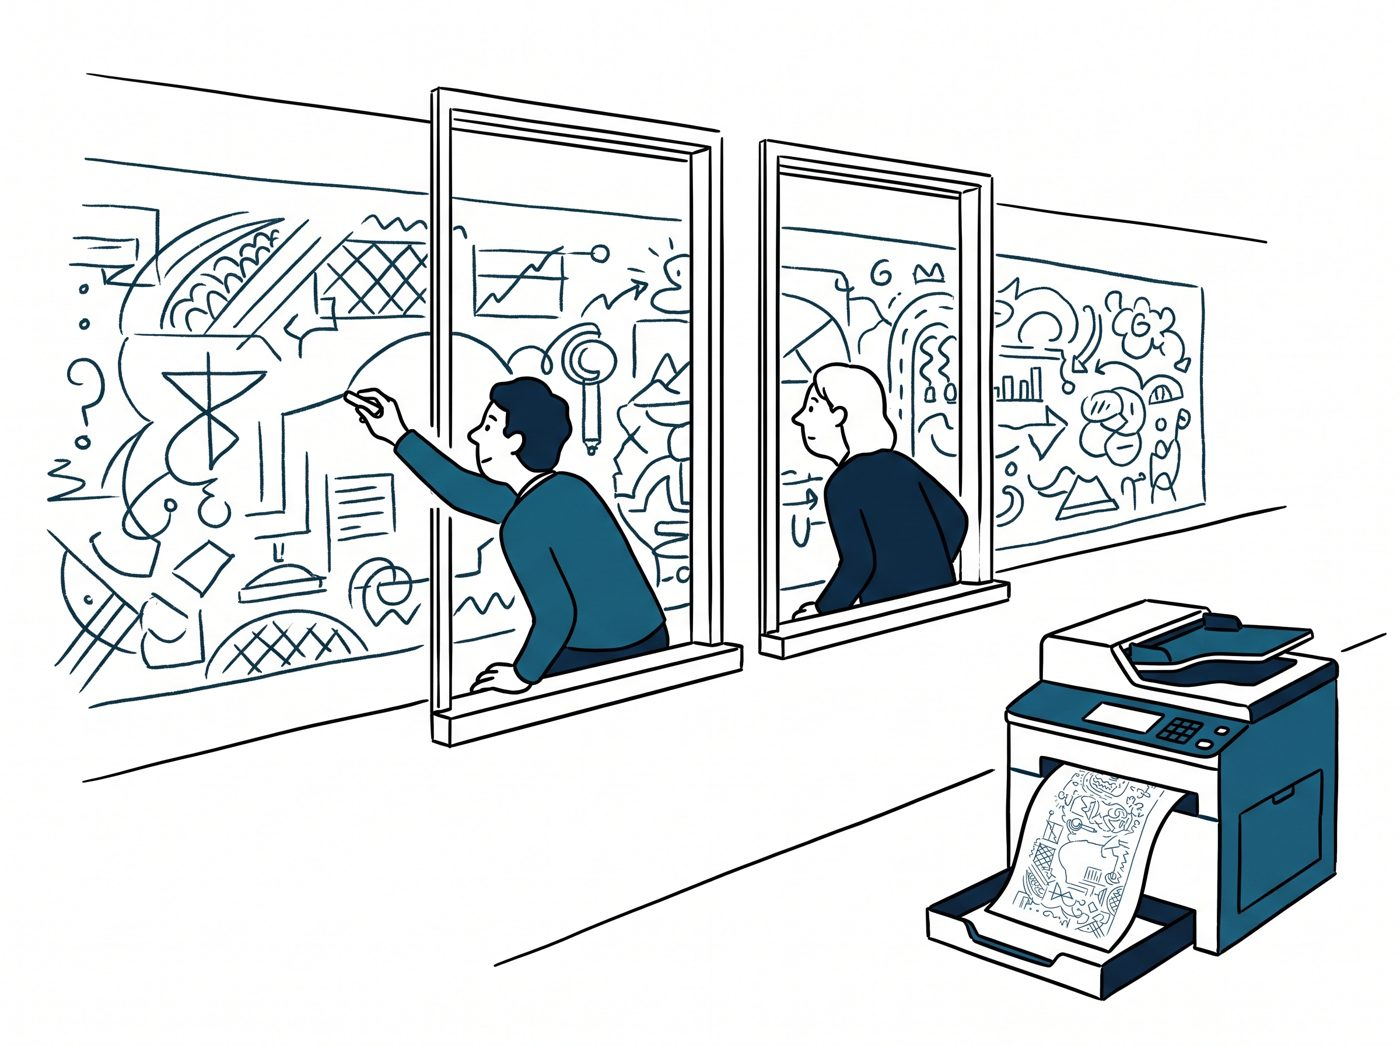<div style="text-align:center; color:#475569; font-size:0.92em; line-height:1.4; margin:-4px auto 14px; max-width:70%;">Zwei Fensterrahmen, eine Wandzeichnung: Eine Sicht zeigt denselben Datenblock, jeder neue Strich ist durch beide Rahmen zu sehen. Die Fotokopie ist die Kopie mit eigenem Datenblock, dort ändert sich nichts mit.</div></div>

Beim Lesen mit einem Indexarray oder einer Maske entsteht dagegen eine Kopie: `scores[best]` und `scores[mask]` haben eigene Datenblöcke, `scores[:3]` ist eine Sicht. Auch jede Rechnung wie `x / norms` legt ein neues Array an. Das unterscheidet die beiden Schreibweisen, die der Vertrag auseinanderhält: `x = x / norms` bindet den Namen an ein neues Array, das Original bleibt unverändert. `x /= norms` schreibt in das vorhandene Array. Ein Operator, der so rechnet, verletzt den Punkt „Die Eingabe bleibt unverändert", und das fällt erst auf, wenn eine spätere Zelle die Rohdaten braucht.

In [ ]:
x = np.array([[3.0, 4.0]], dtype=np.float32)
y = x / 5.0                           # neues Array, x bleibt
print(x, np.shares_memory(x, y))
x /= 5.0
print(x)
print(np.shares_memory(scores, scores[:3]), np.shares_memory(scores, scores[best]))

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">x <span style="color: #666">=</span> np<span style="color: #666">.</span>array([[<span style="color: #666">3.0</span>, <span style="color: #666">4.0</span>]], dtype<span style="color: #666">=</span>np<span style="color: #666">.</span>float32)
y <span style="color: #666">=</span> x <span style="color: #666">/</span> <span style="color: #666">5.0</span>                           <span style="color: #3D7B7B; font-style: italic"># neues Array, x bleibt</span>
<span style="color: #008000">print</span>(x, np<span style="color: #666">.</span>shares_memory(x, y))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">/=</code> rechnet im vorhandenen Array, ohne ein neues anzulegen</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">x <span style="color: #666">/=</span> <span style="color: #666">5.0</span>
<span style="color: #008000">print</span>(x)
<span style="color: #008000">print</span>(np<span style="color: #666">.</span>shares_memory(scores, scores[:<span style="color: #666">3</span>]), np<span style="color: #666">.</span>shares_memory(scores, scores[best]))</code></pre></details>

**Zeilenweise zusammenhängend.** Auch `E.T` ist eine Sicht: Es verwendet denselben Block, liest ihn aber mit vertauschten Abständen `(4, 1536)` statt `(1536, 4)`, also spaltenweise (Kapitel <a href="#kap-wie-die-zahlen-im-speicher-liegen">3.3.1</a>). Die Zahlen einer Zeile von `E.T` liegen im Speicher deshalb nicht hintereinander, sondern jeweils 1536 Bytes auseinander. NumPy kann damit rechnen; ob das langsamer ist, hängt von der Operation und davon ab, in welcher Richtung sie den Speicher durchläuft. Das Attribut `flags["C_CONTIGUOUS"]` sagt, ob die Zeilen eines Arrays dicht hintereinander im Speicher liegen, so wie die Sprache C ein zweidimensionales Array ablegt. `np.ascontiguousarray` liefert eine zeilenweise zusammenhängende Fassung; liegt das Array schon so vor, gibt es dasselbe Array zurück, es ersetzt `.copy()` also nicht.

**Wann `reshape` kopieren muss.** Eine Sicht kann nur Formen darstellen, die sich mit einem festen Abstand je Achse auf dem vorhandenen Block beschreiben lassen. `E.reshape(-1)` ist deshalb eine Sicht: Alle 153.600 Zahlen liegen im Block schon zeilenweise hintereinander, der Abstand ist einfach 4 Bytes. `E.T.reshape(-1)` müsste dagegen die Zahlen spaltenweise aneinanderreihen, also erst `E[0, 0]`, dann `E[1, 0]`, dann `E[2, 0]` und nach 400 Schritten mit `E[0, 1]` wieder vorn beginnen. Dafür gibt es keinen festen Abstand, also legt NumPy einen neuen Block mit den Zahlen in dieser Reihenfolge an. Beide Ergebnisse enthalten alle Werte, aber in verschiedener Reihenfolge (zeilenweise gegen spaltenweise); außerdem teilt das erste den Speicher mit `E`, das zweite nicht.

In [ ]:
print(E.strides, E.T.strides)
print(E.flags["C_CONTIGUOUS"], E.T.flags["C_CONTIGUOUS"], np.shares_memory(E, E.T))
print(np.shares_memory(E, E.reshape(-1)), np.shares_memory(E, E.T.reshape(-1)))
ET = np.ascontiguousarray(E.T)
print(ET.flags["C_CONTIGUOUS"], np.shares_memory(E, ET))
print(np.ascontiguousarray(E) is E)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(E<span style="color: #666">.</span>strides, E<span style="color: #666">.</span>T<span style="color: #666">.</span>strides)
<span style="color: #008000">print</span>(E<span style="color: #666">.</span>flags[<span style="color: #BA2121">"C_CONTIGUOUS"</span>], E<span style="color: #666">.</span>T<span style="color: #666">.</span>flags[<span style="color: #BA2121">"C_CONTIGUOUS"</span>], np<span style="color: #666">.</span>shares_memory(E, E<span style="color: #666">.</span>T))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">reshape</code> liefert eine Sicht, wenn die neue Form zu den Abständen passt, sonst eine Kopie</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(np<span style="color: #666">.</span>shares_memory(E, E<span style="color: #666">.</span>reshape(<span style="color: #666">-1</span>)), np<span style="color: #666">.</span>shares_memory(E, E<span style="color: #666">.</span>T<span style="color: #666">.</span>reshape(<span style="color: #666">-1</span>)))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">np.ascontiguousarray</code> kopiert nur, wenn es nötig ist</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">ET <span style="color: #666">=</span> np<span style="color: #666">.</span>ascontiguousarray(E<span style="color: #666">.</span>T)
<span style="color: #008000">print</span>(ET<span style="color: #666">.</span>flags[<span style="color: #BA2121">"C_CONTIGUOUS"</span>], np<span style="color: #666">.</span>shares_memory(E, ET))
<span style="color: #008000">print</span>(np<span style="color: #666">.</span>ascontiguousarray(E) <span style="color: #A2F; font-weight: bold">is</span> E)</code></pre></details>

Damit lässt sich der letzte Punkt des Vertrags einlösen. Die nächste Vorgabe-Zelle ergänzt `check_input` um die Prüfung auf zeilenweise zusammenhängenden Speicher. Ihre Funktion `row_l2_normalize` ruft `check_input` beim Aufruf auf und bekommt die neue Prüfung damit automatisch. Der Operator ist vollständig.

In [ ]:
# Vorgabe: check_input mit der letzten Vertragsprüfung — einfach ausführen
def check_input(x, eps):
    if x.ndim != 2:
        raise ValueError(f"Eingabe muss zwei Achsen haben, hat {x.ndim}")
    if x.dtype != np.float32:
        raise ValueError(f"Eingabe muss float32 sein, ist {x.dtype}")
    if x.shape[1] == 0:
        raise ValueError("Eingabe muss mindestens eine Spalte haben (D > 0)")
    eps32 = np.float32(eps)
    if not np.isfinite(eps32) or eps32 <= 0:
        raise ValueError(f"eps muss in float32 positiv und endlich sein, ist {eps}")
    if not x.flags["C_CONTIGUOUS"]:
        raise ValueError("Eingabe muss zeilenweise zusammenhängend sein (np.ascontiguousarray)")

print(row_l2_normalize(np.ascontiguousarray(E.T[:2])).shape, "<- E.T selbst würde abgewiesen")

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>Drei Zellen, dreimal die Frage: Verändert sich <code style="color:inherit;">a</code>? Legen Sie sich für jede fest, bevor Sie die nächste Zelle ausführen.</p>
<pre><code class="language-python">a = np.arange(1.0, 6.0); b = a[2:]; b[0] = 0.0                 # 1
a = np.arange(1.0, 6.0); b = a[np.array([2, 3])]; b[0] = 0.0   # 2
a = np.arange(1.0, 6.0); b = a.copy(); b[0] = 0.0              # 3
</code></pre>

</div>

In [ ]:
# Tragen Sie Ihre Vorhersagen ein (True = a verändert sich), dann ausführen
prediction = {1: None, 2: None, 3: None}
a = np.arange(1.0, 6.0); b = a[2:]; b[0] = 0.0;               changed_1 = a[2] == 0.0
a = np.arange(1.0, 6.0); b = a[np.array([2, 3])]; b[0] = 0.0; changed_2 = a[2] == 0.0
a = np.arange(1.0, 6.0); b = a.copy(); b[0] = 0.0;            changed_3 = a[0] == 0.0
for case, changed in zip((1, 2, 3), (changed_1, changed_2, changed_3)):
    assert prediction[case] == changed, f"Fall {case}: a verändert sich {'' if changed else 'nicht'}"
print("Alle Vorhersagen stimmen ✓")

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">5 min</span>✏️ Aufgabe 3.7 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Tragen Sie für die vier Ausdrücke in der Zelle darunter ein: die Form als Tupel, ob das Ergebnis eine Sicht auf <code style="color:inherit;">E</code> ist, und ob es zeilenweise zusammenhängend ist. Die Prüfzelle vergleicht mit den tatsächlichen Werten.</p>
<p>Wer früher fertig ist: Schreiben Sie in einer neuen Zelle einen Test, der prüft, dass <code style="color:inherit;">row_l2_normalize(E.T)</code> mit einem <code style="color:inherit;">ValueError</code> abbricht. Das Muster mit <code style="color:inherit;">try</code> und <code style="color:inherit;">except ValueError</code> steht in der Prüfzelle zu <code style="color:inherit;">row_l2_normalize</code>.</p>

</div>
</div>

In [ ]:
# Je Ausdruck: Form als Tupel, Sicht auf E (True/False), zeilenweise zusammenhängend (True/False)
# Beispiel für einen Eintrag:  "E[:5]": ((5, 384), True, True)
#   E[:5] hat 5 Zeilen und 384 Spalten, ist eine Sicht auf E, und seine Zeilen liegen dicht hintereinander.
guess = {
    "E[:10]":        (None, None, None),
    "E[:, :10]":     (None, None, None),
    "E.T":           (None, None, None),
    "E[:10].copy()": (None, None, None),
}

In [ ]:
# Prüfzelle — einfach ausführen
actual = {"E[:10]": E[:10], "E[:, :10]": E[:, :10], "E.T": E.T, "E[:10].copy()": E[:10].copy()}
for name, arr in actual.items():
    shape, view, contiguous = guess[name]
    assert arr.shape == shape, f"{name}: Form {arr.shape}"
    assert np.shares_memory(E, arr) == view, f"{name}: Sicht ist {np.shares_memory(E, arr)}"
    assert arr.flags["C_CONTIGUOUS"] == contiguous, f"{name}: zeilenweise zusammenhängend ist {arr.flags['C_CONTIGUOUS']}"
print("Alle Vorhersagen stimmen ✓")

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Sicht oder Kopie</span></div>
<table>
<thead>
<tr>
<th>Ausdruck</th>
<th>Ergebnis</th>
</tr>
</thead>
<tbody>
<tr>
<td>Slice <code style="color:inherit;">a[1:4]</code>, <code style="color:inherit;">E.T</code>, <code style="color:inherit;">reshape</code> wenn möglich</td>
<td>Sicht: gleicher Datenblock, Schreiben ändert das Original</td>
</tr>
<tr>
<td><code style="color:inherit;">scores[mask]</code>, <code style="color:inherit;">scores[indices]</code> beim Lesen, <code style="color:inherit;">astype</code> (Voreinstellung <code style="color:inherit;">copy=True</code>), <code style="color:inherit;">flatten</code> (wie <code style="color:inherit;">reshape(-1)</code>, aber immer eine Kopie), jede Rechnung wie <code style="color:inherit;">x / norms</code></td>
<td>Kopie oder neues Ergebnisarray: eigener Datenblock</td>
</tr>
<tr>
<td><code style="color:inherit;">a.copy()</code></td>
<td>Kopie, ausdrücklich</td>
</tr>
<tr>
<td><code style="color:inherit;">x = x / norms</code></td>
<td>neues Array; <code style="color:inherit;">x</code> wird neu gebunden, das ursprüngliche Array bleibt unverändert</td>
</tr>
<tr>
<td><code style="color:inherit;">x /= norms</code></td>
<td>ändert das vorhandene Array; andere Namen und Sichten darauf sehen die Änderung</td>
</tr>
</tbody>
</table>
<p>Prüfen mit <code style="color:inherit;">np.shares_memory(a, b)</code>. Zeilenweise zusammenhängend: <code style="color:inherit;">a.flags["C_CONTIGUOUS"]</code>; <code style="color:inherit;">np.ascontiguousarray(a)</code> stellt es her und kopiert nur, wenn nötig.</p>

</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right"><span style="border:1px solid rgba(255,255,255,0.85); color:#fff; font-size:0.72em; font-weight:bold; padding:1px 9px; border-radius:10px; margin-left:8px; vertical-align:1px;">NICHT PRÜFUNGSRELEVANT</span></span>Vertiefung: Was NumPy außerdem mitbringt</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Für einige Muster bringt NumPy fertige Werkzeuge mit, die in dieser Lerneinheit nicht gebraucht werden. In fremdem Code und in späteren Lerneinheiten begegnen sie Ihnen, deshalb zeigt diese Box je ein Beispiel.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#107C72; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #107C7255"><p><strong>Elementweise auswählen.</strong> <code style="color:inherit;">np.where(mask, a, b)</code> nimmt an jeder Position den Eintrag aus <code style="color:inherit;">a</code>, wo die Maske <code style="color:inherit;">True</code> ist, sonst den aus <code style="color:inherit;">b</code>:</p>
<pre><code class="language-python">s = np.array([0.1, 0.9, 0.5])
np.where(s &gt;= 0.5, s, 0.0)          # [0.0, 0.9, 0.5]: kleine Werte auf 0 gesetzt
</code></pre>
<p><strong>Summen über Achsen in Indexschreibweise.</strong> <code style="color:inherit;">np.einsum</code> beschreibt mit einer Zeichenkette, welche Achsen multipliziert und welche aufsummiert werden. <code style="color:inherit;">"ij,ij-&gt;i"</code> ist das Skalarprodukt je Zeile, <code style="color:inherit;">"qd,nd-&gt;qn"</code> das Matrixprodukt <code style="color:inherit;">Qn @ En.T</code>:</p>
<pre><code class="language-python">Qn, En = row_l2_normalize(Q), row_l2_normalize(E)
np.einsum(&quot;ij,ij-&gt;i&quot;, E, E)         # Quadratsummen je Zeile, Form (400,)
np.einsum(&quot;qd,nd-&gt;qn&quot;, Qn, En)      # dasselbe wie Qn @ En.T, Form (8, 400)
</code></pre>
<p><strong>Mehrere Indexarrays zugleich.</strong> Ein Indexarray je Achse wählt beliebige Einträge einer Matrix aus; das Puzzle <code style="color:inherit;">diag</code> im Kapitel <a href="#kap-zum-weiterueben">3.8</a> zeigt den einfachsten Fall:</p>
<pre><code class="language-python">rows = np.array([0, 2])
cols = np.array([1, 3])
M[rows, cols]                       # [M[0, 1], M[2, 3]] = [2, 12]
</code></pre></div></details>
</div>
</div>

## <a id="kap-zum-weiterueben"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">3.8&nbsp;&nbsp;Zum Weiterüben</span>

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<p>Die folgenden Aufgaben sind Tensor Puzzles nach Sasha Rush (Cornell Tech), auf NumPy übertragen. Das Original ist eine Sammlung von 21 Rätseln für PyTorch, frei verfügbar unter <a href="https://github.com/srush/Tensor-Puzzles">github.com/srush/Tensor-Puzzles</a> (MIT-Lizenz, siehe Quellenblock). Jede Aufgabe baut ein bekanntes Werkzeug von NumPy mit Broadcasting, Masken und Indexarrays nach, ohne Schleife und in einer Zeile. Die Einzeiler-Regel ist eine Übungsbedingung wie im Original, keine Empfehlung für möglichst kompakten Code. Lesbarer Code mit mehreren Zeilen ist im Kurs immer erlaubt.</p>
<p>Erlaubte Werkzeuge, je mit einem Beispiel:</p>
<ul>
<li><code style="color:inherit;">np.arange(n)</code> zählt von 0 bis n−1</li>
<li>Vergleiche liefern Masken: <code style="color:inherit;">np.arange(4) &lt; 2</code> ist <code style="color:inherit;">[True, True, False, False]</code></li>
<li><code style="color:inherit;">[:, None]</code> und <code style="color:inherit;">[None, :]</code> fügen Achsen ein: <code style="color:inherit;">a[:, None] * b[None, :]</code> ist das Produkt jedes Eintrags von <code style="color:inherit;">a</code> mit jedem von <code style="color:inherit;">b</code></li>
<li>Rechenzeichen und <code style="color:inherit;">@</code>, <code style="color:inherit;">sum</code> mit <code style="color:inherit;">axis=</code></li>
<li>zwei Indexarrays gleichzeitig: <code style="color:inherit;">A[np.array([0, 1]), np.array([1, 0])]</code> liefert <code style="color:inherit;">A[0, 1]</code> und <code style="color:inherit;">A[1, 0]</code></li>
</ul>
<p>Verboten ist jeweils das Werkzeug, das nachgebaut wird (<code style="color:inherit;">np.ones</code>, <code style="color:inherit;">np.outer</code>, <code style="color:inherit;">np.eye</code>, <code style="color:inherit;">np.diag</code>). Die Lösungen erscheinen mit den Lösungen des Termins.</p>

</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">Weiterüben</span>✏️ Aufgabe 3.8 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p><strong>Puzzle 1: ones.</strong> Schreiben Sie <code style="color:inherit;">ones(n)</code>, das ein Array aus <code style="color:inherit;">n</code> Einsen liefert, ohne <code style="color:inherit;">np.ones</code> und ohne <code style="color:inherit;">np.full</code>.</p>

</div>
</div>

In [ ]:
def ones(n):
    # TODO: Ihre Lösung hier
    ...

In [ ]:
# Prüfzelle — einfach ausführen
assert np.array_equal(ones(4), [1, 1, 1, 1]) and ones(0).shape == (0,)
print("Alle Prüfungen bestanden ✓")

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">Weiterüben</span>✏️ Aufgabe 3.8 #2</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p><strong>Puzzle 2: outer.</strong> Schreiben Sie <code style="color:inherit;">outer(a, b)</code>, das für zwei eindimensionale Arrays die Matrix aller Produkte <code style="color:inherit;">a[i] * b[j]</code> liefert, Form <code style="color:inherit;">(len(a), len(b))</code>, ohne <code style="color:inherit;">np.outer</code> und ohne <code style="color:inherit;">@</code>.</p>

</div>
</div>

In [ ]:
def outer(a, b):
    # TODO: Ihre Lösung hier
    ...

In [ ]:
# Prüfzelle — einfach ausführen
assert np.array_equal(outer(np.array([1, 2]), np.array([10, 20, 30])), [[10, 20, 30], [20, 40, 60]])
print("Alle Prüfungen bestanden ✓")

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">Weiterüben</span>✏️ Aufgabe 3.8 #3</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p><strong>Puzzle 3: eye.</strong> Schreiben Sie <code style="color:inherit;">eye(n)</code>, das die Einheitsmatrix der Form <code style="color:inherit;">(n, n)</code> liefert (Einsen auf der Diagonalen, sonst Nullen), ohne <code style="color:inherit;">np.eye</code> und ohne <code style="color:inherit;">np.identity</code>. Eine Maske lässt sich mit <code style="color:inherit;">* 1</code> in Zahlen umwandeln.</p>

</div>
</div>

In [ ]:
def eye(n):
    # TODO: Ihre Lösung hier
    ...

In [ ]:
# Prüfzelle — einfach ausführen
assert np.array_equal(eye(3), [[1, 0, 0], [0, 1, 0], [0, 0, 1]])
print("Alle Prüfungen bestanden ✓")

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">Weiterüben</span>✏️ Aufgabe 3.8 #4</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p><strong>Puzzle 4: diag.</strong> Schreiben Sie <code style="color:inherit;">diag(A)</code>, das die Diagonale einer quadratischen Matrix als eindimensionales Array liefert, ohne <code style="color:inherit;">np.diag</code> und ohne <code style="color:inherit;">np.diagonal</code>.</p>

</div>
</div>

In [ ]:
def diag(A):
    # TODO: Ihre Lösung hier
    ...

In [ ]:
# Prüfzelle — einfach ausführen
assert np.array_equal(diag(np.array([[1, 2], [3, 4]])), [1, 4])
print("Alle Prüfungen bestanden ✓")

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#E8B029; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">➡️ Nächste Schritte</div>
<div style="background:#FDF6E3; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<ul>
<li>Beenden Sie die Aufgaben, die im Termin offen geblieben sind. Zur Schlusskontrolle starten Sie die Laufzeit neu und führen die Zellen bis zum Ende des Kapitels <a href="#kap-sicht-oder-kopie">3.7</a> aus: Alle Prüfzellen bis dorthin sollten mit Ihren eigenen Lösungen durchlaufen. Die Prüfzellen im Kapitel „Zum Weiterüben" zählen nur, wenn Sie die Puzzles bearbeitet haben.</li>
<li>In der Woche ohne Termin folgen Teil 3 des Python-Grundkurses (Dateien, Fehlerbehandlung, Funktionen, Module und Klassen) und die Projektaufgabe: ein kleines Suchwerkzeug von der Datei bis zur geprüften Trefferliste, aufgebaut auf der Suche aus diesem Notebook. Beides kommt mit der nächsten E-Mail.</li>
<li>Die Referenzkarte NumPy fasst NumPy auf zwei Seiten zusammen.</li>
</ul>
<p><strong>→ Ausblick:</strong> In der nächsten Lerneinheit kommen pandas und Matplotlib: Daten einlesen, bereinigen, zusammenfassen und darstellen.</p>

</div>
</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#E8B029; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Quellen und Referenzen</div>
<div style="background:#FDF6E3; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<ul>
<li>J. VanderPlas: <em>Python Data Science Handbook</em>, 2. Auflage, Kapitel 4 bis 11 (NumPy: Datentypen, Arrays, Ufuncs, Aggregationen, Broadcasting, Masken, Fancy Indexing, Sortieren). Online frei verfügbar.</li>
<li>W. McKinney: <em>Python for Data Analysis</em>, 3. Auflage, Kapitel 4 und Anhang A (ndarray-Interna, strides, Broadcasting, partielles Sortieren, zusammenhängender Speicher).</li>
<li>M. Gorelick, I. Ozsvald: <em>High Performance Python</em>, 3. Auflage, Kapitel 6 (Zwischenresultate, In-Place-Operationen).</li>
<li>NumPy-Dokumentation: <a href="https://numpy.org/doc/stable/user/basics.broadcasting.html">Broadcasting</a>, <a href="https://numpy.org/doc/stable/user/basics.copies.html">Copies and views</a>, <a href="https://numpy.org/doc/stable/user/basics.indexing.html">Indexing</a>, <a href="https://numpy.org/doc/stable/reference/generated/numpy.ndarray.flags.html"><code style="color:inherit;">ndarray.flags</code></a>, <a href="https://numpy.org/doc/stable/reference/generated/numpy.argsort.html"><code style="color:inherit;">numpy.argsort</code></a>.</li>
<li>C. R. Harris et al.: <em>Array programming with NumPy</em>, Nature 585 (2020), 357–362.</li>
<li>S. Rush: <a href="https://github.com/srush/Tensor-Puzzles">Tensor Puzzles</a> (MIT-Lizenz). Die Aufgaben im Kapitel „Zum Weiterüben" folgen dieser Idee und sind auf NumPy übertragen.</li>
<li>Datengrundlage: <a href="https://huggingface.co/datasets/deepset/germanquad">GermanQuAD</a> (deepset), Lizenz CC BY 4.0. Die Absatztexte stammen aus der deutschen Wikipedia (CC BY-SA). Attribution auch in <code style="color:inherit;">data/appetizer_passages.json</code>.</li>
</ul>
<p style="font-size:0.88em; font-style:italic; color:#5a6472; margin:12px 0 0;">Dieses Material wurde mit Unterstützung von KI-Werkzeugen entwickelt (Text und Code: Claude und ChatGPT, Karikaturen: Google Gemini). Alle Inhalte sind von Prof. Dr. Stephan Kurpjuweit konzipiert, geprüft und verantwortet.</p>

</div>
</div>